<a href="https://colab.research.google.com/github/sscs-ose/sscs-ose-code-a-chip.github.io/blob/main/ISSCC27/submitted_notebooks/SiliconForge/SiliconForge_Code_a_Chip.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SiliconForge
## Systolic Accelerator IP Core Design
### IEEE SSCS PICO Chipathon 2026 • Team A34(Chipathon Team) • Code-a-Chip ISSCC 2027

**Architecture, schematic design, RTL organization, functional simulation and physical design**  
**Technology target:** GF180MCU • **AI-Accelerator (Systolic):** Parameterized • **Demonstrated array:** 4×4 • **License:** Apache-2.0

| Team member | Affiliation | Contribution |
|---|---|---|
| Muhammad Waleed Akram | University of Engineering and Technology, Lahore | Team lead; module RTL, verification, interfaces and chip wrapper |
| Abdul Muiz | University of Engineering and Technology, Lahore | Systolic top RTL, verification and optimization |
| Rumali Siddiqua | University of Virginia, USA | Physical design |
| Nur Cahyo Ihsan Prastyawan | Universitas Gadjah Mada, Indonesia | MAC RTL, verification and FPGA synthesis |

**Project:** [chipathon-2026-systolic-ip-core](https://github.com/Waleed99i/chipathon-2026-systolic-ip-core/tree/a34-rtl-fix-pd)  
**RTL sources:** [src/rtl/](https://github.com/Waleed99i/chipathon-2026-systolic-ip-core/tree/a34-rtl-fix-pd/src/rtl) • **Testbenches:** [src/tb/](https://github.com/Waleed99i/chipathon-2026-systolic-ip-core/tree/a34-rtl-fix-pd/src/tb) • **Figures:** [docs/](https://github.com/Waleed99i/chipathon-2026-systolic-ip-core/tree/a34-rtl-fix-pd/docs)  
**Designated travel representative:** Rumali Siddiqua, University of Virginia, USA  
**Team lead / project contact:** Muhammad Waleed Akram · waleedakram059@gmail.com

## 1. Project overview

SiliconForge is a systolic matrix accelerator developed for the IEEE SSCS PICO Open-Source Chipathon 2026. The design organizes multiply-accumulate processing elements in a regular two-dimensional array so that operands can move between neighboring elements while partial sums remain local. Matrix multiplication is the central workload, with potential use in dense linear algebra, DSP and machine-learning computation. Our project was also been nominated for the tapeout in September Shuttle by GlobalFoundries, delayed to the December shuttle now.

Its a parametrized AI-Accelerator.The demonstrated architecture uses **sixteen processing elements in a 4×4 grid**. Each PE receives two FP16-encoded operands, performs approximate multiplication, and accumulates a fixed-point result. Data feeders align the operand streams; input and output datapaths manage the buffers and transactions. The chip-level interface uses eight input data pins and four output data pins to communicate wider internal operands and results.

This notebook presents the team's schematic-review material alongside its RTL organization, simulation waveforms, selected functional check transcripts and plots. Physical-design content and the MAC accuracy study have their own sections at the end for the corresponding teammates to complete.

### Design objectives

- Organize the accelerator into reusable arithmetic, PE, feeder, register, counter and interface blocks.
- Explore an N×N architecture with a 4×4 integrated demonstration.
- Accept 16-bit floating-point encodings and retain 32-bit fixed-point accumulated results.
- Use packetized data movement to fit the application pin assignment.
- Document the design using open-source RTL simulation and an openly licensed notebook.

## 2. Design specifications and pin assignment

| Property | Configuration |
|---|---|
| Team / track | A34 SiliconForge / Track A, digital |
| Array | 4×4; 16 processing elements |
| Operand encoding | FP16, 16 bits |
| Multiplier | Approximate logarithmic mantissa arithmetic |
| Converted product | Signed Q16.16 |
| Accumulation / PE result | 32-bit Q16.16 |
| Internal input packet | 128 bits: one A row and one B column |
| Input packets per matrix pair | Four |
| Row/column feeder | Seven 16-bit words, including skew padding |
| Collected result | 512 bits: sixteen 32-bit elements |
| External input data | Eight bits per byte |
| External output data | Four bits per transfer; 128 transfers |
| Clock / reset | `clk` / active-low `rst_n` at the wrapper |
| Process target | GF180MCU |

### 16-pin application interface

| Pin(s) | Signal | Direction / type | Role |
|---|---|---|---|
| 1 | `clk` | Input | Sampling and computation clock |
| 2 | `rst_n` | Input | Active-low wrapper reset |
| 3–10 | `data_in[7:0]` | Input | Byte-wide operand input |
| 11–14 | `data_out[3:0]` | Output | Nibble-wide result output |
| 15 | `VDD` | Power | Supply |
| 16 | `GND` | Ground | Ground reference |

The assignment totals **16 pins: 14 signal pins and 2 power pins**. Pad-control terminals in the organizer-facing RTL wrapper configure the I/O cells; they are separate from this application-level pin budget.

**Figure 1.** Pin-count breakdown derived from the team README: 8 input + 4 output + clock + reset + supply + ground = 16.

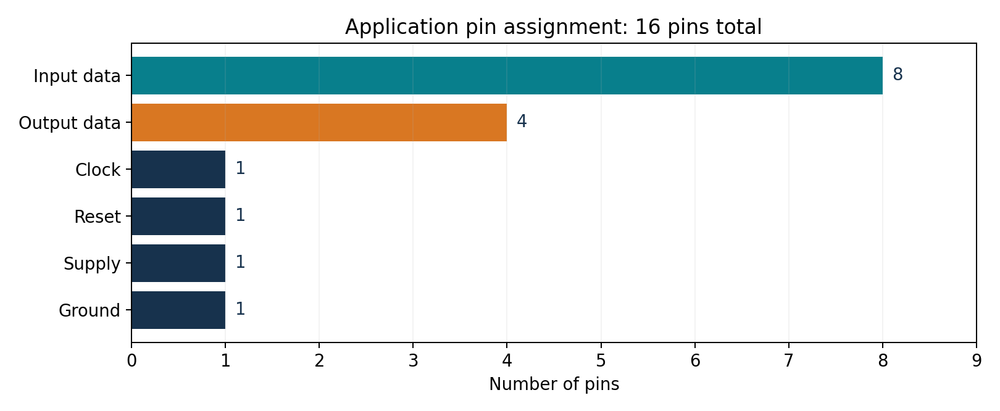

In [ ]:
# @title Figure 1
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

## 3. Overall schematic and data movement

A matrix transaction moves through three main stages. First, input acquisition assembles row/column packets. Second, the input datapath and feeders present temporally aligned operands to the array. Finally, the result datapath captures the sixteen PE results and serializes them for readout.

For packet index i, the upper 64 bits hold row i of A and the lower 64 bits hold column i of B. This packs eight FP16 words into a 128-bit packet. Four packets describe both 4×4 operand matrices. After result collection, the 512-bit bus is emitted as 128 four-bit transfers.

The first figure is the team's full array schematic. The second is the supplied packet-flow diagram, which makes the byte input, 128-bit internal packet and nibble output widths explicit. Its ready/valid annotations describe logical transactions; the current pad wrapper manages acquisition and output timing internally.

**Figure 2.** Team system schematic: input datapath, eight feeders, a 4×4 PE array, output datapath and controller.

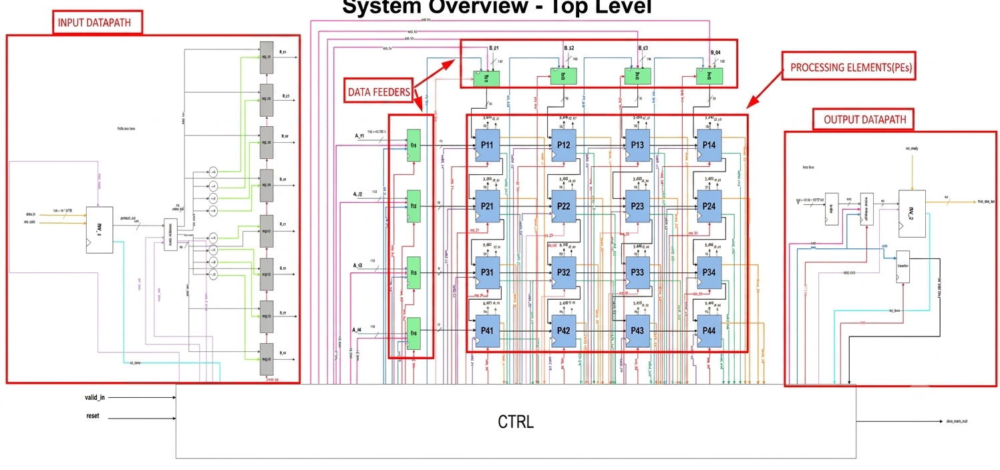

In [ ]:
# @title Figure 2
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "AElFTkSuQmCC"
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

**Figure 3.** Supplied packet-flow diagram: 8-bit input → 128-bit packet → systolic computation → 512-bit result → 4-bit output.

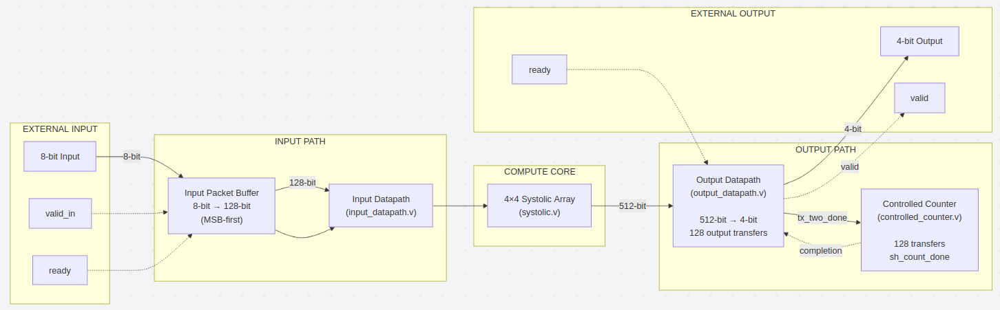

In [ ]:
# @title Figure 3
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "Cfx/kzLQ5W0c5isAAAAASUVORK5CYII="
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

## 4. RTL hierarchy and file flow

The RTL hierarchy below connects the wrapper, packet handling, systolic controller, arithmetic and output collection. It is included once as a complete file-flow reference.

**Source directories:** [RTL](https://github.com/Waleed99i/chipathon-2026-systolic-ip-core/tree/a34-rtl-fix-pd/src/rtl) • [Chip wrapper](https://github.com/Waleed99i/chipathon-2026-systolic-ip-core/tree/a34-rtl-fix-pd/src/chipathon_wrapper) • [Testbenches](https://github.com/Waleed99i/chipathon-2026-systolic-ip-core/tree/a34-rtl-fix-pd/src/tb)

**Figure 4.** RTL hierarchy: chip wrapper → systolic top → input/output datapaths, feeders and PE array → MAC (approximate multiplier and `fp16_to_q16_16` converter) and supporting primitives.

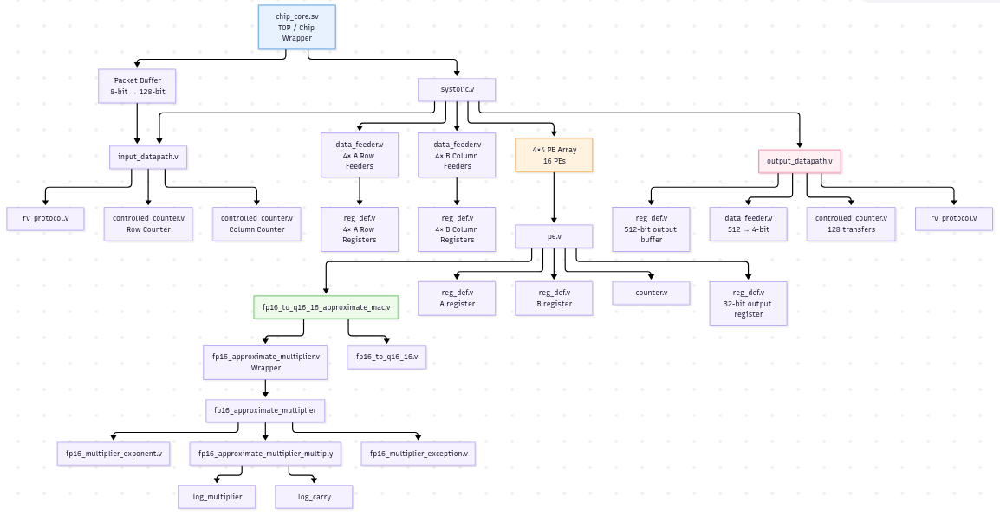

In [ ]:
# @title Figure 4
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "AIAo8f9JZr8M85rq8wAAAABJRU5ErkJggg=="
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

### RTL file map

| Layer | Files | Function |
|---|---|---|
| Chip wrapper | `src/chipathon_wrapper/chip_core.sv` | Application I/O mapping, byte collection, packet control and output count |
| Array / controller | `systolic.v` | 4×4 PE interconnect, feeder control, completion reduction and transaction FSM |
| Input path | `input_datapath.v`, `input_serializer.sv` | Row/column packet handling and reusable byte-to-packet serializer |
| Output path | `output_datapath.v` | Result buffering and nibble serialization |
| Operand movement | `data_feeder.v` | Parallel load and MSB-first shifting |
| Processing element | `pe.v` | MAC, operand-forwarding registers, completion counter and result register |
| MAC | `fp16_to_q16_16_approximate_mac.v` | Approximate product conversion and accumulated sum |
| Multiplier | `fp16_approximate_multiplier.v` | FP16 wrapper, log multiplier, log carry and mantissa path |
| Exponent / exceptional encodings | `fp16_multiplier_exponent.v`, `fp16_multiplier_exception.v` | Product exponent and zero/special-input handling |
| Product conversion | `fp16_to_q16_16.v` | Convert FP16 product directly   to signed Q16.16 (32bits) |
| Registers / counters / transactions | `reg_def.v`, `counter.v`, `controlled_counter.v`, `rv_protocol.v` | Storage, progress counting and registered transfer control |
| Conversion utilities | `fp16_to_fp32.v`, `fp32_to_fp16.v`, `q16_16_to_fp16.v`, `q16_16_to_fp32.v` | Numeric-format utilities used in supporting conversion and testbench flows |

Several leaf modules expose N or width parameters. The presented integrated array is the four-row/four-column instance illustrated in the schematic.

## 5. MAC unit

The MAC contains an approximate floating-point product path followed by fixed-point conversion and accumulation. The FP16 inputs are divided into sign, exponent and mantissa fields. The mantissa path uses logarithmic encoding, addition and decoding; exponent handling and sign XOR form the product encoding The product is directly converted to signed Q16.16 which is then being added to the 32-bit sum. The wider sum increases the available accumulation range.

### Interface and transaction

| Signal | Purpose |
|---|---|
| `a`, `b` | Two 16-bit FP16 operand encodings |
| `valid` | Request a MAC transaction |
| `clk`, `reset` | Clock and accumulator/controller reset |
| `result` | 32-bit result |
| `done` | Indicates the accumulated result is available |

The three-state FSM is **IDLE → ACCUMULATE → DONE**. A valid request moves the MAC out of IDLE; the following accumulation edge updates the sum and raises done. Holding valid high in DONE retains the result. Lowering valid releases the transaction for another operation. The operands are held stable across the request and accumulation edges.

The schematic, FSM and waveform below show the datapath and control together. The quantitative MAC accuracy study follows the figures.

**Figure 5.** MAC design: operand registers, approximate FP16 multiplier, direct FP16-to-Q16.16 conversion and 32-bit Q16.16 accumulation under the MAC controller.

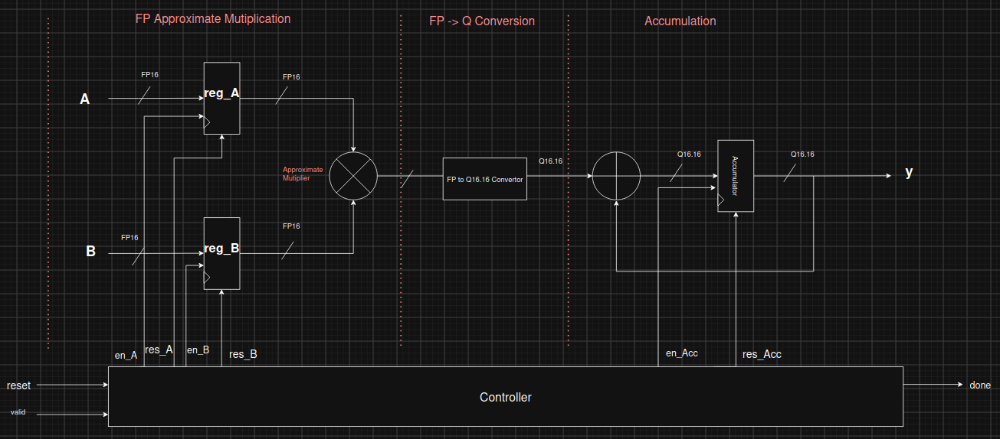

In [ ]:
# @title Figure 5
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "aGcS6AAAAABJRU5ErkJggg=="
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

**Figure 6.** MAC accumulation state-transition diagram from the schematic review.

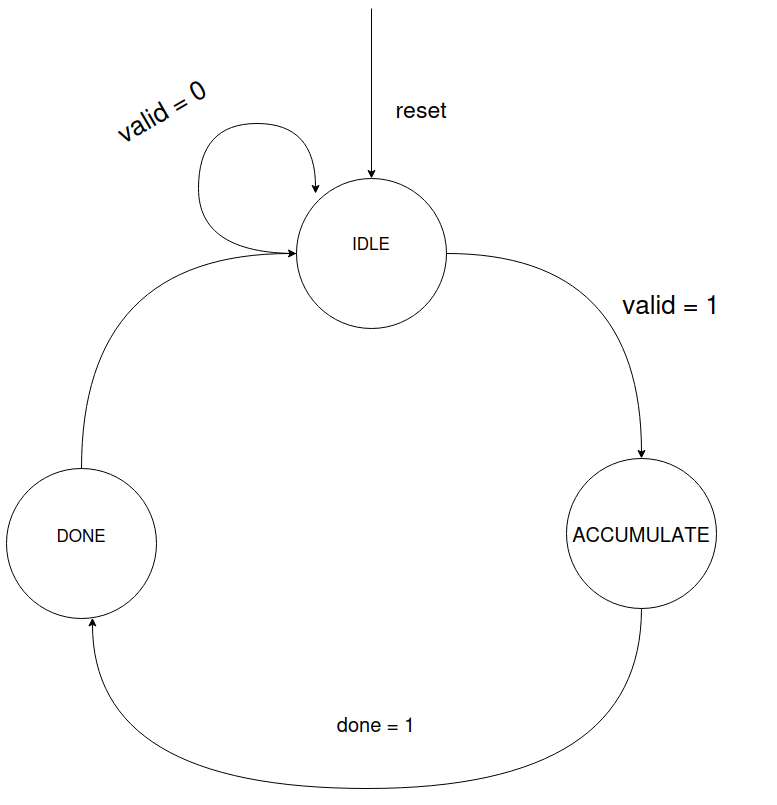

In [ ]:
# @title Figure 6
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "B7wQAAAAAElFTkSuQmCC"
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

**Figure 7.** Team MAC waveform on the current RTL: FP16 operands `a` and `b`, approximate product `mul_res`, converted Q16.16 value `q16_16`, valid/done control, FSM state and the accumulated 32-bit `result` (0x6480 → 0x9E70 → 0xF560).

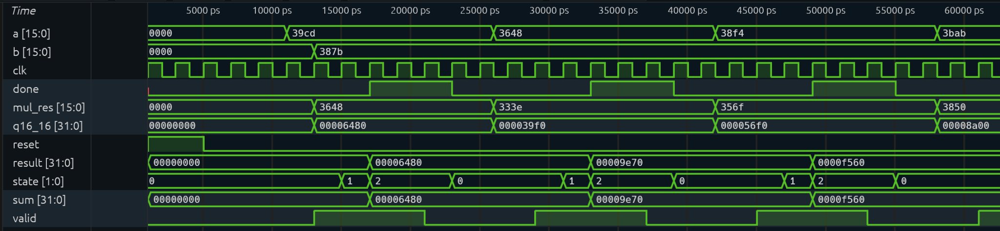

In [ ]:
# @title Figure 7
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

### MAC accuracy

The MAC multiplies two half-precision (FP16) numbers without a real multiplier. It uses this rule: adding logarithms is the same as multiplying, log(a·b) = log(a) + log(b). The FP16 product is then changed by a converter into a fixed-point number and added to a 32-bit Q16.16 total. The team chose this design because it is small. The price is an error. This report measures that error.

```
FP16 a ─┐
        ├─► approximate multiplier ─► FP16 product ─► converter ─► 32-bit Q16.16 total
FP16 b ─┘
```

We test the multiplier alone first. Then we test the converter and the adding (accumulator).

#### 5.1 Number formats

| Item | Value |
|---|---|
| Inputs | IEEE-754 binary16 (FP16): 1 sign bit, 5 exponent bits (bias 15), 10 mantissa bits |
| Multiplier output | binary16 (FP16) |
| Total (accumulator) | signed 32-bit Q16.16, two's complement |
| Q16.16 range | −32768 … +32767.99998 |
| Q16.16 step (LSB) | 2<sup>-16</sup> = 1.526·10<sup>-5</sup> |

- An FP16 number of 2<sup>-6</sup> (0.0156) or bigger fits exactly into Q16.16. The converter adds no error there. For smaller numbers the RTL converter truncates toward zero, so the error is less than one Q16.16 step (2<sup>-16</sup>) per product.
- FP16 goes up to 65504, but Q16.16 stops below 32768. A product of 32768 or more cannot be stored.

#### 5.2 How we measure the error

We compare the answer of the multiplier with the exact product. The exact product is calculated in double precision from the same FP16 inputs. So the rounding of the inputs is never counted as a mistake of the multiplier.

| Measure | Meaning |
|---|---|
| Relative error (RE) | (abs(got) − abs(exact)) / abs(exact). Minus means the answer is too small. |
| MRED | average of abs(RE) |
| P95 / P99 / max RE | the 95th percentile, the 99th percentile and the biggest value of abs(RE) |
| Bias | average of RE, with the signs |
| MED | average of abs(got − exact) |
| NMED | MED divided by the biggest abs(exact) in the group |

The relative-error measures (MRED, P95, P99, max RE, bias) skip products smaller than 2<sup>-13</sup> and vectors with a subnormal (very tiny) input.

#### 5.3 How we tested

**Test vectors:**

| Group | What is in it |
|---|---|
| Corner cases | special numbers: ±0, tiny numbers, the smallest normal number, ±1, 1.5, powers of two (2<sup>-14</sup> … 2<sup>7</sup>) and their neighbours (±1 ULP), 0x59A7, 0x59A8. All pairs of these. |
| Random codes | random FP16 codes with sizes from 0x0000 to 0x59A8 (numbers up to 181; small and big numbers get about the same share; includes zeros and subnormals), random signs |
| Random values | random values between −8 and 8, rounded to FP16 (like neural-network data) |
| Slices (exponent 15, 16, 17) | all mantissa pairs for exponent fields 15, 16 and 17 (positive numbers in [1,2), [2,4), [4,8)), every 8th mantissa (16,384 pairs per slice) |
| Tiny products | tiny products (abs(product) ≤ 2<sup>-18</sup>, less than half a Q16.16 step): one input is a subnormal number (0x0001 … 0x0040), the other is between 0 and 1 |
| Large products | products from 32768 up to 65504, and a few exact edge pairs (for example 256 × 128 and 65504 × 1). Used only for the check in 5.4d. |

A simulation of the circuit gives the numbers to the multiplier and records the answers. The measures are calculated from the recorded answers.

In this report, we run all 223,888 vectors of the set, no sampling (221,888 in the groups of the main table and 2,000 large products). Vectors with Inf or NaN inputs are not part of the run.

#### 5.4 Results for the multiplier (FP16)

##### 5.4a Main table

Error columns are in percent. N counts all vectors of a group. The relative-error columns leave out the vectors with a subnormal input (12,342 of the 221,888) and the products below 2<sup>-13</sup>. MED and NMED include them. NMED is MED divided by the biggest product of the group, so groups with a different biggest product cannot be compared with it. When you quote NMED, use the random-values row (biggest product 64). In the *All* row the biggest product is about 32,760, so its NMED is small.

| Group | N | MRED [%] | P95 [%] | P99 [%] | max RE [%] | bias [%] | MED | NMED |
|---|---|---|---|---|---|---|---|---|
| Corner cases | 20,736 | 0.054 | 0.098 | 0.098 | 11.11 | −0.032 | 2.24 | 6.83·10⁻⁵ |
| Random codes | 100,000 | 2.88 | 7.94 | 9.72 | 11.17 | −0.073 | 3.82 | 1.19·10⁻⁴ |
| Random values | 50,000 | 2.87 | 7.99 | 9.73 | 11.05 | −0.064 | 0.444 | 0.00699 |
| Slice, exponent 15 | 16,384 | 2.89 | 8.01 | 9.72 | 11.11 | −0.027 | 0.0625 | 0.0157 |
| Slice, exponent 16 | 16,384 | 2.89 | 8.01 | 9.72 | 11.11 | −0.027 | 0.250 | 0.0157 |
| Slice, exponent 17 | 16,384 | 2.89 | 8.01 | 9.72 | 11.11 | −0.027 | 1.00 | 0.0157 |
| Tiny products | 2,000 | – | – | – | – | – | 2.90·10⁻⁵ | 7.72 |
| **All** | **221,888** | **2.66** | **7.84** | **9.67** | **11.17** | **−0.055** | **2.13** | **6.49·10⁻⁵** |

There is no NaN or Inf in these groups, and no vector is out of tolerance (12% + 1 LSB). Vectors with a subnormal input are not counted. The tiny-products group has no relative-error values, because all its products are below 2<sup>-13</sup>. The biggest value in the table (11.17%, random codes) is the biggest among the 221,888 test vectors, not necessarily in all possible inputs. The pair 1.5 × 1.5 (−11.11%) is one of the corner cases and gives the maximum of the three slices.

##### 5.4b How the error behaves

- **Almost no bias.** The average of the signed error is −0.06% over all groups (−0.027% in the slices). Too-big and too-small answers are about equally common, so they cancel.
- **The relative error is the same for small and big numbers** in the range we tested. The three exponent slices (numbers from 1 to 8) give exactly the same relative error: MRED 2.89%, P95 8.01%, P99 9.72%, max RE 11.11%, bias −0.027%. Section 5.5e confirms this up to products of 2<sup>15</sup>.
- **The absolute error grows with the size of the product.** Each slice doubles both numbers, so the product is 4 times bigger. MED goes 0.0625 → 0.25 → 1.0.

The multiplier is as good (2.9% typical) for 0.5 × 0.5 as for 100 × 100. This is expected for a design that works with logarithms. The exponents (the powers of two) are just added, and this is exact. Only the mantissas (the digits) are approximate. So the absolute mistake grows with the size of the product: 2.9% of 10000 is 290, but 2.9% of 0.1 is only 0.0029. "Almost no bias" means that too-big and too-small answers are about equally common, so they cancel when you take the average.

The pictures below show the error for **every pair of numbers between 1 and 2** (exponent fields 15 and 15). The two axes are the mantissa parts of the two numbers: 0 means 1.0, 0.5 means 1.5, and a value close to 1 means a number close to 2.0.



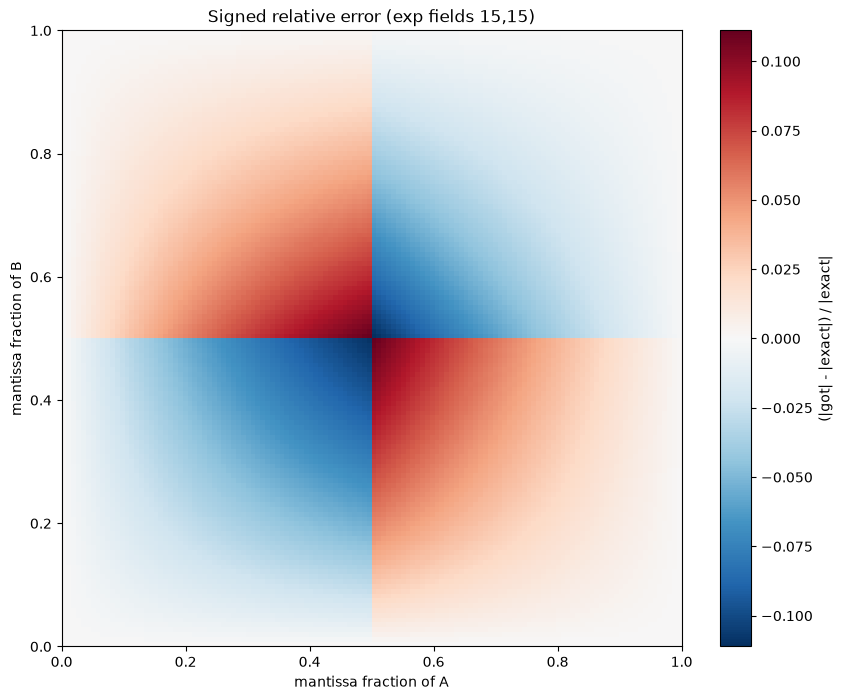

In [ ]:
# @title MAC accuracy plot 1
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "kQ2W+QAAAABJRU5ErkJggg=="
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

**MAC accuracy plot 1.** Signed relative error of the product for every pair of mantissas between 0.0 and 1.0.

The lines at 0.5 split the figure into four parts. If both mantissas are below 0.5, or both are above 0.5, the answer is negative. The worst case is in the middle, at 1.5 × 1.5: −11.1%. If one mantissa is below 0.5 and the other is above 0.5, the answer is positive. It is biggest next to the middle point, about +10% to +11%. The red parts and the blue parts have about the same size and strength. So positive and negative answers balance each other, and the bias is almost zero.

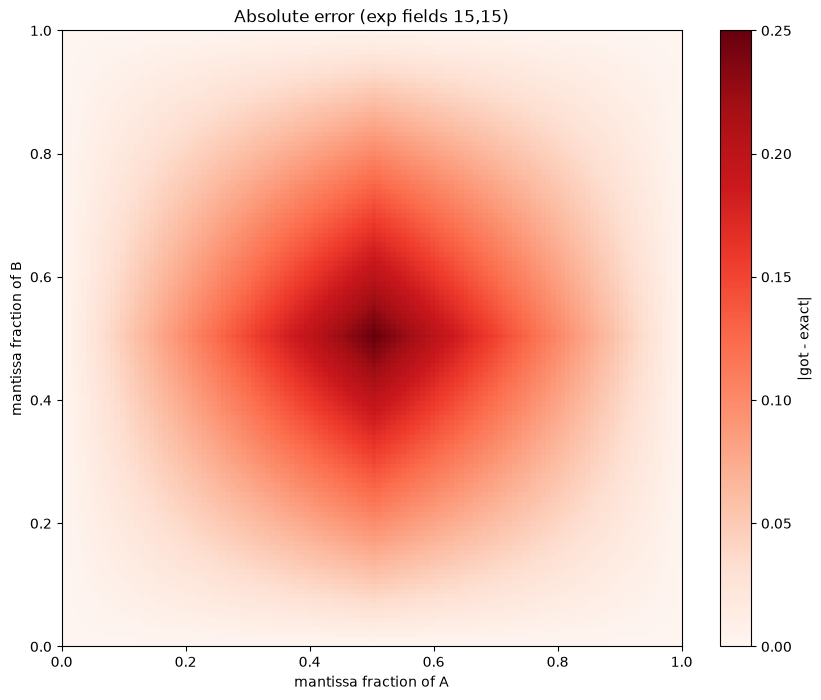

In [ ]:
# @title MAC accuracy plot 2
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "gg=="
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

**MAC accuracy plot 2.** Absolute error of the product for the same pairs of numbers.

If one number is a power of two (mantissa 0) or close to the next power of two (mantissa close to 1), the error is almost zero. The figure shows this. The absolute error is near 0 at the edges and biggest in the middle: 0.25 at 1.5 × 1.5 (exact 2.25, answer 2.0). It is also bigger along the two lines at 0.5.

For other numbers, the percentages for numbers between 2.0 and 4.0 and between 4.0 and 8.0 are exactly the same, so the pictures should look the same for them. Only the absolute error is 4 times and 16 times bigger.

##### 5.4c Multiplying by a power of two (1, 2, 4, 8 ...)

Numbers like 8, 2, 1 and 0.25 are *powers of two*, written 2^k (8 = 2<sup>3</sup>, 1 = 2<sup>0</sup>, 0.25 = 2<sup>-2</sup>). When you multiply a number by 2^k, its digits stay the same and only its exponent changes. Example: 1.37 × 4 = 5.48. The digits 1.37 are the same, and only the power of two goes up by 2. So the multiplier has nothing to approximate here, and the answer should be exact.

For each k from −4 to +3 we multiplied about 250 random numbers by 2^k, in both orders (a × 2^k and 2^k × a). We compared every answer with the exact one and counted the error in **ULPs**. 1 ULP is the gap between two neighbouring FP16 numbers, so it is the smallest mistake an FP16 answer can have. Near 1.0, 1 ULP ≈ 0.001, which is about 0.1% of the value.

| k (number × 2^k) | products tested | answers not exact | average error |
|---|---|---|---|
| −4 | 412 | 26.2 % | −0.262 ULP |
| −3 | 440 | 26.4 % | −0.264 ULP |
| −2 | 458 | 18.8 % | −0.188 ULP |
| −1 | 482 | 25.3 % | −0.253 ULP |
| 0 | 500 | 20.8 % | −0.208 ULP |
| +1 | 500 | 21.2 % | −0.212 ULP |
| +2 | 500 | 22.0 % | −0.220 ULP |
| +3 | 500 | 24.8 % | −0.248 ULP |

Over all k, 876 of the 3,792 products (23.1%) are not exact. For each single k it is between 19% and 26%.

##### 5.4d Very big products

The group of large products has 2000 vectors: products from 32768 up to 65504, and a few exact edge pairs. 1,952 vectors give a normal answer. Their relative error is the same as for other numbers: MRED 2.88%, P95 8.22%, P99 9.74%, max RE 10.81%, bias −0.131%. The other 48 vectors give no usable answer: 47 give a NaN bit pattern (exponent field 31, mantissa not zero) and 1 gives Inf. The exact products are smaller than 65504 and could be stored. Examples from the simulation log (4 of the 10 listed there):

| a | b | exact product | DUT output |
|---|---|---|---|
| 0x7610 (24832) | 0xC104 (−2.508) | −62274.0 | 0xFC0C |
| 0xE4FC (−1276) | 0xD23F (−49.97) | 63760.1 | 0x7C1B |
| 0xECCA (−4904) | 0xCA93 (−13.15) | 64479.9 | 0x7C13 |
| 0x6B95 (3882) | 0x4C37 (16.86) | 65448.1 | 0x7C01 |

The exponent overflows and is not limited to Inf or to the biggest normal number. All 10 NaN cases in the log have exact products between 62274 and 65448 (absolute value). The log lists only 10 of the 47, so we do not know yet where it starts. A test with products from 2¹⁴ to 65504 is planned.

#### 5.5 Results for the MAC

We measured the whole MAC (multiplier, converter and adder). We compare the Q16.16 result with the exact sum of the products (double precision, from the FP16 inputs).

##### 5.5a How we tested the MAC
- **Dot products** of length N = 4, 8, 16, 64, 256 for four kinds of data. All numbers are normal FP16 numbers: uniform between −8 and 8, positive between 0 and 8 (no plus and minus that cancel each other), gaussian N(0, 1), and log-uniform sizes 2⁻⁶ … 2³ with a random sign. We ran 20 trials for each kind of data and each N.
- **Normalised error** = (result − exact) / Σ|aᵢbᵢ|. With a normal Q16.16 adder, it can never be bigger than the error bound of one product. So we check every trial against |error| ≤ 0.12 · Σ|aᵢbᵢ| + N · 2⁻¹³ (0.12 is the error limit we set for one product; the last part lets every product below 2⁻¹³ become zero). All trials passed.

A *dot product* is a sum of products, a₁b₁ + a₂b₂ + …. This is what a MAC does. To judge the error fairly, we divide it by the total *size* of the terms (the sum of the absolute values), not by the final result. The reason: plus and minus terms cancel each other, so the final result can be small while the terms are big. Then even a small mistake would look huge. Example: the terms are 3, −2, 5, −1 (total size 11), and the exact sum is 5. The MAC gives 5.4. The mistake is 0.4. That is 3.6% of the total size (but 8% of the result, which looks worse only because of the cancelling).

##### 5.5b Adding many products (dot products)

Percent of Σ|aᵢbᵢ|. The RMS error is in plain units.

| Distribution | N | bias [%] | mean abs [%] | max abs [%] | RMS error |
|---|---|---|---|---|---|
| uniform | 4 | −0.490 | 1.974 | 4.852 | 1.342 |
| uniform | 8 | −0.107 | 0.944 | 1.863 | 1.256 |
| uniform | 16 | −0.249 | 0.952 | 2.725 | 3.009 |
| uniform | 64 | +0.232 | 0.473 | 1.229 | 5.956 |
| uniform | 256 | −0.001 | 0.228 | 0.658 | 12.03 |
| positive | 4 | −0.084 | 1.868 | 5.888 | 1.243 |
| positive | 8 | +0.568 | 1.694 | 4.946 | 2.181 |
| positive | 16 | +0.182 | 0.725 | 1.749 | 2.235 |
| positive | 64 | −0.035 | 0.447 | 1.058 | 5.777 |
| positive | 256 | +0.029 | 0.258 | 0.626 | 12.90 |
| gaussian | 4 | +0.193 | 2.570 | 7.267 | 0.0716 |
| gaussian | 8 | +0.642 | 1.541 | 4.675 | 0.101 |
| gaussian | 16 | −0.154 | 1.190 | 4.272 | 0.188 |
| gaussian | 64 | −0.214 | 0.483 | 1.613 | 0.270 |
| gaussian | 256 | −0.103 | 0.318 | 0.692 | 0.604 |
| log-uniform | 4 | −1.639 | 2.654 | 8.082 | 0.556 |
| log-uniform | 8 | −0.242 | 1.911 | 4.120 | 0.380 |
| log-uniform | 16 | −0.024 | 1.489 | 5.069 | 0.460 |
| log-uniform | 64 | −0.158 | 0.853 | 1.667 | 0.990 |
| log-uniform | 256 | −0.077 | 0.468 | 1.089 | 2.365 |

The RMS error grows like N^0.57 (uniform), N^0.55 (positive), N^0.50 (gaussian) and N^0.40 (log-uniform).

- **The mistakes cancel.** The normalised error gets smaller when N gets bigger. The biggest value in the sample is 8.08% for N = 4 and 1.09% for N = 256.
- **No drift on realistic data.** The bias stays within about ±0.6% (the biggest is 1.64%, loguniform at N = 4), and it has no trend with N. The positive data has no plus and minus that cancel, but its average error still falls from 1.87% to 0.26% between N = 4 and N = 256. This is close to 1/√N. So the mistakes of the products are about zero on average and do not depend on each other.
- **The absolute error grows slowly** (exponent 0.40–0.57), about like √N. The normalised error falls because the sum grows faster than the error.

##### 5.5c Accumulating the same product

Cancelling depends on the data. The test looks in a grid of 32 × 32 mantissas (exponent fields 15, 15) for the pairs with the biggest too-big and the biggest too-small mistake. Then it adds N copies of the same pair:

| Pair | Single-product error | Result of N = 16 / 64 / 256 copies | Normalised error |
|---|---|---|---|
| 0x3E00 × 0x3E00 (1.5 × 1.5, exact 2.25, result 2.0) | −11.111% | 32 / 128 / 512 | −11.111% for every N |
| 0x3DE0 × 0x3E00 (1.46875 × 1.5, exact 2.203, result 2.4375) | +10.638% | 39 / 156 / 624 | +10.638% for every N |

The total is exactly N times the single result. So the adder adds no mistake of its own. For equal products the error does **not** get smaller when N grows: the bound of section 5.5a is tight. Normal data cancels (section 5.5b). But constant or very similar numbers can add up to about ±11%. These are the biggest values in the grid, so the real range is at least [−11.11%, +10.64%].

##### 5.5d When the accumulation result gets too big

| Case | Result |
|---|---|
| single product 200 × 200 (exact 40000) | 32767.99998: saturates at the converter |
| 4 × (100 × 100); each product is 9216, sum 36864 | −28672.0: **wraps around** |
| 4 × (−100 × 100); sum −36864 | +28672.0: **wraps around** |

One product that is too big is *saturated* (cut to the biggest value) by the converter. But a **sum** that goes outside ±32768 *wraps around* (two's complement) and silently changes its sign.

##### 5.5e One product at a time through the MAC

Single-product test: 3000 random products. The numbers are between 0.125 and 181 (random FP16 codes of different sizes, random signs). So every product is between 2<sup>-6</sup> and 2<sup>15</sup>. Each product goes through the multiplier, the converter and the adder (N = 1). Every product was within 12% of its exact value plus 1 LSB.

All together: MRED 2.88%, max RE 11.05%, bias −0.09%. Split by size of the product:

| Product range | N | MRED [%] | max RE [%] | bias [%] |
|---|---|---|---|---|
| 2<sup>-6</sup> – 2<sup>-5</sup> | 12 | 2.94 | 5.62 | −1.68 |
| 2<sup>-5</sup> – 2<sup>-4</sup> | 49 | 2.61 | 6.88 | −0.44 |
| 2<sup>-4</sup> – 2<sup>-3</sup> | 66 | 2.75 | 10.05 | −0.64 |
| 2<sup>-3</sup> – 2<sup>-2</sup> | 91 | 3.23 | 10.71 | −0.20 |
| 2<sup>-2</sup> – 2<sup>-1</sup> | 99 | 3.05 | 10.14 | −0.41 |
| 2<sup>-1</sup> – 2<sup>0</sup> | 152 | 2.97 | 10.07 | +0.13 |
| 2<sup>0</sup> – 2<sup>1</sup> | 166 | 2.64 | 8.91 | +0.23 |
| 2<sup>1</sup> – 2<sup>2</sup> | 203 | 3.14 | 10.49 | +0.10 |
| 2<sup>2</sup> – 2<sup>3</sup> | 240 | 3.00 | 11.05 | +0.09 |
| 2<sup>3</sup> – 2<sup>4</sup> | 260 | 2.77 | 10.66 | −0.15 |
| 2<sup>4</sup> – 2<sup>5</sup> | 260 | 2.77 | 9.90 | +0.02 |
| 2<sup>5</sup> – 2<sup>6</sup> | 273 | 2.89 | 10.70 | −0.18 |
| 2<sup>6</sup> – 2<sup>7</sup> | 235 | 2.86 | 9.84 | −0.01 |
| 2<sup>7</sup> – 2<sup>8</sup> | 222 | 2.97 | 9.63 | −0.47 |
| 2<sup>8</sup> – 2<sup>9</sup> | 177 | 2.77 | 10.48 | −0.11 |
| 2<sup>9</sup> – 2<sup>10</sup> | 150 | 2.68 | 9.79 | +0.25 |
| 2<sup>10</sup> – 2<sup>11</sup> | 115 | 2.77 | 10.30 | −0.24 |
| 2<sup>11</sup> – 2<sup>12</sup> | 104 | 3.29 | 9.53 | −0.41 |
| 2<sup>12</sup> – 2<sup>13</sup> | 62 | 2.53 | 7.29 | +0.91 |
| 2<sup>13</sup> – 2<sup>14</sup> | 44 | 2.84 | 8.79 | −0.67 |
| 2<sup>14</sup> – 2<sup>15</sup> | 20 | 2.79 | 6.62 | −0.21 |

MRED is between 2.5% and 3.3%, and max RE is at most 11.05%, in every size range from 2<sup>-6</sup> to 2<sup>15</sup>. Rows with fewer than about 100 samples (the smallest and the biggest sizes) are not reliable. Their lower maximum comes from the few samples.

The total MRED (2.88%) and bias (−0.09%) are close to the values for the multiplier alone (2.66%, −0.06%). This is what we expect if the change from FP16 to Q16.16 adds no error for products of 2<sup>-6</sup> and bigger.

#### 5.6 Accuracy conclusion

The accuracy tests demonstrate that the approximate multiplier achieves good accuracy for normal FP16 inputs while reducing the need for an exact multiplication operation. Across the main test set, the multiplier achieved a mean relative error (MRED) of 2.66%, with 95% of eligible test cases having an error below 7.84% and 99% below 9.67%. The maximum observed relative error was 11.17%, while the average signed error (bias) was only −0.055%, indicating that overestimation and underestimation largely balance each other. The relative error also remained approximately constant across the tested product magnitudes. These results show that the multiplier provides predictable accuracy within the tested operating range, although the measured maximum error is not a guaranteed bound for every possible input.

The accuracy tests of the complete multiply-accumulate (MAC) unit show that the multiplier is the primary source of numerical error. For 3,000 single-product tests, the MAC achieved an MRED of 2.88%, a maximum relative error of 11.05%, and a bias of −0.09%, closely matching the multiplier-only results. This indicates that the converter and adder introduce no significant additional error for the tested products within the supported numerical range. In dot-product tests with different input distributions and lengths from 4 to 256, all trials satisfied the defined error tolerance. The maximum normalized error decreased from 8.08% for four products to 1.09% for 256 products in the tested cases, primarily because positive and negative product errors tend to cancel. However, this improvement is data-dependent: when the same product is accumulated repeatedly, its error does not cancel, and the normalized error can remain approximately −11.11% or +10.64%.

## 6. Processing element

A PE combines the MAC with two operand-forwarding registers, a completion counter and a result register. A moves horizontally to the next column; B moves vertically to the next row. The local sum implements the intended output-stationary organization.

`done` enables operand forwarding. The counter monitors completed-operation events and produces `valid_out`; this enables the output register to capture the PE sum. Register updates are clocked, so the output capture follows the counter's registered validity indication.

| PE interface | Width / role |
|---|---|
| `A_in`, `B_in` | Two FP16 words |
| `A_out`, `B_out` | Registered operand forwarding |
| `y_out` | 32-bit Q16.16 result |
| `valid`, `done`, `valid_out` | Request, operation completion and output capture control |

**Figure 8.** PE schematic: local MAC, A/B forwarding registers, counter and 32-bit result register.

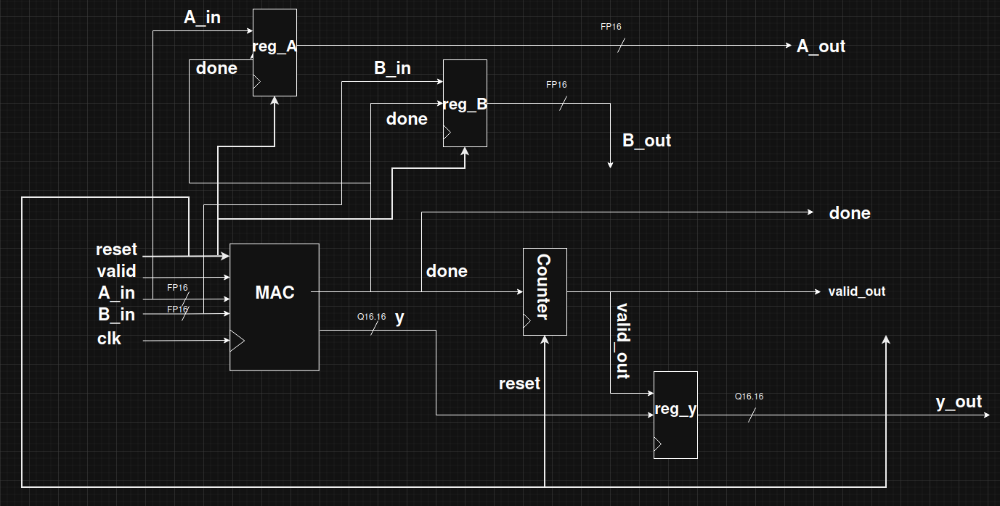

In [ ]:
# @title Figure 8
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "AAAAAMCgf5GMVKi2TdDHAAAAAElFTkSuQmCC"
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

**Figure 9.** Annotated PE simulation on the current RTL: FP16 operands, forwarding to the next PE, Q16.16 MAC output and done pulses; valid_out rises after the tenth done pulse and y_out captures the final sum (0x00A80000).

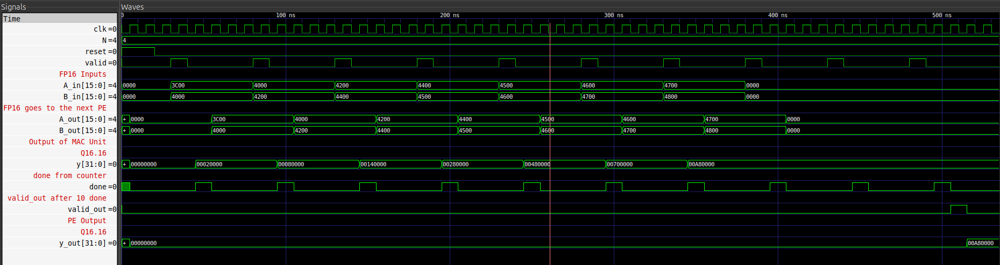

In [ ]:
# @title Figure 9
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "AABJRU5ErkJggg=="
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

## 7. Registers and counters

### Register primitive

`reg_def.v` provides a width-parameterized clocked register. Clear has priority; otherwise an asserted enable captures the input. Without either condition, the register retains its value. Instances store operands, packet halves and PE results.

### PE counter

`counter.v` uses `COUNT_MAX = 3N-2`. In the 4×4 instance this is ten. The counter advances on clock edges where done is high, and valid_out pulses when the count reaches ten. The PE result register captures on the next active edge while that pulse is visible. This is the counter's local operation contract rather than a wall-clock matrix latency.

### Controlled counter

`controlled_counter.v` advances only while enable is asserted and pulses count_done when its limit is reached. It indexes input banks and counts the output transfer sequence. Output completion uses a 128-transfer limit in the current nibble-output configuration.

**Figure 10.** Enabled register: clear-to-zero, input capture and retained-value paths.

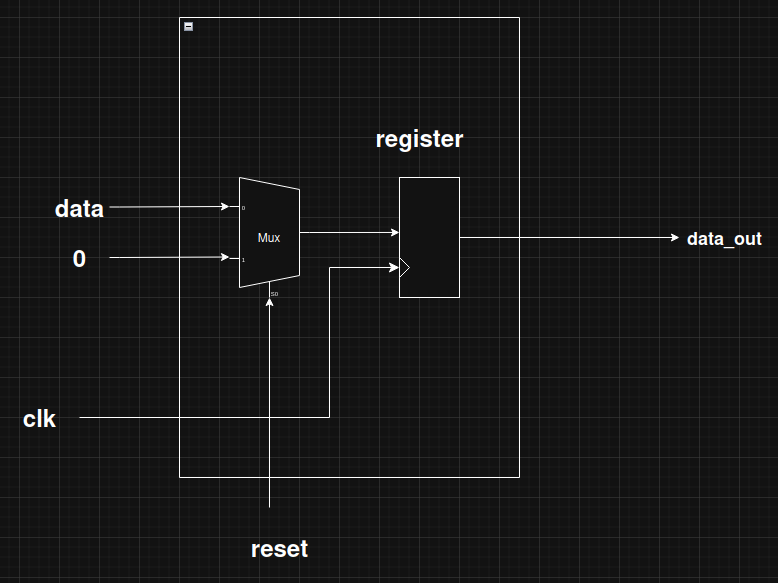

In [ ]:
# @title Figure 10
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "AAAAwPB/vwTyvr3b7vgAAAAASUVORK5CYII="
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

**Figure 11.** Updated PE completion-counter diagram with a 10-step schedule for N = 4 (COUNT_MAX = 3N − 2).

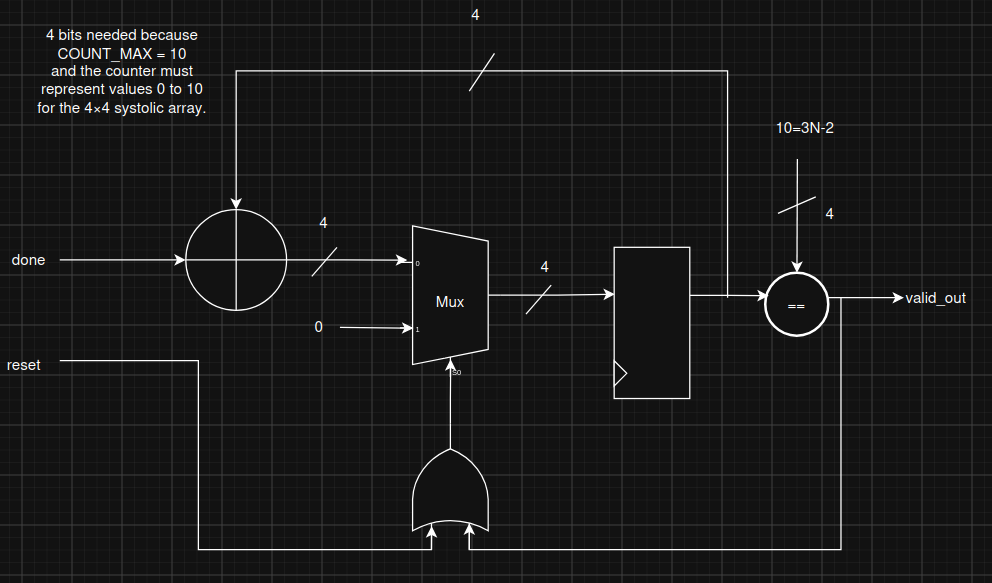

In [ ]:
# @title Figure 11
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "AAAASUVORK5CYII="
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

**Figure 12.** Counter waveform on the current RTL: clock, reset, done events and a 4-bit count reaching 10 (COUNT_MAX = 10 for N = 4), with a one-clock valid_out pulse.

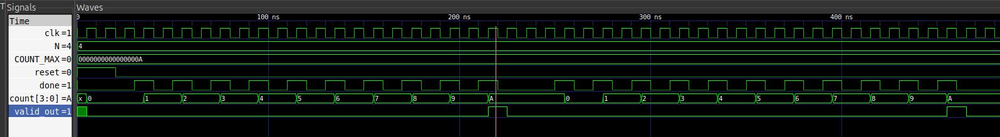

In [ ]:
# @title Figure 12
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

## 8. Data feeders and operand alignment

Each data feeder loads a row or column stream into a shift register and presents the most significant word first. A shift advances by one operand word. At N=4 the input feeder stores seven 16-bit words, or 112 bits.

The input datapath inserts leading and trailing zeros around the four matrix elements. Rows and columns receive different leading delays so corresponding A and B values can be aligned as they traverse the PE interconnect. A load replaces the full stream; shifts consume it word by word and introduce zeros at the tail.

The same feeder primitive is reused in the output datapath with a 512-bit input and a four-bit output word.

**Figure 13.** Data feeder schematic: parallel load, enabled shift and most-significant-word output.

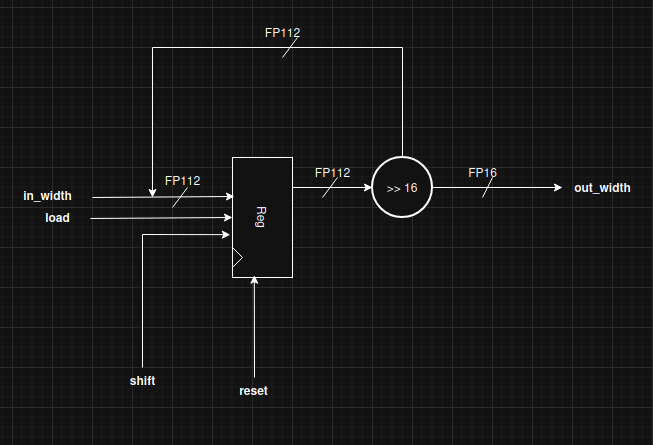

In [ ]:
# @title Figure 13
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

**Figure 14.** Team feeder simulation illustrating loaded data, shift control and zero padding.

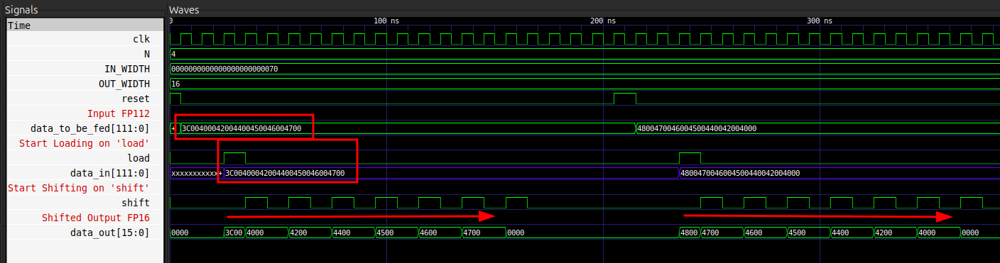

In [ ]:
# @title Figure 14
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

## 9. Ready-valid transaction block

`rv_protocol.v` registers a transfer when valid and ready are asserted while the block is idle. A registered transmit event aligns tx_done with the captured data. The state machine then passes through TRANSFERRING before returning to IDLE.

This explicit state sequencing provides an acknowledgement for the controller and introduces a transfer bubble. The timing diagram is therefore read with the FSM, rather than assuming a new accepted beat on every rising edge. The design uses one instance on the input packet path and another on the result path.

**Figure 15.** Ready-valid block: accepted-data register, delayed transmit event and control FSM.

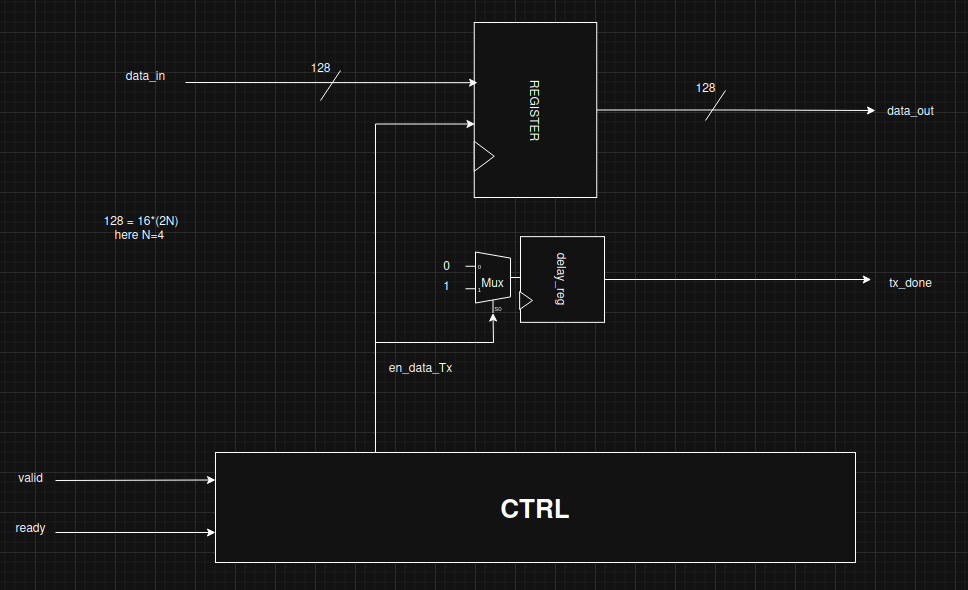

In [ ]:
# @title Figure 15
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "yYWmfLx8yfgAAAAASUVORK5CYII="
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

**Figure 16.** Ready-valid state-transition graph.

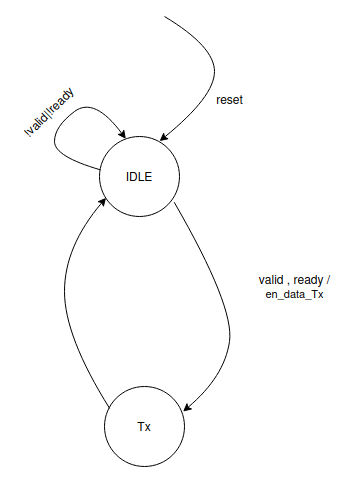

In [ ]:
# @title Figure 16
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "kvsf/G3UWiHWMCEAAAAASUVORK5CYII="
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

**Figure 17.** Annotated handshake waveform: request qualifiers, captured packet and tx_done timing.

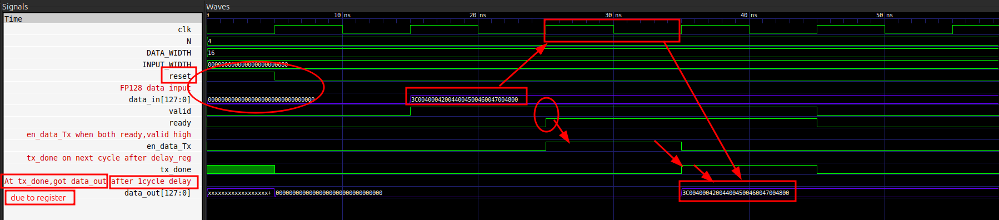

In [ ]:
# @title Figure 17
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

## 10. Input datapath

The input datapath accepts a 128-bit packet, separates the upper A-row half and lower B-column half, and stores the matrix streams in row/column banks. Controlled counters select the current row and column. For the 4×4 schematic, four A streams and four B streams connect to the eight feeders.

The padding network extends each 64-bit row or column to a 112-bit stream. The schematic below shows that register-bank organization; the annotated simulation illustrates packet capture, index progression and the load-in completion event.

### Packet layout

| Bits | Contents |
|---|---|
| `[127:64]` | A row: four FP16 words |
| `[63:0]` | B column: four FP16 words |

The element ordering is most-significant word first within each half.

**Figure 18.** Input datapath schematic: registered packet, row/column selection and skew-padded streams.

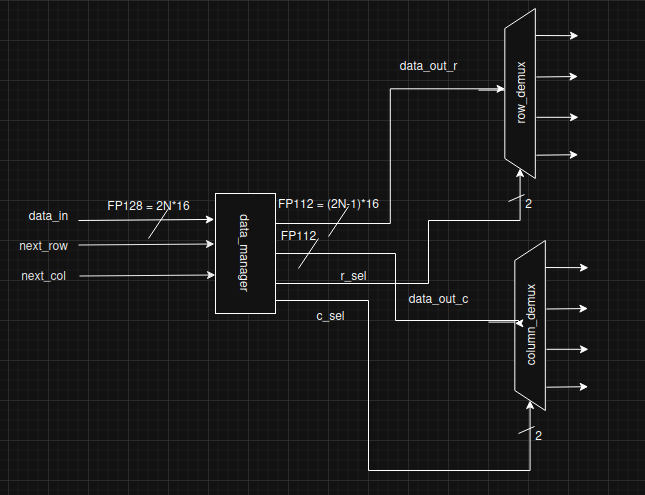

In [ ]:
# @title Figure 18
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

**Figure 19.** Annotated input datapath simulation from the team schematic documentation.

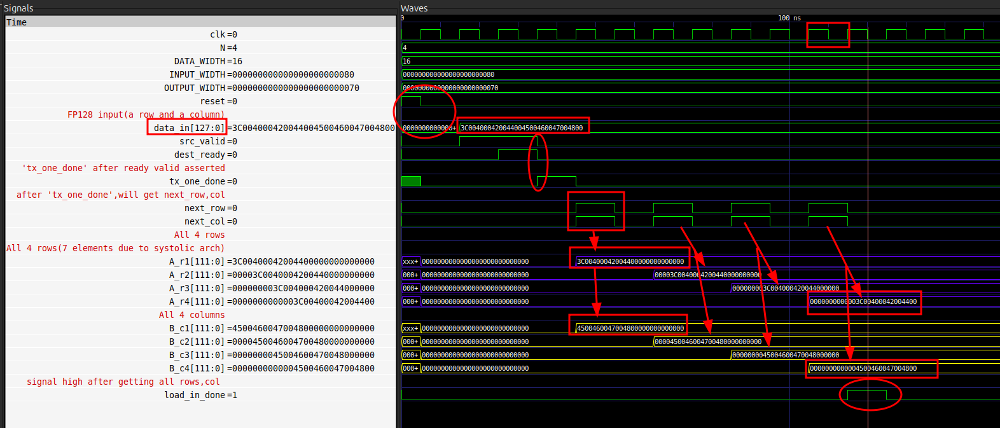

In [ ]:
# @title Figure 19
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

## 11. Output datapath

Sixteen PE results form a 512-bit row-major collection bus. A buffer captures the collection, an output feeder presents the next result nibble, and the ready-valid block registers each transfer. The shift counter records transmit events and generates completion after 128 output transfers.

Each Q16.16 element is 32 bits, so it requires eight nibble transfers. The first eight transfers represent the first matrix element; the next eight represent the second, and so on.

The original schematic-review drawing illustrates an earlier **64-bit transfer width**. The current chip-level packet diagram in section 3 and the current RTL use a **four-bit external result width**, giving 128 transfers for the complete 512-bit result.

**Figure 20.** Original output schematic: result buffering, feeder and transfer counter. Its illustrated 64-bit chunk size belongs to the earlier interface version.

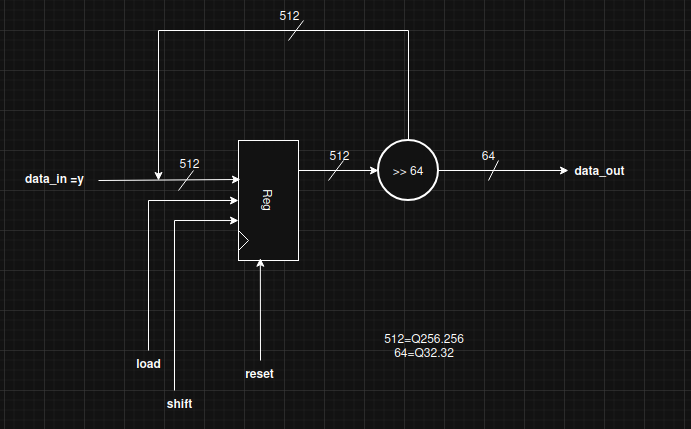

In [ ]:
# @title Figure 20
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

**Figure 21.** Team output datapath waveform illustrating buffered data, transmit events and transfer-counter behavior.

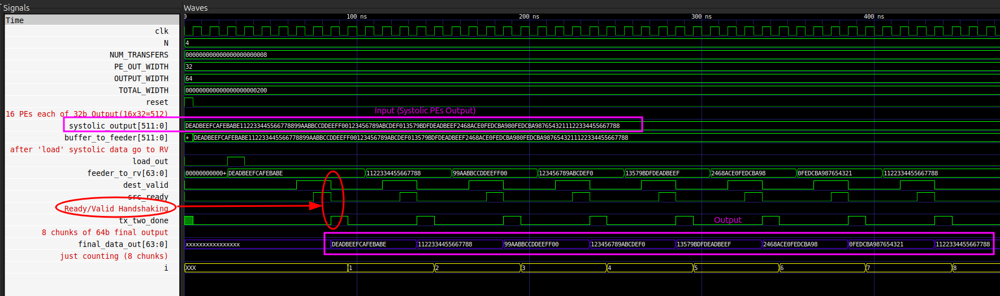

In [ ]:
# @title Figure 21
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

## 12. Serializer and chip wrapper

### Byte-to-packet serializer

`input_serializer.sv` turns sixteen accepted eight-bit bytes into one 128-bit packet. It receives data while valid_in and ready_in are asserted. The first byte occupies `[127:120]` and the sixteenth occupies `[7:0]`. On the final byte, the completed packet is copied to data_out and valid_out is asserted.

While the completed packet waits for ready_out, the serializer holds its contents and lowers ready_in. After the downstream consumer accepts the packet, it returns to byte collection. The functional check below exercises two consecutive packets and verifies their MSB-first assembly.

### Current wrapper acquisition

`chip_core.sv` uses its own packet buffer and byte-count controller for the same eight-to-128-bit collection task. It collects a packet, requests acceptance by the systolic input path, and then proceeds to the next packet. Four packets supply the matrix pair. The reusable input_serializer is present in the source tree and independently simulated; the current chip wrapper performs collection directly in its internal controller.

The output controller limits readout to 128 result transfers. The logical packet-flow image and RTL hierarchy in sections 3–4 show this integration. Internal handshake and completion events are used by the chip-core simulation driver; the 16-pin assignment itself exposes clock, reset, data and power.

## 13. Systolic controller

The top-level FSM coordinates input reception, operand loading, MAC launch, computation completion and result transfer.

| Phase / state(s) | Main role |
|---|---|
| IDLE | Wait for a transaction request |
| RECEIVE, IN_COUNT, LOAD_IN | Accept packets and advance row/column acquisition |
| LOAD_FEED | Load the eight operand feeders |
| FEED, PROCESSING | Launch PE operations and coordinate operand movement |
| DONE, LOAD_OUT | Prepare collected results for readout |
| TRANSFER | Emit result words through the output transaction block |

Completion reduction is organized into registered row groups followed by a registered global flag. This connects the distributed PE completion signals to the controller. The team's state-transition drawing below is the design reference for the overall transaction sequencing.

**Figure 22.** Team systolic FSM diagram: input loading, array processing and result transfer.

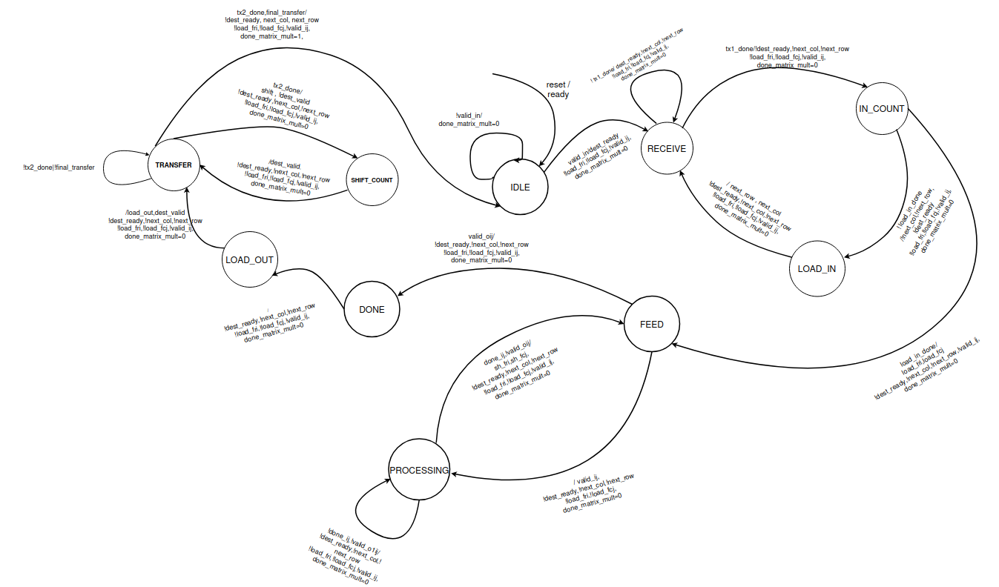

In [ ]:
# @title Figure 22
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "AAAAAElFTkSuQmCC"
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

## 14. Functional simulation results

The team's repository contains Verilog/SystemVerilog testbenches, GTKWave captures and terminal transcripts. The waveforms in the preceding sections illustrate each module's intended signal behavior. The reproducible checks below cover **MAC transactions, counters, the processing element, ready-valid capture, feeder order, serializer packet assembly and output nibble comparisons**.

| Functional check | Observed result |
|---|---|
| MAC accumulation | Five signed/fractional transactions matched the implemented arithmetic; done hold and reset checks passed; three products above the old Q8.8 limit (256, −256, 512) accumulated exactly in Q16.16 |
| Counter | Enable, hold and 10-step terminal valid-pulse checks passed; repository `counter_tb` passed both runs and the one-clock pulse check |
| Processing element | Repository `pe_tb`: valid_out after 10 done events, one-clock pulse, final sum captured in y_out |
| Ready-valid block | Blocked capture, data alignment and transfer-bubble checks passed |
| Data feeder | Seven-word order and zero-padding checks passed |
| Serializer | Two 128-bit packets assembled correctly; packet hold and reuse checks passed |
| Output datapath | 128/128 emitted nibbles matched their expected values; completion count asserted |

This module-level result set complements the PE and input-datapath waveform demonstrations from the schematic review. Each result is tied to the functional check listed above.

### Passed-check transcript

The excerpt below is generated from actual Icarus Verilog runs. Full logs and sample data are embedded in the notebook and available under results/ when the optional reproduction cell is run. Long repetitive output-transfer lines are abbreviated in the displayed excerpt.

```text
[MAC transaction checks]
PASS: 5 MAC transactions, sticky-done hold and reset
PASS: direct FP16-to-Q16.16 conversion removes previous Q8.8 clipping

[Counter, RV, feeder and serializer checks]
PASS: counter enable, hold, 10-step terminal pulse
PASS: RV blocked capture, data alignment, bubble
PASS: feeder load, 7 words, zero padding
PASS: serializer 2 packets, MSB order, backpressure, reuse

[counter_tb]
PASS: valid_out asserted correctly after 10 pulses.
PASS: valid_out is a one-clock completion pulse.
PASS: valid_out asserted correctly on second run.
ALL COUNTER TESTS PASSED
COUNT_MAX = 10 FOR N = 4

[pe_tb]
PASS: valid_out asserted correctly after 10 done events.
PASS: valid_out is a one-clock completion pulse.
PASS: final accumulated MAC result captured into y_out.
ALL PE TESTS PASSED

[input_serializer_tb]
PASS: MSB-first packet assembled correctly.
PASS: Second packet correct.

[output_datapath_tb]
PASS: buffer and feeder loaded correctly.
PASS: transfer=0 data=d tx_done=1
PASS: transfer=127 data=8 tx_done=1
PASS: sh_count_done asserted.
128/128 emitted transfers matched their expected nibbles.

ALL LISTED MODULE CHECKS PASSED.
```

**Figure 23.** Terminal output of the repository counter test (`src/tb/counter_tb.sv`): second run and final summary, COUNT_MAX = 10 for N = 4.

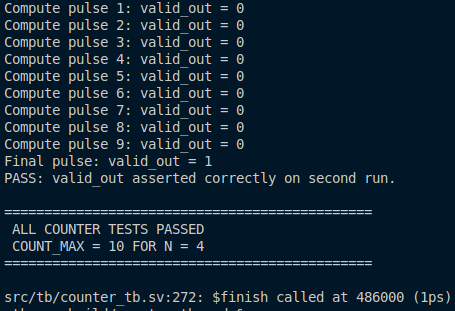

In [ ]:
# @title Figure 23
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "AAAASUVORK5CYII="
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

**Figure 24.** Ready-valid testbench transcript showing the registered packet and transmit event.

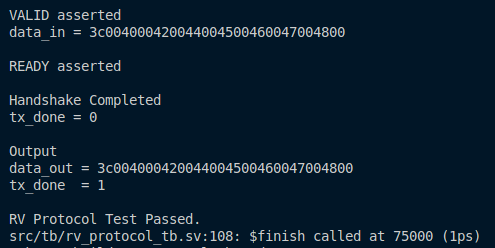

In [ ]:
# @title Figure 24
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "RK5CYII="
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

### Simulation plots

The first plot shows the accumulator after five completed MAC transactions. It is a functional sequence plot, with signed/fractional test operands and an observed sum after each operation. The second plot visualizes the actual nibble values from all 128 checked output transfers and the cumulative receive count.

These plots are derived from simulator samples stored in results/mac_samples.json and results/output_samples.json. The source scripts reproduce both plots without inserting hand-entered simulation values.


**Figure 25.** Observed MAC accumulator values after five transactions: 2, 1.5, 3.5, 3.5 and 3.625.

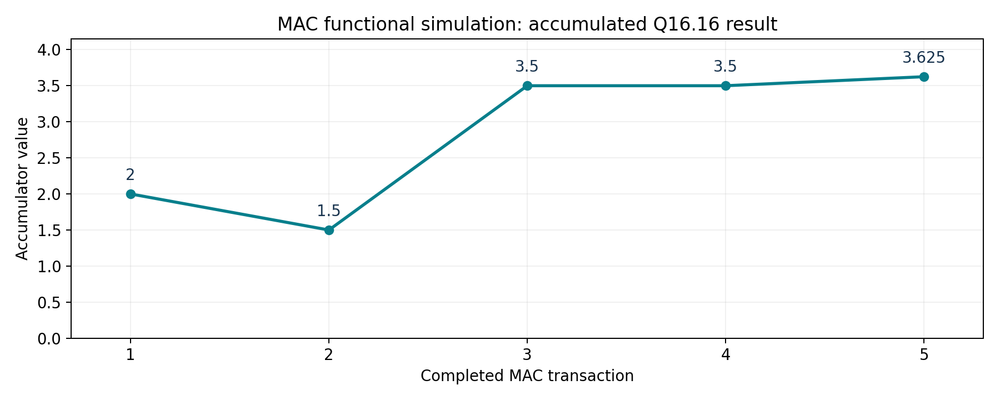

In [ ]:
# @title Figure 25
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

**Figure 26.** Actual output-datapath samples: nibble values and cumulative count across 128 expected-value comparisons.

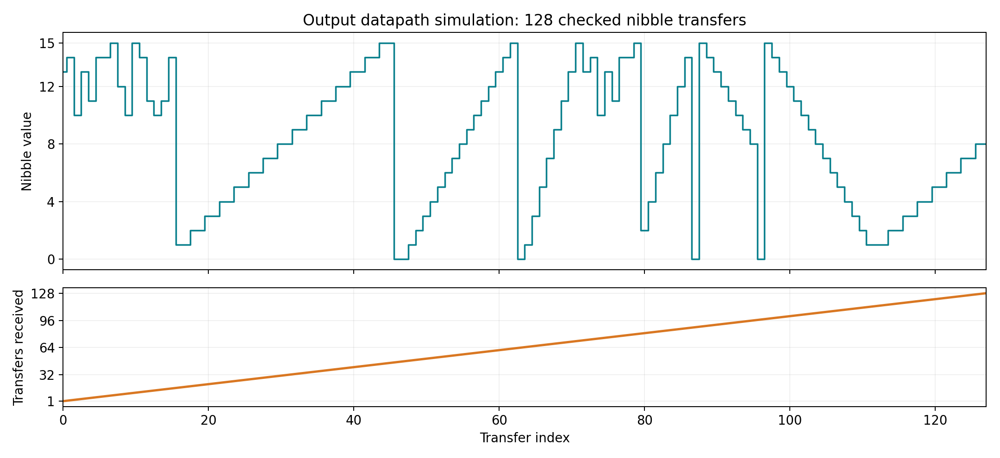

In [ ]:
# @title Figure 26
# Saved figure: running this cell redraws the same picture.
import base64 as _a34_base64
from IPython.display import Image as _A34Image, display as _a34_display
_a34_png = (
    "..."
    "rkJggg=="
)
_a34_display(_A34Image(data=_a34_base64.b64decode(_a34_png), format="png"))

## 15. Reproduction and submission

The design figures, graphs and pass transcript are saved in this notebook and can be read without execution. The RTL snapshot, test helpers, raw results and license are retained in notebook metadata for optional reproduction.

> **Figures:** every figure cell stores its picture inside the cell, so the notebook can be read without running anything, and running a figure cell simply redraws the same picture. Section 16 has its own run instructions.

### Optional module-check reproduction

Use Python 3 with NumPy and Icarus Verilog installed. The documented simulations use Icarus Verilog 12.0. Save this notebook as `SiliconForge_Code_a_Chip.ipynb` in the runtime working folder, then run the short cell below. In Colab, upload the downloaded notebook through the runtime's **Files** panel as well as opening it as a notebook. The cell reads the embedded files and runs the documented checks on the packaged RTL snapshot from branch `a34-rtl-fix-pd` (commit `13bd466`). Without Icarus Verilog the cell reports that and skips the simulations.

For Colab, dependencies can be installed in a temporary code cell:

```python
!apt-get -qq update
!apt-get -qq install -y iverilog
!python -m pip install -q numpy matplotlib
```

After a successful check run, regenerate the functional plots with:

```python
subprocess.run([sys.executable, str(project / 'support/plot_results.py')], check=True)
```

### Travel Representative

Rumali Siddiqua is the designated travel representative.


In [ ]:
# Optional: reproduce the documented module checks from this notebook file.
import base64
import io
import json
import shutil
import subprocess
import sys
import tempfile
import zipfile
from pathlib import Path

notebook = Path('SiliconForge_Code_a_Chip.ipynb')
if not notebook.is_file():
    print('Place this downloaded notebook in the runtime working folder '
          'to reproduce checks.')
elif not (shutil.which('iverilog') and shutil.which('vvp')):
    print('Icarus Verilog is not installed, so the optional module checks '
          'were skipped.')
    print('The saved results above are from the documented run. '
          'Install iverilog to rerun them.')
else:
    metadata = json.loads(notebook.read_text())['metadata']
    package = metadata['siliconforge']['embedded_project_zip_base64']
    project = Path(tempfile.mkdtemp(prefix='siliconforge_'))
    with zipfile.ZipFile(io.BytesIO(base64.b64decode(package))) as archive:
        for item in archive.infolist():
            target = (project / item.filename).resolve()
            if not target.is_relative_to(project.resolve()):
                raise ValueError('Invalid embedded path')
        archive.extractall(project)
    run = subprocess.run(
        [sys.executable, str(project / 'support/run_module_checks.py')],
        cwd=project, text=True, capture_output=True)
    print(run.stdout, end='')
    if run.returncode:
        raise RuntimeError(run.stderr or 'Inspect the check output above.')

## 16. Physical Design

> **Use branch `a34-rtl-fix-pd`.** Everything in this section (RTL, configuration, layout, netlist and reports) comes from branch [`a34-rtl-fix-pd`](https://github.com/Waleed99i/chipathon-2026-systolic-ip-core/tree/a34-rtl-fix-pd) of the team repository. Do not use the `main` branch for this section. To get the files: `git clone -b a34-rtl-fix-pd https://github.com/Waleed99i/chipathon-2026-systolic-ip-core.git`. Cell 16.1 checks out the pinned commit automatically.

**Physical design:** Rumali Siddiqua · **Implementation:** LibreLane Classic flow plus a recorded seven-cell ECO, GF180MCU `gf180mcuD` · **Top cell:** `chip_core`

This section documents the physical implementation of the team's 4×4 accelerator in a **1675 µm × 1675 µm A34 slot**: synthesis, floorplanning, placement, clock-tree synthesis, routing, power-grid repair, a core power ring, timing closure with a small engineering change order (ECO), and block-level verification. The 16 application-pad entries expand to 72 boundary terminals because the pad-cell controls are exposed at the block interface.

**Design version.** The layout implements the accelerator RTL on repository branch `a34-rtl-fix-pd`: FP16 inputs, each product converted to signed Q16.16 (`fp16_to_q16_16.v`) and accumulated in 32 bits, and a 3N−2 = 10-step compute schedule for N = 4. The power-delivery solution in 16.5 was developed during earlier development runs of this block and is reused unchanged.

**Scope.** DRC, LVS, timing analysis and the power-connectivity check show that the layout obeys the geometry rules, matches its powered gate-level netlist and meets timing in all nine modeled corners. Separately, 16.7d rechecks the recorded 33-case gate-level/RTL regression outputs; 16.7e optionally reruns that simulation. None of these is a silicon measurement.

### Results and their evidence

| Item | Result | Evidence available here |
|---|---|---|
| Block size / GDS database unit | 1675 × 1675 µm / 0.001 µm | Measured from the pinned GDS |
| Placed cell instances | 119,247 total, including physical-only cells | Counted from the GDS (16.6b) |
| Selected cell group | 34,104 excluding filler/decap, taps and endcaps; includes clock-load and antenna cells | Name/master-based categories (16.6b) |
| Selected cell footprint / slot area | 0.906 mm² / 2.805625 mm² (32.3 %) | Placement-boundary footprint sum; LibreLane reports 36.2 % standard-cell utilization of the core (16.7b) |
| Power bridges and ring | 12 bridges; Metal4/Metal5 ring; all VDD and all VSS shapes connected | GDS geometry (16.5b–c); committed OpenROAD `check_power_grid` log of the final database (16.5d) |
| Clock tree | 653 buffers, 9 graph levels, 491 load cells, 4,096 flip-flops | Final netlist and GDS (16.6d) |
| Timing at 45 ns, 9 corners | 0 setup and 0 hold violations; worst setup slack +0.550 ns (`max_ss_125C_4v50`); worst hold slack +0.091 ns (`min_ff_n40C_5v50`) | Committed post-route STA reports and metrics (16.7b) |
| Slew / capacitance / fanout | 0 violations at all 9 corners | Same |
| DRC / antenna | 0 router, Magic and KLayout DRC errors; 0 antenna violations | Committed final metrics (16.7b) |
| Block LVS | Circuits match uniquely: 34,107 devices, 34,102 nets | Committed Netgen report (16.7a) |
| Gate-level function | 33 of 33 matrix products identical to the RTL; 23 of 23 exact-arithmetic cases equal A·B | Committed regression outputs, recomputed here and rerunnable (16.7d) |
| Clock target / final run time | 45 ns / 1 h 02 min for the ECO run | Configuration / flow log |

**Reproduction path.** The cells recompute geometry, counts, plots and hashes from the pinned commit and parse the committed reports of the final run. Re-executing this notebook analyzes existing artifacts; it does not run the implementation flow. Integrated-chip DRC/LVS on the full chip, pad-fed IR drop and electromigration, and silicon measurements are outside the demonstrated results.

| Subsection | Contents |
|---|---|
| 16.1–16.3 | Analysis setup, implementation stages and configuration |
| 16.4 | Organizer DEF interface, block boundary, and how Section 2's 16 pad entries map onto the 72 terminals |
| 16.5 | Power-connection debugging, bridge geometry, core ring and the OpenROAD connectivity check |
| 16.6 | Layout, cell categories, inferred register groups, clock topology and metal coverage |
| 16.7 | Verification of the final layout: hashes and LVS, nine-corner timing, parasitic annotation, gate-level regression |
| 16.8 | Timing closure: run history and the seven-cell ECO |
| 16.9–16.11 | Recorded commands, lessons and tool references |

### 16.1 Setup

Everything in this section reads from the team repository at one pinned commit on branch `a34-rtl-fix-pd`, so the results always describe the same GDS. KLayout's Python API (to read and render the GDS) and common plotting packages are used for the default analysis. The optional simulation cell also needs Icarus Verilog and standard-cell models. To reproduce the analysis, use a fresh runtime in a copy of the notebook and run this section's cells in order; saved outputs support reading without execution.

In [ ]:
# @title 16.1 · Reproducible analysis environment
import hashlib
import importlib.metadata
import json
import os
import platform
import re
import shutil
import subprocess
import sys
from pathlib import Path

A34_REPO = "https://github.com/Waleed99i/chipathon-2026-systolic-ip-core.git"
A34_BRANCH = "a34-rtl-fix-pd"  # use this branch, not main
# Pinned commit on A34_BRANCH: final layout.
A34_REF = "ba362298c8602f5920cd422e4b8542dfafa3938a"
PDK = "gf180mcuD"
PDK_REF = (
    "7636804aa430fed842535e3d660f94de8ac4754c"  # tag 1.8.0; layer colors only
)
PDK_TAG = "1.8.0"
REQUIRED = {
    "klayout": "0.30.12",
    "pandas": "2.2.3",
    "matplotlib": "3.10.8",
    "pyyaml": "6.0.3",
    "jinja2": "3.1.6",
    # NumPy 2.3 needs Python 3.11+; 2.2.6 is the last release for Python 3.10.
    "numpy": "2.3.5" if sys.version_info >= (3, 11) else "2.2.6",
}


def run(args, cwd=None):
    result = subprocess.run(
        list(map(str, args)), cwd=cwd, text=True, capture_output=True
    )
    if result.returncode:
        raise RuntimeError(result.stdout[-3000:] + result.stderr[-3000:])
    return result.stdout.strip()


missing = []
for package, version in REQUIRED.items():
    try:
        installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        missing.append(f"{package}=={version}")
if missing:
    run([sys.executable, "-m", "pip", "install", "--quiet", *missing])
    print(
        "Installed pinned analysis packages. If one was already imported, "
        "restart the kernel before continuing."
    )

WORK = Path(
    os.environ.get(
        "SILICONFORGE_WORKDIR", str(Path.cwd() / "siliconforge_pd_analysis")
    )
).resolve()
WORK.mkdir(parents=True, exist_ok=True)
A34 = WORK / "a34"
if not A34.exists():
    run(["git", "clone", "--filter=blob:none", "--no-checkout", A34_REPO, A34])
    run(
        [
            "git",
            "sparse-checkout",
            "set",
            "--no-cone",
            "/*",
            "!/gds/chip_top.gds",
        ],
        cwd=A34,
    )
    run(["git", "checkout", "--detach", A34_REF], cwd=A34)
assert (
    run(["git", "rev-parse", "HEAD"], cwd=A34) == A34_REF
), "Use a separate analysis directory containing the pinned revision."
assert not run(
    ["git", "status", "--porcelain", "--untracked-files=no"], cwd=A34
), "Tracked analysis inputs were modified."
assert (
    f"origin/{A34_BRANCH}"
    in run(["git", "branch", "-r", "--contains", A34_REF], cwd=A34).split()
), f"Pinned commit is not on {A34_BRANCH}"

# Fetch one immutable color file; this is not a complete PDK installation.
PDK_ROOT = WORK / "pdk"
LYP = PDK_ROOT / PDK / "libs.tech/klayout/tech/gf180mcu.lyp"
COLOR_SHA = "4d0e42a66b16f598bc4c401c193e60b8aeabc45bba7ff96d2f93e84cf6acb31f"
if not LYP.exists():
    import urllib.request

    url = (
        "https://raw.githubusercontent.com/wafer-space/gf180mcu/"
        f"{PDK_REF}/{PDK}/libs.tech/klayout/tech/gf180mcu.lyp"
    )
    payload = urllib.request.urlopen(url, timeout=60).read()
    assert (
        hashlib.sha256(payload).hexdigest() == COLOR_SHA
    ), "Unexpected layer-color file"
    LYP.parent.mkdir(parents=True, exist_ok=True)
    LYP.write_bytes(payload)
assert hashlib.sha256(LYP.read_bytes()).hexdigest() == COLOR_SHA

import klayout.db as kdb
import klayout.lay as klay
import pandas as pd
import yaml

ECO_DIR = A34 / "signoff/q16_eco_full4"  # committed records of the final run
RUN_METRICS = json.loads(
    (ECO_DIR / "run_reports/final/metrics.json").read_text()
)
print("Project branch:", A34_BRANCH, "| commit:", A34_REF)
print(
    "Analysis layer-color source:",
    PDK_REF,
    "(not proof of the historical full-PDK revision)",
)
print("Python:", platform.python_version())
print(
    "Analysis package versions:",
    {p: importlib.metadata.version(p) for p in REQUIRED},
)

Project branch: a34-rtl-fix-pd | commit: ba362298c8602f5920cd422e4b8542dfafa3938a
Analysis layer-color source: 7636804aa430fed842535e3d660f94de8ac4754c (not proof of the historical full-PDK revision)
Python: 3.13.16
Analysis package versions: {'klayout': '0.30.12', 'pandas': '2.2.3', 'matplotlib': '3.10.8', 'pyyaml': '6.0.3', 'jinja2': '3.1.6', 'numpy': '2.3.5'}


In [ ]:
# @title 16.1b · Plot style
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from IPython.display import display, Image

INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"
BLUE, ORANGE, AQUA = (
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
)  # categorical slots 1-3, colorblind-checked
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 160,
        "font.size": 10,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK2,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.titlesize": 11,
        "axes.titlelocation": "left",
        "axes.grid": False,
    }
)
FIG = WORK / "figures"
FIG.mkdir(exist_ok=True)

### 16.2 The implementation flow

LibreLane's *Classic* flow runs the stages below in order. Each box lists the A34-specific settings for that stage, read directly from `librelane/chip_core_macro.yaml`. Three things differ from a textbook run: the die and every pin position are fixed by the organizer's slot template (floorplan); the power grid needed custom bridges plus a core ring to reach the slot's power terminals (power grid); and the final layout adds a seven-cell ECO followed by re-routing and signoff (16.8).

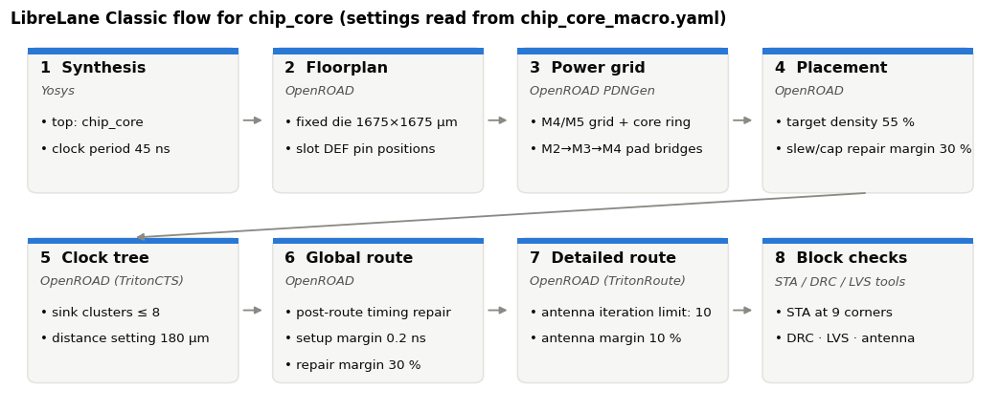

In [ ]:
# @title 16.2 · Flow diagram, generated from the configuration file
CFG_PATH = A34 / "librelane/chip_core_macro.yaml"
cfg = yaml.safe_load(CFG_PATH.read_text())
die_w, die_h = (
    cfg["DIE_AREA"][2] - cfg["DIE_AREA"][0],
    cfg["DIE_AREA"][3] - cfg["DIE_AREA"][1],
)

stages = [
    (
        "1  Synthesis",
        "Yosys",
        [
            f"top: {cfg['DESIGN_NAME']}",
            f"clock period {cfg['CLOCK_PERIOD']} ns",
        ],
    ),
    (
        "2  Floorplan",
        "OpenROAD",
        [f"fixed die {die_w}×{die_h} µm", "slot DEF pin positions"],
    ),
    (
        "3  Power grid",
        "OpenROAD PDNGen",
        ["M4/M5 grid + core ring", "M2→M3→M4 pad bridges"],
    ),
    (
        "4  Placement",
        "OpenROAD",
        [
            f"target density {cfg['PL_TARGET_DENSITY_PCT']} %",
            f"slew/cap repair margin {cfg['DESIGN_REPAIR_MAX_SLEW_PCT']} %",
        ],
    ),
    (
        "5  Clock tree",
        "OpenROAD (TritonCTS)",
        [
            f"sink clusters ≤ {cfg['CTS_SINK_CLUSTERING_SIZE']}",
            f"distance setting {cfg['CTS_DISTANCE_BETWEEN_BUFFERS']} µm",
        ],
    ),
    (
        "6  Global route",
        "OpenROAD",
        [
            (
                "post-route timing repair"
                if cfg.get("RUN_POST_GRT_RESIZER_TIMING")
                else ""
            ),
            f"setup margin {cfg['GRT_RESIZER_SETUP_SLACK_MARGIN']} ns",
            f"repair margin {cfg['GRT_DESIGN_REPAIR_MAX_SLEW_PCT']} %",
        ],
    ),
    (
        "7  Detailed route",
        "OpenROAD (TritonRoute)",
        [
            f"antenna iteration limit: {cfg['DRT_ANTENNA_REPAIR_ITERS']}",
            f"antenna margin {cfg['DRT_ANTENNA_REPAIR_MARGIN']} %",
        ],
    ),
    (
        "8  Block checks",
        "STA / DRC / LVS tools",
        ["STA at 9 corners", "DRC · LVS · antenna"],
    ),
]

fig, ax = plt.subplots(figsize=(12, 4.6))
ax.set_axis_off()
ax.set_xlim(0, 4)
ax.set_ylim(0, 2)
W, H = 0.86, 0.78
for i, (name, tool, knobs) in enumerate(stages):
    row, col = divmod(i, 4)
    x, y = col + 0.07, 1.12 - row * 1.02
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            W,
            H,
            boxstyle="round,pad=0.0,rounding_size=0.04",
            fc="#f6f6f4",
            ec=GRID,
            lw=1,
        )
    )
    ax.add_patch(Rectangle((x, y + H - 0.035), W, 0.035, fc=BLUE, ec="none"))
    ax.text(
        x + 0.05,
        y + H - 0.13,
        name,
        fontsize=10.5,
        fontweight="bold",
        color=INK,
    )
    ax.text(
        x + 0.05,
        y + H - 0.25,
        tool,
        fontsize=8 if len(tool) > 24 else 8.5,
        color=INK2,
        style="italic",
    )
    for k, line in enumerate([kn for kn in knobs if kn]):
        ax.text(
            x + 0.05,
            y + H - 0.42 - k * 0.14,
            "• " + line,
            fontsize=8.8,
            color=INK,
        )
    if col < 3:
        ax.annotate(
            "",
            xy=(x + W + 0.11, y + H / 2),
            xytext=(x + W + 0.01, y + H / 2),
            arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.2),
        )
ax.annotate(
    "",
    xy=(0.5, 0.88),
    xytext=(3.5, 1.12),
    arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.2),
)
ax.set_title(
    f"LibreLane Classic flow for {cfg['DESIGN_NAME']} (settings read from "
    f"{CFG_PATH.name})",
    pad=4,
)
fig.savefig(FIG / "16_2_flow.png", bbox_inches="tight")
plt.show()

### 16.3 Flow configuration

Every non-file setting in the configuration, with its purpose. These are inputs to the flow; the results they produced are in 16.7.

In [ ]:
# @title 16.3 · Configuration table
WHY = {
    "DESIGN_NAME": ("Hierarchy", "Top implementation module."),
    "CLOCK_PORT": ("STA / CTS", "Clock input port."),
    "CLOCK_NET": ("STA / CTS", "Named clock net."),
    "PNR_SDC_FILE": (
        "Implementation",
        "Timing constraints used during implementation.",
    ),
    "SIGNOFF_SDC_FILE": ("STA", "Timing constraints used for final analysis."),
    "FP_CORE_UTIL": (
        "Floorplan",
        "Configured core-utilization parameter; not a measured final "
        "utilization.",
    ),
    "GRT_ALLOW_CONGESTION": (
        "Global route",
        "Allows the flow to proceed with global-route congestion; final "
        "routing checks are separate.",
    ),
    "CLOCK_PERIOD": ("Synthesis / STA", "Clock target in ns."),
    "FP_DEF_TEMPLATE": (
        "Floorplan",
        "Organizer's slot DEF: fixes the die and all 72 pin positions so the "
        "block drops into the shared padframe (16.4).",
    ),
    "DIE_AREA": ("Floorplan", "Matches the slot exactly, in µm."),
    "FP_SIZING": (
        "Floorplan",
        "'absolute': the die comes from DIE_AREA rather than from a "
        "utilization target.",
    ),
    "PL_TARGET_DENSITY_PCT": ("Placement", "Global-placement density target."),
    "CTS_SINK_CLUSTERING_ENABLE": (
        "Clock tree",
        "Groups nearby flip-flops before the tree is built, reducing "
        "clock-net load.",
    ),
    "CTS_SINK_CLUSTERING_SIZE": (
        "Clock tree",
        "Maximum flip-flops per cluster.",
    ),
    "CTS_DISTANCE_BETWEEN_BUFFERS": (
        "Clock tree",
        "Desired inter-buffer distance in µm (225 in the first run, 180 from "
        "FULL2 on; 16.8); not a guaranteed bound on final routed segment "
        "length.",
    ),
    "DESIGN_REPAIR_MAX_SLEW_PCT": (
        "Placement repair",
        "Repairs slew to 30 % below the library limit, leaving headroom for "
        "routing parasitics.",
    ),
    "DESIGN_REPAIR_MAX_CAP_PCT": (
        "Placement repair",
        "Same 30 % headroom for capacitance.",
    ),
    "RUN_POST_GRT_RESIZER_TIMING": (
        "After global route",
        "Enables the post-global-route timing-repair stage using estimated "
        "parasitics.",
    ),
    "RUN_POST_GRT_DESIGN_REPAIR": (
        "After global route",
        "Second slew/cap/fanout repair with realistic wire estimates.",
    ),
    "GRT_DESIGN_REPAIR_MAX_SLEW_PCT": (
        "After global route",
        "Slew headroom for the second repair pass.",
    ),
    "GRT_RESIZER_SETUP_SLACK_MARGIN": (
        "After global route",
        "Setup slack in ns that post-global-route timing repair aims for "
        "beyond zero, leaving headroom for detailed-routing parasitics "
        "(raised during timing closure, 16.8; LibreLane default 0.025 ns).",
    ),
    "GRT_DESIGN_REPAIR_MAX_CAP_PCT": (
        "After global route",
        "Capacitance headroom for the second repair pass.",
    ),
    "DRT_ANTENNA_REPAIR_ITERS": (
        "Detailed route",
        "Antenna-repair iterations (diode insertion and re-route).",
    ),
    "DRT_ANTENNA_REPAIR_MARGIN": (
        "Detailed route",
        "Extra margin (%) on the antenna-ratio limit.",
    ),
    "VDD_NETS": (
        "Power grid",
        "Supply net names, matching the slot terminals.",
    ),
    "GND_NETS": (
        "Power grid",
        "Ground net names, matching the slot terminals.",
    ),
    "PDN_CFG": (
        "Power grid",
        "Custom power-grid script: recreates the Metal2 terminals and adds "
        "the Metal3 bridges (16.5).",
    ),
    "PDN_CORE_RING": (
        "Power grid",
        "Metal4/Metal5 ring around the core, required by the organizers for "
        "top-level projects.",
    ),
    "PDN_CORE_RING_ALLOW_OUT_OF_DIE": (
        "Power grid",
        "Disallows out-of-die ring generation; final metal/via geometry still "
        "requires checking.",
    ),
    "PDN_CORE_RING_CONNECT_TO_PADS": (
        "Power grid",
        "Disabled because the custom Metal3 bridges provide the "
        "terminal-to-grid/ring connection.",
    ),
    "PDN_EXTEND_TO": ("Power grid", "Grid straps extend to the core ring."),
}
for key in cfg:
    if key.startswith("PDN_CORE_RING_") and key not in WHY:
        meaning = (
            "ring width"
            if key.endswith("WIDTH")
            else (
                "spacing between supply rails"
                if key.endswith("SPACING")
                else (
                    "offset from core"
                    if key.endswith("OFFSET")
                    else "ring parameter"
                )
            )
        )
        WHY[key] = (
            "Power grid",
            meaning.capitalize() + " in µm; check generated geometry.",
        )
skip = {"meta", "VERILOG_FILES", "VERILOG_DEFINES"}
rows = [
    (
        k,
        v if not isinstance(v, list) else ", ".join(map(str, v)),
        *WHY.get(k, ("", "")),
    )
    for k, v in cfg.items()
    if k not in skip
]
df_cfg = pd.DataFrame(rows, columns=["Setting", "Value", "Stage", "Purpose"])
display(
    df_cfg.style.hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": "text-align:left"}])
)
print(
    f"{len(cfg['VERILOG_FILES'])} RTL source files; top module "
    f"{cfg['DESIGN_NAME']}; "
    f"defines {cfg.get('VERILOG_DEFINES')}; timing constraints "
    f"{cfg['PNR_SDC_FILE'].replace('dir::', '')}"
)

Setting,Value,Stage,Purpose
DESIGN_NAME,chip_core,Hierarchy,Top implementation module.
CLOCK_PORT,clk,STA / CTS,Clock input port.
CLOCK_NET,clk,STA / CTS,Named clock net.
CLOCK_PERIOD,45,Synthesis / STA,Clock target in ns.
CTS_SINK_CLUSTERING_ENABLE,True,Clock tree,"Groups nearby flip-flops before the tree is built, reducing clock-net load."
CTS_SINK_CLUSTERING_SIZE,8,Clock tree,Maximum flip-flops per cluster.
CTS_DISTANCE_BETWEEN_BUFFERS,180,Clock tree,"Desired inter-buffer distance in µm (225 in the first run, 180 from FULL2 on; 16.8); not a guaranteed bound on final routed segment length."
PNR_SDC_FILE,dir::chip_core.sdc,Implementation,Timing constraints used during implementation.
SIGNOFF_SDC_FILE,dir::chip_core.sdc,STA,Timing constraints used for final analysis.
FP_DEF_TEMPLATE,dir::A34_ACE_scaled.def,Floorplan,Organizer's slot DEF: fixes the die and all 72 pin positions so the block drops into the shared padframe (16.4).


20 RTL source files; top module chip_core; defines ['USE_POWER_PINS']; timing constraints chip_core.sdc


### 16.4 Floorplan: a fixed 72-terminal slot

The Chipathon places many teams' blocks on one GF180MCU die. Each team receives a DEF *template* describing its slot: the die outline and the exact position of every pin, so that the organizer's padframe connects without extra routing. A34's slot ("ACE") exposes the raw I/O-pad control interface, so the organizer-facing wrapper `chip_core` (Section 12) maps the application signals onto 72 terminals and ties the pad controls to fixed values. The cell parses the DEF directly.

A34_ACE_scaled.def: die 1675 × 1675 µm, 72 terminals, layers ['Metal2'], all within x = 0.0–1.0 µm


terminals
direction use              
INOUT     GROUND          1
          POWER           1
INPUT     SIGNAL         14
OUTPUT    SIGNAL         56

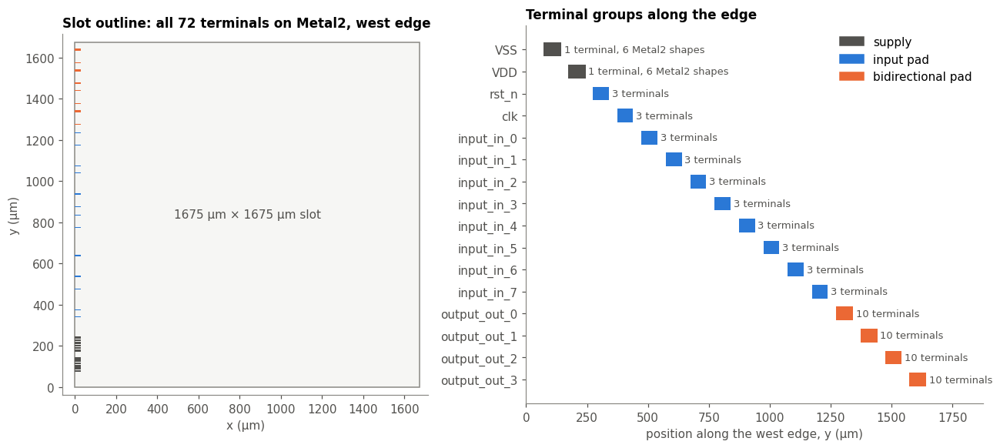

In [ ]:
# @title 16.4 · Parse the slot DEF and plot the terminal interface
def parse_def(path):
    txt = Path(path).read_text()
    dbu = int(re.search(r"UNITS DISTANCE MICRONS (\d+)", txt).group(1))
    die = [
        int(v)
        for v in re.search(
            r"DIEAREA \( (-?\d+) (-?\d+) \) \( (-?\d+) (-?\d+) \)", txt
        ).groups()
    ]
    body = txt[txt.index("\nPINS"):txt.index("END PINS")]
    pins = []
    for blk in body.split("\n- ")[1:]:
        name = blk.split()[0]
        px, py, orient = re.search(
            r"(?:FIXED|PLACED) \( (-?\d+) (-?\d+) \) (\w+)", blk
        ).groups()
        assert orient == "N", "only N-oriented pins are handled here"
        for lay, *r in re.findall(
            r"LAYER (\w+) \( (-?\d+) (-?\d+) \) \( (-?\d+) (-?\d+) \)", blk
        ):
            x0, y0, x1, y1 = (int(v) for v in r)
            pins.append(
                dict(
                    pin=name,
                    layer=lay,
                    direction=re.search(r"DIRECTION (\w+)", blk).group(1),
                    use=re.search(r"USE (\w+)", blk).group(1),
                    x0=(x0 + int(px)) / dbu,
                    y0=(y0 + int(py)) / dbu,
                    x1=(x1 + int(px)) / dbu,
                    y1=(y1 + int(py)) / dbu,
                )
            )
    return dbu, [d / dbu for d in die], pd.DataFrame(pins)


DEF_PATH = (
    A34 / "librelane" / Path(cfg["FP_DEF_TEMPLATE"].replace("dir::", "")).name
)
dbu_def, die_um, shapes = parse_def(DEF_PATH)


def group_of(p):
    m = re.match(r"(VDD|VSS|rst_n|clk|input_in_\d+|output_out_\d+)", p)
    return m.group(1) if m else p


def kind_of(g):
    return (
        "supply"
        if g in ("VDD", "VSS")
        else (
            "bidirectional pad" if g.startswith("output_out") else "input pad"
        )
    )


shapes["group"] = shapes.pin.map(group_of)
shapes["kind"] = shapes.group.map(kind_of)
n_pins = shapes.pin.nunique()
print(
    f"{DEF_PATH.name}: die {die_um[2]-die_um[0]:.0f} × "
    f"{die_um[3]-die_um[1]:.0f} µm, {n_pins} terminals, "
    f"layers {sorted(shapes.layer.unique())}, all within x = "
    f"{shapes.x0.min():.1f}–{shapes.x1.max():.1f} µm"
)
display(
    shapes.drop_duplicates("pin")
    .groupby(["direction", "use"])
    .size()
    .rename("terminals")
    .to_frame()
)

KIND_COLOR = {"supply": INK2, "input pad": BLUE, "bidirectional pad": ORANGE}
fig, (a0, a1) = plt.subplots(
    1, 2, figsize=(12, 5.4), gridspec_kw=dict(width_ratios=[1, 1.25])
)
a0.add_patch(
    Rectangle(
        (die_um[0], die_um[1]),
        die_um[2],
        die_um[3],
        fc="#f6f6f4",
        ec=MUTED,
        lw=1,
    )
)
for (
    _,
    s,
) in shapes.iterrows():  # drawn 30 µm long so they are visible at this scale
    a0.add_patch(
        Rectangle(
            (0, s.y0),
            30,
            max(s.y1 - s.y0, 2),
            fc=KIND_COLOR[s.kind],
            ec="none",
        )
    )
a0.set_xlim(-60, die_um[2] + 40)
a0.set_ylim(-40, die_um[3] + 40)
a0.set_aspect("equal")
a0.set_xlabel("x (µm)")
a0.set_ylabel("y (µm)")
a0.set_title(f"Slot outline: all {n_pins} terminals on Metal2, west edge")
a0.text(
    die_um[2] / 2,
    die_um[3] / 2,
    f"{die_um[2]:.0f} µm × {die_um[3]:.0f} µm slot",
    ha="center",
    va="center",
    color=INK2,
)
g = (
    shapes.groupby("group")
    .agg(
        y0=("y0", "min"),
        y1=("y1", "max"),
        n=("pin", "nunique"),
        rects=("pin", "size"),
        kind=("kind", "first"),
    )
    .sort_values("y0")
)
for i, (name, r) in enumerate(g.iterrows()):
    a1.barh(i, r.y1 - r.y0, left=r.y0, height=0.62, color=KIND_COLOR[r.kind])
    label = f"{r.n} terminal{'s' if r.n > 1 else ''}" + (
        f", {r.rects} Metal2 shapes" if r.rects > r.n else ""
    )
    a1.text(r.y1 + 12, i, label, va="center", fontsize=8.5, color=INK2)
a1.set_yticks(range(len(g)), g.index)
a1.invert_yaxis()
a1.set_xlabel("position along the west edge, y (µm)")
a1.set_xlim(0, die_um[3] + 200)
a1.set_title("Terminal groups along the edge")
a1.legend(
    handles=[Rectangle((0, 0), 1, 1, color=c) for c in KIND_COLOR.values()],
    labels=list(KIND_COLOR),
    loc="upper right",
    frameon=False,
)
fig.tight_layout()
fig.savefig(FIG / "16_4_pins.png", bbox_inches="tight")
plt.show()

**Database units.** The organizer's original template (`A34_ACE.def`) and the copy used in the flow (`A34_ACE_scaled.def`) describe the same geometry in different database units. The team's log records a 10× pin-placement scaling during integration that was resolved by re-expressing the template in the technology's 2000 units/µm. The cell shows how the same raw numbers become a 10× different die if read with the wrong unit.

In [ ]:
# @title 16.4b · Same geometry, different database units
rows = []
for f in ["A34_ACE.def", "A34_ACE_scaled.def"]:
    u, d, _ = parse_def(A34 / "librelane" / f)
    raw = int(
        re.search(
            r"DIEAREA \( -?\d+ -?\d+ \) \( (\d+)",
            (A34 / "librelane" / f).read_text(),
        ).group(1)
    )
    rows.append((f, u, raw, raw / u, raw / 2000))
display(
    pd.DataFrame(
        rows,
        columns=[
            "file",
            "UNITS (DBU/µm)",
            "raw die width",
            "die width (µm)",
            "width if read at 2000 DBU/µm",
        ],
    ).style.hide(axis="index")
)

file,UNITS (DBU/µm),raw die width,die width (µm),width if read at 2000 DBU/µm
A34_ACE.def,200,335000,1675.000000,167.500000
A34_ACE_scaled.def,2000,3350000,1675.000000,1675.000000


**From the 16 application pins to the 72 slot terminals.** Section 2 lists the 16 application pins: `data_in[7:0]`, `data_out[3:0]`, `clk`, `rst_n`, `VDD` and `GND`. In the slot they appear under the organizer's names, and every control input of the GF180 I/O pad cells becomes a terminal the block must drive. The next cell builds the full interface from the final netlist: for every terminal it reports what drives it.

In [ ]:
# @title 16.4c · Every slot terminal and what drives it (final netlist)
NET = (A34 / "verilog/gl/chip_core.pnl.v").read_text()
CELLS = [
    (m, n.lstrip("\\"), b)
    for m, n, b in re.findall(
        r"gf180mcu_fd_sc_mcu7t5v0__(\w+)\s+(\\?\S+)\s*\((.*?)\);",
        NET,
        flags=re.S,
    )
]
PIN_RE = re.compile(r"\.(\w+)\(([^()]*?)\)")


def pins(body):
    return {p: n.strip() for p, n in PIN_RE.findall(body)}


tie = {}  # tie-cell output net -> constant value
for m, n, b in CELLS:
    if m.startswith(("tiel", "tieh")):
        P = pins(b)
        tie[P.get("ZN") or P.get("Z")] = 1 if m.startswith("tieh") else 0
port_net = dict(re.findall(r"assign (\w+) = (\S+?);", NET))
connected = {v for _, _, b in CELLS for v in pins(b).values()}

APP = {"clk": "clk", "rst_n": "rst_n", "VDD": "VDD", "VSS": "GND"}
APP.update({f"input_in_{i}": f"data_in[{i}]" for i in range(8)})
APP.update({f"output_out_{i}_OUT": f"data_out[{i}]" for i in range(4)})

rows = []
for pin, d in shapes.drop_duplicates("pin").set_index("pin").direction.items():
    if pin in ("VDD", "VSS"):
        role = "supply"
    elif port_net.get(pin) in tie:
        role = (
            f"tied to {tie[port_net[pin]]} by a "
            f"tie-{'high' if tie[port_net[pin]] else 'low'} cell"
        )
    elif d == "INPUT":
        role = (
            "pad → logic"
            if pin in connected
            else "pad input, unconnected inside the block"
        )
    else:
        role = "logic → pad"
    rows.append(
        dict(
            terminal=re.sub(r"_\d+(_|$)", r"_N\1", pin),
            pin=pin,
            direction=d,
            role=role,
            section2=APP.get(pin, ""),
        )
    )
term = pd.DataFrame(rows)
grouped = (
    term.groupby(["terminal", "direction", "role"], sort=False)
    .agg(
        count=("pin", "size"),
        section2_signal=(
            "section2",
            lambda s: ", ".join(x for x in s if x) or "—",
        ),
    )
    .reset_index()
)
display(
    grouped.style.hide(axis="index").set_properties(**{"text-align": "left"})
)

n_tied = term.role.str.startswith("tied").sum()
ties = pd.Series(list(tie.values()))
print(
    f"{len(term)} terminals: {n_tied} tied to constants, "
    f"{(term.role == 'pad → logic').sum()} pad inputs used by the logic, "
    f"{(term.role == 'logic → pad').sum()} driven by the logic, "
    f"{(term.role == 'pad input, unconnected inside the block').sum()} "
    f"unconnected pad inputs, 2 supplies."
)
one_each = n_tied == len(tie) == len(
    set(port_net[p] for p in term.pin if port_net.get(p) in tie)
)
print(
    f"Tie cells in the netlist: {len(tie)} ({(ties == 0).sum()} tie-low, "
    f"{(ties == 1).sum()} tie-high); "
    f"each drives exactly one pad-control terminal: {one_each}"
)
assert len(term) == 72 and n_tied == len(tie)

terminal,direction,role,count,section2_signal
VSS,INOUT,supply,1,GND
VDD,INOUT,supply,1,VDD
rst_n_PU,OUTPUT,tied to 0 by a tie-low cell,1,—
rst_n_PD,OUTPUT,tied to 0 by a tie-low cell,1,—
rst_n,INPUT,pad → logic,1,rst_n
clk_PU,OUTPUT,tied to 0 by a tie-low cell,1,—
clk_PD,OUTPUT,tied to 0 by a tie-low cell,1,—
clk,INPUT,pad → logic,1,clk
input_in_N_PU,OUTPUT,tied to 0 by a tie-low cell,8,—
input_in_N_PD,OUTPUT,tied to 0 by a tie-low cell,8,—


72 terminals: 52 tied to constants, 10 pad inputs used by the logic, 4 driven by the logic, 4 unconnected pad inputs, 2 supplies.
Tie cells in the netlist: 52 (48 tie-low, 4 tie-high); each drives exactly one pad-control terminal: True


Names to keep in mind when reading Section 2 next to the layout: `data_in[i]` is terminal `input_in_i`, `data_out[i]` is `output_out_i_OUT`, and `GND` is `VSS`. The four bidirectional pads are used as outputs only. Output enable (`OE`) is tied to 1. Input enable (`IE`), the pull-up/pull-down enables and the drive-strength selects (`PDRV1:PDRV0` = 00, the 4 mA setting) are tied to 0. The pads' input returns (`output_out_i_IN`) are left unconnected (lesson 4).

### 16.5 Power delivery: connecting the slot's power terminals to the grid

The debugging described here was done during earlier development runs of this block. The final layout uses the same script, bridges and ring, and every check in this subsection runs on the final layout.

**The problem.** The block's power grid uses vertical Metal4 and horizontal Metal5 straps. The slot's VDD and VSS terminals are short Metal2 rectangles on the west edge, six per net (16.4). The block passed its own DRC and LVS, but integration feedback showed nothing physically joined the terminals to the grid.

**Why the obvious fix failed.** In the Classic flow, the DEF template is applied at step 27, *after* power-grid generation at step 21. When PDNGen ran, the VDD/VSS ports existed but had no Metal2 geometry to connect to. The sequence of experiments:

| Test | Change | Outcome |
|---|---|---|
| 1 | Metal3 stripes with Metal2–Metal3 and Metal3–Metal4 connections | `PDN-0112`: no Metal2 shapes available |
| 2 | `USE_POWER_PINS` define | VDD/VSS ports exist, still without terminal geometry |
| 3 | Copy power pins from the template | Same missing-shape error at power-grid generation |
| 4 | Create the Metal2 terminal geometry inside the PDN script, before connecting | Progresses, then `PDN-0179` channel-repair failure from the full-width stripes |
| 5 | Replace full-width stripes with short Metal3 routing shapes | Shapes placed; connection method still being adjusted |
| 6 | Connect the pre-drawn shapes through a dedicated `-existing` grid | Power grid generated; `check_power_grid` reports all VDD and VSS shapes connected |

The first full run then failed at template application (`VDD not found in template layout`); removing the experimental template power-pin copying setting from test 3 cleared that failure.

**The fix** (`librelane/pdn_cfg_a34.tcl`). The script recreates the twelve Metal2 terminal rectangles with coordinates copied from the DEF, draws a 30 µm Metal3 bridge from each terminal into the core, and lets PDNGen place Metal2→Metal3 vias at the terminal and Metal3→Metal4 vias where a bridge crosses its own net's Metal4. After the organizers required a core ring for top-level projects, a Metal4/Metal5 ring was added inside the measured margin between the die edge and the core. The bridge part of the script:

In [ ]:
# @title 16.5a · The bridge section of the custom PDN script
tcl = (A34 / "librelane/pdn_cfg_a34.tcl").read_text().splitlines()
start = next(i for i, l in enumerate(tcl) if "A34_LOCAL_METAL3_BRIDGES" in l)
end = next(i for i, l in enumerate(tcl) if '-layers "Metal2 Metal3"' in l)
print(
    "\n".join(
        f"{i+1:4d}  {l}" for i, l in enumerate(tcl[start:end + 1], start)
    )
)

 289  # A34_LOCAL_METAL3_BRIDGES
 290  #
 291  # Use short existing-routing shapes rather than full-width PDN stripes.
 292  # They extend only 30 um from the left boundary, reaching the first
 293  # Metal4 VDD/VSS strap pair without crossing the complete core.
 294  set a34_metal3 [[ord::get_db_tech] findLayer Metal3]
 295  set a34_bridge_xmax 60000
 296  set a34_bridge_half_width 1600
 297  
 298  foreach a34_net_name {VSS VDD} {
 299      set a34_net [$a34_block findNet $a34_net_name]
 300  
 301      if {$a34_net == "NULL"} {
 302          error "A34 bridge: unable to find net $a34_net_name"
 303      }
 304  
 305      set a34_swire [odb::dbSWire_create $a34_net "ROUTED"]
 306  
 307      foreach a34_bterm [$a34_net getBTerms] {
 308          foreach a34_bpin [$a34_bterm getBPins] {
 309              foreach a34_box [$a34_bpin getBoxes] {
 310                  set a34_layer [$a34_box getTechLayer]
 311  
 312                  if {$a34_layer == "NULL"} {
 313                      

**Geometric inspection of the final bridges.** For each of twelve DEF power-terminal regions, the next cell measures the overlapping Metal3 bridge and counts Via2/Via3 cut shapes covered by the bridge and the respective landing metals. The counts and positions corroborate the net-aware OpenROAD result in 16.5d. They do not independently establish full net connectivity, DRC enclosure compliance, absence of shorts or current capacity.


In [ ]:
# @title 16.5b · Bridge-by-bridge measurement (from the GDS)
GDS = A34 / "gds/chip_core.gds"
L = kdb.Layout()
L.read(str(GDS))
TOP = L.top_cell()
DBU = L.dbu
gds_box = TOP.bbox()
gds_bounds_um = [
    v * DBU for v in (gds_box.left, gds_box.bottom, gds_box.right, gds_box.top)
]
assert TOP.name == cfg["DESIGN_NAME"] and abs(DBU - 0.001) < 1e-12
assert all(
    abs(a - b) < 1e-9 for a, b in zip(gds_bounds_um, die_um)
), "GDS and DEF boundaries differ"
LAYER = {
    "Metal2": (36, 0),
    "Via2": (38, 0),
    "Metal3": (42, 0),
    "Via3": (40, 0),
    "Metal4": (46, 0),
    "Metal5": (81, 0),
}


def rgn(layer, box_um):
    li = L.find_layer(*LAYER[layer])
    return kdb.Region(
        TOP.begin_shapes_rec_touching(li, kdb.DBox(*box_um).to_itype(DBU))
    )


def clusters(xs, gap=2.0):
    out = []
    for x in sorted(xs):
        if out and x - out[-1][1] <= gap:
            out[-1][1] = x
        else:
            out.append([x, x])
    return out


# Core boundary from OpenDB (CORE vs DIE of the final database): margins in µm
CORE_MARGIN = {"left": 6.72, "right": 6.76, "bottom": 15.68, "top": 16.84}
west_ring = sorted(
    (round(p.bbox().left * DBU, 2), round(p.bbox().right * DBU, 2))
    for p in rgn("Metal4", (0, 0, CORE_MARGIN["left"], die_um[3]))
    .merged()
    .each()
    if p.bbox().height() * DBU > 1000
)

rows = []
for _, s in (
    shapes[shapes.use.isin(["POWER", "GROUND"])].sort_values("y0").iterrows()
):
    term = (s.x0, s.y0, s.x1, s.y1)
    m3 = rgn("Metal3", term).merged()
    if m3.is_empty():
        rows.append(
            dict(
                net=s.pin,
                terminal_y_um=f"{s.y0:.1f}–{s.y1:.1f}",
                bridge="none",
            )
        )
        continue
    bridge = max(m3.each(), key=lambda p: p.area())
    b = bridge.bbox()
    br = kdb.Region(bridge)
    v2 = (
        rgn("Via2", term)
        .inside(kdb.Region(kdb.DBox(*term).to_itype(DBU)))
        .inside(br)
        .inside(rgn("Metal2", term))
    )
    bridge_box = (b.left * DBU, b.bottom * DBU, b.right * DBU, b.top * DBU)
    v3 = rgn("Via3", bridge_box).inside(br).inside(rgn("Metal4", bridge_box))
    land = clusters([p.bbox().center().x * DBU for p in v3.each()])
    ring = [
        f"{a:.2f}–{c:.2f}"
        for a, c in west_ring
        if any(a <= x0 and x1 <= c for x0, x1 in land)
    ]
    rows.append(
        dict(
            net=s.pin,
            terminal_y_um=f"{s.y0:.1f}–{s.y1:.1f}",
            bridge_um=f"{(b.right - b.left) * DBU:.1f} × "
                      f"{(b.top - b.bottom) * DBU:.1f}",
            via2_M2_M3=v2.count(),
            via3_M3_M4=v3.count(),
            via3_lands_at_x_um=", ".join(f"{a:.1f}–{c:.1f}" for a, c in land),
            ring_side_x_um=ring[0] if ring else "none",
        )
    )
pdn = pd.DataFrame(rows)
display(pdn.style.hide(axis="index"))

ok = pdn[(pdn.via2_M2_M3 > 0) & (pdn.via3_M3_M4 > 0)]
sides = pdn.groupby("net").ring_side_x_um.unique()
print(
    f"{len(ok)} of {len(pdn)} power terminals contain bridge cut shapes "
    f"covered by the corresponding landing metals."
)
for net, side in sides.items():
    print(
        f"  {net}-labeled terminal bridges have cut clusters within the west "
        f"ring band at x = {', '.join(side)} µm (plus one grid strap)"
    )
assert (
    len(ok) == 12 and len(pdn) == 12
), "A terminal region lacks the expected bridge/landing geometry."
print(
    "Geometry check only; terminal net names come from the DEF. Net-aware "
    "connectivity evidence is recorded separately in 16.5d."
)
print(
    f"GDS top {TOP.name}: bounds {gds_bounds_um} µm; database unit {DBU} µm; "
    f"matches the DEF."
)

net,terminal_y_um,bridge_um,via2_M2_M3,via3_M3_M4,via3_lands_at_x_um,ring_side_x_um
VSS,71.4–80.9,30.0 × 1.6,6,18,"1.3–2.3, 25.8–26.9",1.02–2.62
VSS,83.8–94.0,30.0 × 1.6,6,18,"1.3–2.3, 25.8–26.9",1.02–2.62
VSS,95.6–105.9,30.0 × 1.6,6,18,"1.3–2.3, 25.8–26.9",1.02–2.62
VSS,109.1–119.4,30.0 × 1.6,6,18,"1.3–2.3, 25.8–26.9",1.02–2.62
VSS,121.0–131.2,30.0 × 1.6,6,18,"1.3–2.3, 25.8–26.9",1.02–2.62
VSS,134.1–143.6,30.0 × 1.6,6,18,"1.3–2.3, 25.8–26.9",1.02–2.62
VDD,171.4–180.9,30.0 × 1.6,6,18,"4.6–5.6, 22.5–23.6",4.32–5.92
VDD,183.8–194.0,30.0 × 1.6,6,18,"4.6–5.6, 22.5–23.6",4.32–5.92
VDD,195.6–205.9,30.0 × 1.6,6,18,"4.6–5.6, 22.5–23.6",4.32–5.92
VDD,209.1–219.4,30.0 × 1.6,6,18,"4.6–5.6, 22.5–23.6",4.32–5.92


12 of 12 power terminals contain bridge cut shapes covered by the corresponding landing metals.
  VDD-labeled terminal bridges have cut clusters within the west ring band at x = 4.32–5.92 µm (plus one grid strap)
  VSS-labeled terminal bridges have cut clusters within the west ring band at x = 1.02–2.62 µm (plus one grid strap)
Geometry check only; terminal net names come from the DEF. Net-aware connectivity evidence is recorded separately in 16.5d.
GDS top chip_core: bounds [0.0, 0.0, 1675.0, 1675.0] µm; database unit 0.001 µm; matches the DEF.


**Fitting the ring inside the margin.** The core edges lie 6.72 µm (left), 6.76 µm (right), 15.68 µm (bottom) and 16.84 µm (top) inside the die edge; the next cell confirms them against the core area reported by the final run. Each side has one VDD rail and one VSS rail: 1.6 µm width, 1.7 µm inter-rail spacing and 0.8 µm inner offset. The cell measures the four ring-metal bands in the GDS against those core edges. It does not replace a check of all via enclosures.

In [ ]:
# @title 16.5c · Core ring versus the available margin (from the GDS)
core_w = die_um[2] - CORE_MARGIN["left"] - CORE_MARGIN["right"]
core_h = die_um[3] - CORE_MARGIN["bottom"] - CORE_MARGIN["top"]
reported = RUN_METRICS["design__core__area"]
print(
    f"Core from these margins: {core_w:.2f} × {core_h:.2f} µm = "
    f"{core_w * core_h:,.0f} µm²; "
    f"final-run metrics report {reported:,} µm²."
)
assert (
    abs(core_w * core_h - reported) / reported < 1e-5
), "Core margins do not match the final run"


def ring_side(side):
    W, Hh = die_um[2], die_um[3]
    if side in ("left", "right"):
        box = (
            (0, 0, CORE_MARGIN["left"], Hh)
            if side == "left"
            else (W - CORE_MARGIN["right"], 0, W, Hh)
        )
        spans = [
            (p.bbox().left * DBU, p.bbox().right * DBU)
            for p in rgn("Metal4", box).merged().each()
            if p.bbox().height() * DBU > 1000
        ]
    else:
        box = (
            (0, 0, W, CORE_MARGIN["bottom"])
            if side == "bottom"
            else (0, Hh - CORE_MARGIN["top"], W, Hh)
        )
        spans = [
            (p.bbox().bottom * DBU, p.bbox().top * DBU)
            for p in rgn("Metal5", box).merged().each()
            if p.bbox().width() * DBU > 1000
        ]
    lo, hi = min(a for a, _ in spans), max(b for _, b in spans)
    edge = W if side == "right" else Hh if side == "top" else 0
    core = (
        CORE_MARGIN[side]
        if side in ("left", "bottom")
        else edge - CORE_MARGIN[side]
    )
    to_core = core - hi if side in ("left", "bottom") else lo - core
    to_die = lo if side in ("left", "bottom") else edge - hi
    return dict(
        side=side,
        layer="Metal4" if side in ("left", "right") else "Metal5",
        ring_shapes=len(spans),
        ring_extent_um=f"{lo:.2f}–{hi:.2f}",
        core_boundary_um=f"{core:.2f}",
        clearance_to_core_um=round(to_core, 2),
        clearance_to_die_edge_um=round(to_die, 2),
    )


ring = pd.DataFrame([ring_side(s) for s in ("left", "right", "bottom", "top")])
display(ring.style.hide(axis="index").format(precision=2))
inside = (ring.clearance_to_core_um > 0).all() and (
    ring.clearance_to_die_edge_um > 0
).all()
assert (
    inside and (ring.ring_shapes == 2).all()
), "Unexpected ring-metal geometry"
print(
    "Measured ring-metal bands fit between the core edges and the die on all "
    "four sides. Via enclosure and full DRC are separate checks."
)

Core from these margins: 1661.52 × 1642.48 µm = 2,729,013 µm²; final-run metrics report 2,729,010 µm².


side,layer,ring_shapes,ring_extent_um,core_boundary_um,clearance_to_core_um,clearance_to_die_edge_um
left,Metal4,2,1.02–5.92,6.72,0.80,1.02
right,Metal4,2,1669.04–1673.94,1668.24,0.80,1.06
bottom,Metal5,2,9.98–14.88,15.68,0.80,9.98
top,Metal5,2,1658.96–1663.86,1658.16,0.80,11.14


Measured ring-metal bands fit between the core edges and the die on all four sides. Via enclosure and full DRC are separate checks.


**16.5d OpenROAD connectivity check on the final database.** After the final run, `check_final_eco.tcl` loaded its OpenDB database, counted the Metal2 terminals and ring sides of each supply net, looked for power shapes outside the die, and ran OpenROAD's `check_power_grid` on VDD and VSS. The next cell parses the committed log. The GDS views in 16.5b–c are geometric; this check uses OpenROAD's net-aware connectivity model. Neither establishes pad-fed IR drop or electromigration capacity.

In [ ]:
# @title 16.5d · OpenROAD power-connectivity log of the final database
pglog = (ECO_DIR / "final_odb_check.log").read_text()
pgtcl = (ECO_DIR / "check_final_eco.tcl").read_text()
rows = []
for net in ("VDD", "VSS"):
    m = re.search(
        rf"A34_POWER {net} M2=(\d+) vertical_ring=(\d+) horizontal_ring=(\d+) "
        rf"outside=(\d+)",
        pglog,
    )
    rows.append(
        dict(
            net=net,
            metal2_terminals=int(m[1]),
            vertical_ring_sides=int(m[2]),
            horizontal_ring_sides=int(m[3]),
            shapes_outside_die=int(m[4]),
            check_power_grid=(
                "all shapes connected"
                if f"All shapes on net {net} are connected." in pglog
                else "NOT CONNECTED"
            ),
        )
    )
pg = pd.DataFrame(rows)
display(pg.style.hide(axis="index"))
print(
    "Database checked:",
    re.search(r'read_db "([^"]+)"', pgtcl)[1].split("/librelane/")[-1],
)
assert "A34_FINAL_ODB_CHECK_COMPLETE" in pglog
assert (pg.check_power_grid == "all shapes connected").all() and (
    pg.metal2_terminals == 6
).all()
assert (pg.vertical_ring_sides == 2).all() and (
    pg.horizontal_ring_sides == 2
).all() and (pg.shapes_outside_die == 0).all()
print("The same final directory produced the committed GDS (hashes in 16.7a).")

net,metal2_terminals,vertical_ring_sides,horizontal_ring_sides,shapes_outside_die,check_power_grid
VDD,6,2,2,0,all shapes connected
VSS,6,2,2,0,all shapes connected


Database checked: runs/A34_Q16_ECO_FULL4_20261015_160735/final/odb/chip_core.odb
The same final directory produced the committed GDS (hashes in 16.7a).


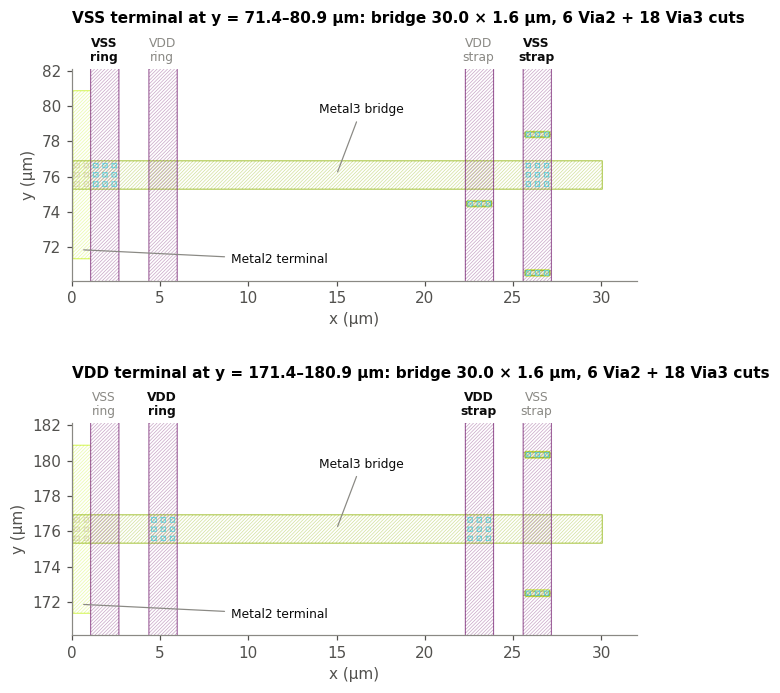

In [ ]:
# @title 16.5e · Close-up of one VSS and one VDD bridge
def render(box_um, png, layers, width=1600, height=None):
    lv = klay.LayoutView()
    for k, v in [
        ("grid-visible", "false"),
        ("text-visible", "false"),
        ("background-color", "#ffffff"),
    ]:
        lv.set_config(k, v)
    lv.load_layout(str(GDS), 0)
    lv.max_hier()
    lv.load_layer_props(str(LYP))
    keep = {LAYER[n] for n in layers}
    for lp in lv.each_layer():
        lp.visible = (lp.source_layer, lp.source_datatype) in keep
    b = kdb.DBox(*box_um)
    height = height or int(width * b.height() / b.width())
    lv.save_image_with_options(str(png), width, height, 2, 0, 0, b, False)
    return png


import matplotlib.image as mpimg

fig, axes = plt.subplots(2, 1, figsize=(11, 6.4))
for ax, net in zip(axes, ["VSS", "VDD"]):
    s = shapes[shapes.pin == net].sort_values("y0").iloc[0]
    yc = (s.y0 + s.y1) / 2
    box = (0, yc - 6, 32, yc + 6)
    png = render(
        box,
        FIG / f"16_5_bridge_{net}.png",
        ["Metal2", "Via2", "Metal3", "Via3", "Metal4"],
        width=1300,
    )
    ax.imshow(mpimg.imread(png), extent=(box[0], box[2], box[1], box[3]))
    row = pdn[
        (pdn.net == net) & (pdn.terminal_y_um == f"{s.y0:.1f}–{s.y1:.1f}")
    ].iloc[0]
    ax.set_title(
        f"{net} terminal at y = {row.terminal_y_um} µm: bridge "
        f"{row.bridge_um} µm, "
        f"{row.via2_M2_M3} Via2 + {row.via3_M3_M4} Via3 cuts",
        fontsize=10,
        pad=30,
    )
    ax.set_xlabel("x (µm)")
    ax.set_ylabel("y (µm)")
    other = "VDD" if net == "VSS" else "VSS"
    land = [
        tuple(map(float, r.split("–")))
        for r in row.via3_lands_at_x_um.split(", ")
    ]
    for p in (
        rgn("Metal4", box).merged().each()
    ):  # label every full-height Metal4 line in view
        a, c = p.bbox().left * DBU, p.bbox().right * DBU
        if p.bbox().height() * DBU < (box[3] - box[1]) * 0.9:
            continue
        owner = net if any(a <= x0 and x1 <= c for x0, x1 in land) else other
        kind = "ring" if a < CORE_MARGIN["left"] else "strap"
        ax.text(
            (a + c) / 2,
            box[3] + 0.3,
            f"{owner}\n{kind}",
            ha="center",
            va="bottom",
            fontsize=8,
            linespacing=1.1,
            color=INK if owner == net else MUTED,
            fontweight="bold" if owner == net else "normal",
            clip_on=False,
        )
    ax.annotate(
        "Metal2 terminal",
        xy=(0.5, s.y0 + 0.5),
        xytext=(9, box[1] + 1.0),
        fontsize=8,
        color=INK,
        arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8),
    )
    ax.annotate(
        "Metal3 bridge",
        xy=(15, yc),
        xytext=(14, yc + 3.5),
        fontsize=8,
        color=INK,
        arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8),
    )
fig.tight_layout(h_pad=2.5)
fig.savefig(FIG / "16_5_bridges.png", bbox_inches="tight")
plt.show()

The labels below associate bridge cut clusters with ring/strap positions geometrically. Supply labels are inferred from the corresponding DEF terminal and the ODB check in 16.5d, rather than electrically extracted from this rendering. Crossing another rail without a via does not itself establish that the complete network is free of shorts.


### 16.6 The final layout

The render shows only the routing metals (Metal2–Metal5) and vias, which makes the power grid, the ring and the signal routing visible. With every layer shown, they would be hidden under the filler and decoupling cells that cover the unused part of the slot.

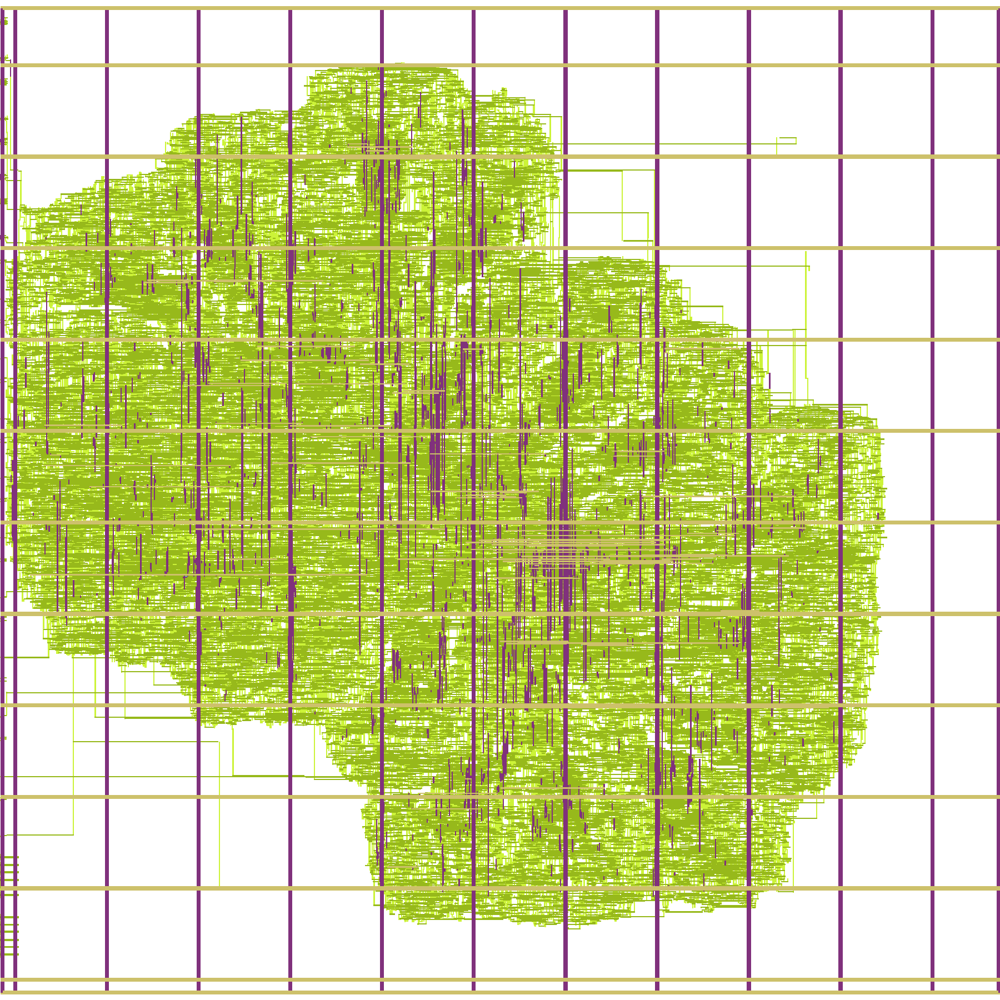

In [ ]:
# @title 16.6a · A34 block render (routing layers)
png = render(
    (0, 0, die_um[2], die_um[3]),
    FIG / "16_6_layout_routing.png",
    ["Metal2", "Via2", "Metal3", "Via3", "Metal4", "Metal5"],
    width=1800,
)
display(Image(str(png), width=720))

The committed GDS retains instance names, and the final netlist retains hierarchical names on many register-output nets. These support three views: name/master-based cell categories, inferred RTL register groups, and clock-buffer connectivity. Instance names alone do not prove the exact stage that created each cell. Footprints are measured from standard-cell placement boundaries and divided by the complete slot area; this is not a report of core placement utilization.


Total placed instances: 119,247, including physical-only cells.
Selected group: 34,104 instances excluding filler/decap, taps and endcaps; includes clock-load and antenna cells.
Selected placement-boundary footprint: 0.906 mm² = 32.3% of the 2.805625 mm² slot.
Origin labels are inferred from names; no exact per-stage additions are claimed without checkpoint differences.


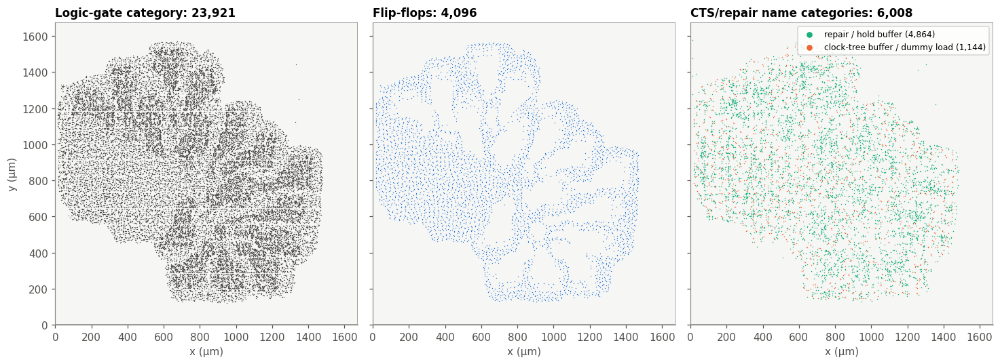

In [ ]:
# @title 16.6b · Placed cell categories (stage labels inferred from names)
PRB = L.find_layer(0, 0)  # standard-cell placement boundary layer


def inst_name(i):
    return dict(L.properties(i.prop_id)).get(61, "") if i.prop_id else ""


REPAIR = ("fanout", "max_cap", "wire", "load_slew", "rebuffer", "split")


def origin(name, master):
    m = master.split("__")[-1]
    if name.startswith("FILLER"):
        return "filler / decap", "fill insertion"
    if name.startswith("TAP_"):
        return "well tap", "floorplan"
    if name.startswith("PHY_EDGE"):
        return "row endcap", "floorplan"
    if name.startswith("clkload"):
        return "clock-tree dummy load", "clock-tree synthesis"
    if name.startswith("clkbuf_"):
        return "clock-tree buffer", "clock-tree synthesis"
    if name.startswith("hold"):
        return "hold-fix buffer", "timing repair"
    if name.startswith(REPAIR):
        return "slew/cap/fanout repair buffer", "design repair"
    if name.startswith(("input", "output")):
        return "I/O port buffer", "port buffering"
    if name.startswith("ANTENNA"):
        return "antenna diode", "antenna repair"
    if m.startswith(("tiel", "tieh")):
        return "tie-high/low cell", "stage not derived"
    if m.startswith(("dff", "sdff", "lat")):
        return "flip-flop", "stage not derived"
    return "logic gate", "stage not derived"


inst = pd.DataFrame(
    [
        (inst_name(i), i.cell.name, c.x, c.y)
        for i in TOP.each_inst()
        for c in [i.dbbox().center()]
    ],
    columns=["name", "master", "x", "y"],
)
area_of = {
    n: (lambda b: b.width() * b.height())(L.cell(n).dbbox_per_layer(PRB))
    for n in inst.master.unique()
}
inst["area_um2"] = inst.master.map(area_of)
inst[["kind", "added_by"]] = [
    origin(n, m) for n, m in zip(inst.name, inst.master)
]

die_mm2 = die_um[2] * die_um[3] / 1e6
stats = (
    inst.groupby(["added_by", "kind"])
    .agg(
        instances=("name", "size"),
        area_mm2=("area_um2", lambda a: a.sum() / 1e6),
    )
    .sort_values("instances", ascending=False)
)
stats["share_of_slot_%"] = 100 * stats.area_mm2 / die_mm2
display(
    stats.style.format(
        {
            "instances": "{:,}",
            "area_mm2": "{:.3f}",
            "share_of_slot_%": "{:.1f}",
        }
    )
)

selected = inst[~inst.kind.isin(["filler / decap", "well tap", "row endcap"])]
print(f"Total placed instances: {len(inst):,}, including physical-only cells.")
print(
    f"Selected group: {len(selected):,} instances excluding filler/decap, "
    f"taps and endcaps; includes clock-load and antenna cells."
)
print(
    f"Selected placement-boundary footprint: "
    f"{selected.area_um2.sum()/1e6:.3f} mm² = "
    f"{100*selected.area_um2.sum()/1e6/die_mm2:.1f}% of the {die_mm2:.6f} mm² "
    f"slot."
)
print(
    "Origin labels are inferred from names; no exact per-stage additions are "
    "claimed without checkpoint differences."
)
assert len(inst) == 119247, "Unexpected count for pinned GDS"

panels = [
    ("Logic-gate category", inst.kind == "logic gate", [(INK2, "logic gate")]),
    ("Flip-flops", inst.kind == "flip-flop", [(BLUE, "flip-flop")]),
    (
        "CTS/repair name categories",
        inst.added_by.isin(
            ["clock-tree synthesis", "design repair", "timing repair"]
        ),
        [
            (ORANGE, "clock-tree buffer / dummy load"),
            (AQUA, "repair / hold buffer"),
        ],
    ),
]
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.9), sharey=True)
for ax, (title, sel, series) in zip(axes, panels):
    ax.add_patch(
        Rectangle((0, 0), die_um[2], die_um[3], fc="#f6f6f4", ec=MUTED, lw=1)
    )
    d = inst[sel]
    if len(series) == 1:
        ax.scatter(d.x, d.y, s=0.8, c=series[0][0], lw=0, rasterized=True)
    else:
        cts = d.added_by == "clock-tree synthesis"
        ax.scatter(
            d[~cts].x,
            d[~cts].y,
            s=0.9,
            c=series[1][0],
            lw=0,
            rasterized=True,
            label=f"{series[1][1]} ({(~cts).sum():,})",
        )
        ax.scatter(
            d[cts].x,
            d[cts].y,
            s=0.9,
            c=series[0][0],
            lw=0,
            rasterized=True,
            label=f"{series[0][1]} ({cts.sum():,})",
        )
        ax.legend(loc="upper right", markerscale=6, fontsize=8, frameon=True)
    ax.set_xlim(0, die_um[2])
    ax.set_ylim(0, die_um[3])
    ax.set_aspect("equal")
    ax.set_title(f"{title}: {len(d):,}")
    ax.set_xlabel("x (µm)")
axes[0].set_ylabel("y (µm)")
fig.tight_layout()
fig.savefig(FIG / "16_6_cell_map.png", bbox_inches="tight")
plt.show()

**Inferred register groups.** The analysis associates flip-flops with RTL groups using preserved output-net names and the known flattening of A/B buses. The plots show register positions and group centroids; they are not macro boundaries. The placer positions registers by connectivity and timing, not by the logical 4×4 grid, so the logical neighbors need not be physical neighbors. Arrows indicate logical neighboring-PE relationships, not routed metal paths. Unclassified names remain in an explicit control/other category.


,flip_flops,centroid_x_um,centroid_y_um,rms_spread_um
block,,,,
"PE(0,0)",102,271,1189,196
"PE(0,1)",102,465,1266,220
"PE(0,2)",102,653,1296,293
"PE(0,3)",86,833,1283,225
"PE(1,0)",102,578,1132,172
"PE(1,1)",102,827,992,144
"PE(1,2)",102,727,537,153
"PE(1,3)",86,1311,796,201
"PE(2,0)",102,986,1015,180


4,096 flip-flops classified into 22 name-based groups; 1,504 belong to the 16 PEs.


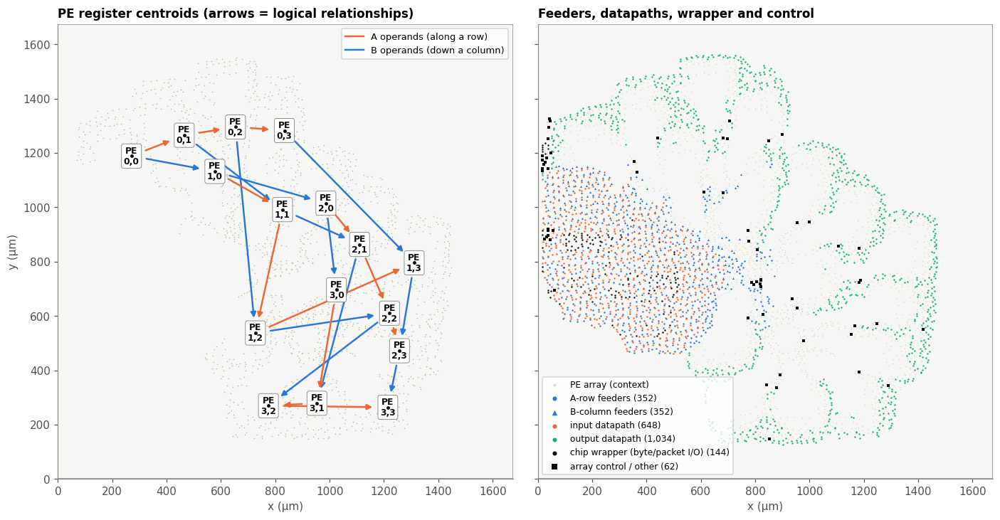

In [ ]:
# @title 16.6c · Where each RTL block's registers were placed
NET = (A34 / "verilog/gl/chip_core.pnl.v").read_text()
CELLS = [
    (m, n.lstrip("\\"), b)
    for m, n, b in re.findall(
        r"gf180mcu_fd_sc_mcu7t5v0__(\w+)\s+(\\?\S+)\s*\((.*?)\);",
        NET,
        flags=re.S,
    )
]
PIN_RE = re.compile(r"\.(\w+)\(([^()]*?)\)")


def pins(body):
    return {p: n.strip() for p, n in PIN_RE.findall(body)}


POS = dict(zip(inst.name, zip(inst.x, inst.y)))


def block_of(q):
    q = q.lstrip("\\").replace("chip_core_internal_i.", "", 1)
    if m := re.match(r"systolic_i\.ROW\[(\d)\]\.COL\[(\d)\]", q):
        return f"PE({m[1]},{m[2]})"
    if m := re.match(
        r"systolic_i\.A_bus\[(\d+)\]", q
    ):  # wire [15:0] A_bus[0:3][0:4], flattened row-major
        r, c = divmod(int(m[1]), 5)
        return (
            f"PE({r},{c - 1})" if c else "A-row feeders"
        )  # A_bus[r][0] is the feeder's output word
    if m := re.match(
        r"systolic_i\.B_bus\[(\d+)\]", q
    ):  # wire [15:0] B_bus[0:4][0:3], flattened row-major
        r, c = divmod(int(m[1]), 4)
        return f"PE({r - 1},{c})" if r else "B-column feeders"
    if q.startswith("systolic_i.gen_A_rows"):
        return "A-row feeders"
    if q.startswith("systolic_i.gen_B_cols"):
        return "B-column feeders"
    if q.startswith(
        ("systolic_i.input_dp", "systolic_i.A_r[", "systolic_i.B_c[")
    ):
        return "input datapath"
    if q.startswith("systolic_i.output_dp"):
        return "output datapath"
    if q.startswith(
        ("packet_buffer", "byte_count", "packet_count", "output_count")
    ):
        return "chip wrapper (byte/packet I/O)"
    return "array control / other"


ff = pd.DataFrame(
    [
        (n, block_of(pins(b)["Q"]), *POS[n])
        for m, n, b in CELLS
        if m.startswith(("dff", "sdff", "lat"))
    ],
    columns=["name", "block", "x", "y"],
)
ff["group"] = ff.block.where(
    ~ff.block.str.startswith("PE("), "PE array (16 PEs)"
)
expected_pes = {f"PE({r},{c})" for r in range(4) for c in range(4)}
assert (
    set(ff.block[ff.block.str.startswith("PE(")]) == expected_pes
), "unexpected PE indices"
summary = ff.groupby("block").agg(
    flip_flops=("name", "size"),
    centroid_x_um=("x", "mean"),
    centroid_y_um=("y", "mean"),
)
summary["rms_spread_um"] = ff.groupby("block").apply(
    lambda d: (
        (d.x - d.x.mean()) ** 2 + (d.y - d.y.mean()) ** 2
    ).mean() ** 0.5,
    include_groups=False,
)
order = sorted(summary.index, key=lambda b: (not b.startswith("PE("), b))
display(summary.loc[order].style.format("{:.0f}"))
print(
    f"{len(ff):,} flip-flops classified into {ff.block.nunique()} name-based "
    f"groups; "
    f"{(ff.group == 'PE array (16 PEs)').sum():,} belong to the 16 PEs."
)

cent = summary[["centroid_x_um", "centroid_y_um"]]
fig, (a0, a1) = plt.subplots(1, 2, figsize=(13, 6.4), sharey=True)
for ax in (a0, a1):
    ax.add_patch(
        Rectangle((0, 0), die_um[2], die_um[3], fc="#f6f6f4", ec=MUTED, lw=1)
    )
    ax.set_xlim(0, die_um[2])
    ax.set_ylim(0, die_um[3])
    ax.set_aspect("equal")
    ax.set_xlabel("x (µm)")
a0.set_ylabel("y (µm)")
pe = ff[ff.group == "PE array (16 PEs)"]
a0.scatter(pe.x, pe.y, s=1.2, c="#b9b8b2", lw=0, rasterized=True)
def arrow(c):
    return dict(arrowstyle="-|>", color=c, lw=1.6, shrinkA=14, shrinkB=14)


for r in range(4):
    for c in range(4):
        x, y = cent.loc[f"PE({r},{c})"]
        if c < 3:
            a0.annotate(
                "",
                xy=tuple(cent.loc[f"PE({r},{c+1})"]),
                xytext=(x, y),
                arrowprops=arrow(ORANGE),
            )
        if r < 3:
            a0.annotate(
                "",
                xy=tuple(cent.loc[f"PE({r+1},{c})"]),
                xytext=(x, y),
                arrowprops=arrow(BLUE),
            )
for r in range(4):
    for c in range(4):
        x, y = cent.loc[f"PE({r},{c})"]
        dx, dy = 0, 0  # labels sit on the measured centroids
        a0.plot(x, y, "o", ms=2.2, color=INK, zorder=4)
        a0.annotate(
            f"PE\n{r},{c}",
            xy=(x, y),
            xytext=(dx, dy),
            textcoords="offset points",
            ha="center",
            va="center",
            fontsize=8,
            fontweight="bold",
            color=INK,
            arrowprops=(
                dict(arrowstyle="-", color=MUTED, lw=0.7)
                if (dx or dy)
                else None
            ),
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=MUTED, lw=0.6),
        )
a0.plot([], [], color=ORANGE, lw=1.6, label="A operands (along a row)")
a0.plot([], [], color=BLUE, lw=1.6, label="B operands (down a column)")
a0.legend(loc="upper right", fontsize=8.5, frameon=True)
a0.set_title("PE register centroids (arrows = logical relationships)")

a1.scatter(
    pe.x,
    pe.y,
    s=1.0,
    c="#d6d5d0",
    lw=0,
    rasterized=True,
    label="PE array (context)",
)
for grp, color in [
    ("A-row feeders", BLUE),
    ("B-column feeders", BLUE),
    ("input datapath", ORANGE),
    ("output datapath", AQUA),
    ("chip wrapper (byte/packet I/O)", INK),
    ("array control / other", INK),
]:
    d = ff[ff.block == grp]
    mk = (
        "^"
        if grp == "B-column feeders"
        else ("s" if grp == "array control / other" else "o")
    )
    a1.scatter(
        d.x,
        d.y,
        s=4 if mk != "o" else 2.5,
        c=color,
        marker=mk,
        lw=0,
        rasterized=True,
        label=f"{grp} ({len(d):,})",
    )
a1.legend(loc="lower left", fontsize=8, markerscale=2.5, frameon=True)
a1.set_title("Feeders, datapaths, wrapper and control")
fig.tight_layout()
fig.savefig(FIG / "16_6_rtl_blocks.png", bbox_inches="tight")
plt.show()

**Clock topology.** The following view follows `clkbuf_*` netlist connections and plots their GDS positions. Lines are logical connections rather than routed clock paths. Graph levels and sink counts are not measurements of latency or skew. `clkload*` counts describe load-balancing cells; 16.7c checks the complete list of drivers lacking parasitic annotation.


,buffers,clkbuf_16,clkbuf_8,clkbuf_4,flops_driven
level,,,,,
0,1,1,0,0,0
1,2,0,2,0,0
2,2,0,2,0,0
3,4,0,4,0,0
4,4,0,4,0,0
5,8,0,8,0,0
6,16,0,16,0,0
7,64,64,0,0,6
8,552,0,548,4,4090


653 clock-tree buffers in 9 levels; root clkbuf_0_clk is driven by the clk terminal.
558 buffers drive all 4,096 flip-flops: 1–8 flip-flops each (median 8); CTS_SINK_CLUSTERING_SIZE = 8.
491 clkload dummy cells, all on clock-tree nets: 491 of 491. Bidirectional-pad input returns with any connection in the netlist: 0 of 4. 16.7c checks the unannotated-net list itself.
4 leaf buffers are clkbuf_4: the clock-buffer changes of the ECO (16.8).


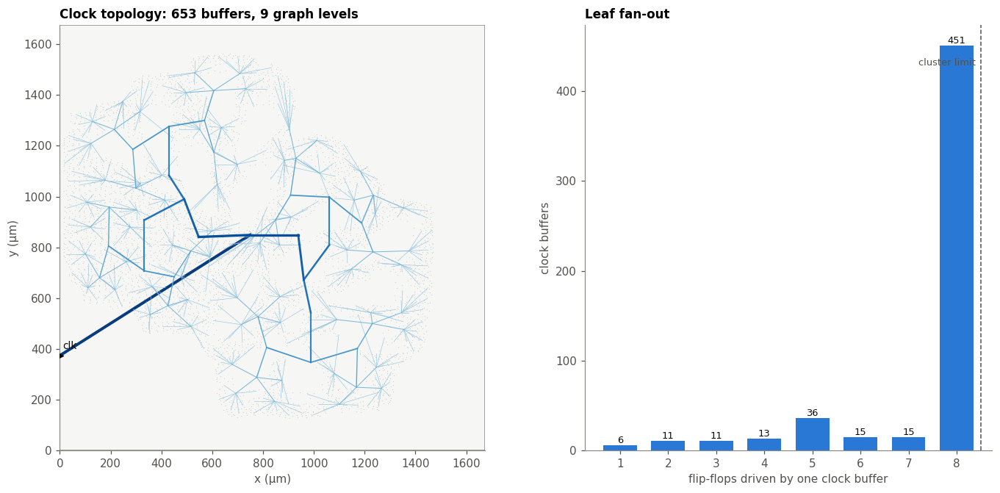

In [ ]:
# @title 16.6d · The clock tree, rebuilt from the final netlist and GDS
import collections

cbuf, driver, loads, sinks = {}, {}, [], collections.Counter()
for m, n, b in CELLS:
    P = pins(b)
    if n.startswith("clkbuf_"):
        cbuf[n] = dict(master=m, I=P.get("I"), Z=P.get("Z"))
        driver[P.get("Z")] = n
    elif n.startswith("clkload"):
        loads.append((n, P.get("I")))
    elif m.startswith(("dff", "sdff", "lat")):
        sinks[P.get("CLK")] += 1
depth = {}


def level(n):
    if n not in depth:
        parent = driver.get(cbuf[n]["I"])
        depth[n] = 0 if parent is None else level(parent) + 1
    return depth[n]


for n in cbuf:
    level(n)
roots = [n for n in cbuf if cbuf[n]["I"] not in driver]
assert (
    len(roots) == 1 and cbuf[roots[0]]["I"] == "clk"
), "Unexpected clock-tree root"

ct = pd.DataFrame(
    [
        (n, depth[n], v["master"].split("_")[-1], sinks[v["Z"]], *POS[n])
        for n, v in cbuf.items()
    ],
    columns=["name", "level", "drive", "flops_driven", "x", "y"],
)
per_level = ct.groupby("level").agg(
    buffers=("name", "size"),
    clkbuf_16=("drive", lambda s: (s == "16").sum()),
    clkbuf_8=("drive", lambda s: (s == "8").sum()),
    clkbuf_4=("drive", lambda s: (s == "4").sum()),
    flops_driven=("flops_driven", "sum"),
)
display(per_level)
fo = ct[ct.flops_driven > 0].flops_driven
pad_returns = [
    p
    for p in [
        "output_out_0_IN",
        "output_out_1_IN",
        "output_out_2_IN",
        "output_out_3_IN",
    ]
    if any(p in pins(b).values() for _, _, b in CELLS)
]
print(
    f"{len(ct)} clock-tree buffers in {ct.level.max() + 1} levels; root "
    f"{ct[ct.level == 0].name.iloc[0]} is driven by the clk terminal."
)
print(
    f"{fo.size} buffers drive all {fo.sum():,} flip-flops: "
    f"{fo.min()}–{fo.max()} flip-flops each (median {fo.median():.0f}); "
    f"CTS_SINK_CLUSTERING_SIZE = {cfg['CTS_SINK_CLUSTERING_SIZE']}."
)
print(
    f"{len(loads)} clkload dummy cells, all on clock-tree nets: "
    f"{sum(i in driver for _, i in loads)} of {len(loads)}. "
    f"Bidirectional-pad input returns with any connection in the netlist: "
    f"{len(pad_returns)} of 4. 16.7c checks the unannotated-net list itself."
)
print(
    f"{(ct.drive == '4').sum()} leaf buffers are clkbuf_4: the clock-buffer "
    f"changes of the ECO (16.8)."
)
assert set(ct.drive) <= {"16", "8", "4"}

fig, (a0, a1) = plt.subplots(
    1, 2, figsize=(13, 6.2), gridspec_kw=dict(width_ratios=[1.35, 1])
)
a0.add_patch(
    Rectangle((0, 0), die_um[2], die_um[3], fc="#f6f6f4", ec=MUTED, lw=1)
)
a0.scatter(ff.x, ff.y, s=0.6, c="#cfcec8", lw=0, rasterized=True)
clk_y = shapes[shapes.pin == "clk"][["y0", "y1"]].mean(axis=1).iloc[0]
cmap = plt.get_cmap("Blues")
L_MAX = ct.level.max()


def shade(lv):
    return cmap(0.95 - 0.55 * lv / max(L_MAX, 1))


root = ct[ct.level == 0].iloc[0]
a0.plot([0, root.x], [clk_y, root.y], color=shade(0), lw=2.6, zorder=3)
for _, r in ct.sort_values("level", ascending=False).iterrows():
    if r.level == 0:
        continue
    px, py = POS[driver[cbuf[r["name"]]["I"]]]
    a0.plot(
        [px, r.x],
        [py, r.y],
        color=shade(r.level),
        lw=2.4 - 2.0 * r.level / L_MAX,
        zorder=3 + (L_MAX - r.level) / 10,
    )
a0.scatter([0], [clk_y], s=40, c=INK, marker=">", zorder=5)
a0.text(12, clk_y + 25, "clk", fontsize=9, color=INK)
a0.set_xlim(0, die_um[2])
a0.set_ylim(0, die_um[3])
a0.set_aspect("equal")
a0.set_xlabel("x (µm)")
a0.set_ylabel("y (µm)")
a0.set_title(f"Clock topology: {len(ct)} buffers, {L_MAX + 1} graph levels")
counts = fo.value_counts().sort_index()
a1.bar(counts.index, counts.values, width=0.7, color=BLUE)
for x, v in counts.items():
    a1.text(x, v, f"{v}", ha="center", va="bottom", fontsize=8.5, color=INK)
a1.axvline(cfg["CTS_SINK_CLUSTERING_SIZE"] + 0.5, color=INK2, lw=1, ls="--")
a1.text(
    cfg["CTS_SINK_CLUSTERING_SIZE"] + 0.4,
    counts.max() * 0.95,
    "cluster limit",
    ha="right",
    fontsize=8.5,
    color=INK2,
)
a1.set_xticks(counts.index)
a1.set_xlabel("flip-flops driven by one clock buffer")
a1.set_ylabel("clock buffers")
a1.set_title("Leaf fan-out")
fig.tight_layout()
fig.savefig(FIG / "16_6_clock_tree.png", bbox_inches="tight")
plt.show()

**Metal coverage by layer.** This measures merged Metal2–Metal5 area divided by slot area. A morphological opening separates broadly retained areas from the residual using a nominal 1.5 µm width scale. The categories are geometric width estimates, not power/signal net classification; narrow supply shapes and wide signal shapes can exist. Metal1 and via coverage are not included in this table.


In [ ]:
# @title 16.6e · Routing-layer coverage (from the GDS)
die_area_dbu2 = (die_um[2] / DBU) * (die_um[3] / DBU)
half = int(round(0.75 / DBU))
rows = []
for lay in ["Metal2", "Metal3", "Metal4", "Metal5"]:
    r = kdb.Region(TOP.begin_shapes_rec(L.find_layer(*LAYER[lay])))
    r.merge()
    wide = (
        r.sized(-half).sized(half) & r
    )  # morphological width proxy; not net classification
    rows.append(
        dict(
            layer=lay,
            total_cover_pct=100 * r.area() / die_area_dbu2,
            wide_pct=100 * wide.area() / die_area_dbu2,
            narrow_pct=100 * (r.area() - wide.area()) / die_area_dbu2,
        )
    )
display(pd.DataFrame(rows).style.hide(axis="index").format(precision=1))

layer,total_cover_pct,wide_pct,narrow_pct
Metal2,7.8,0.0,7.8
Metal3,6.6,0.0,6.6
Metal4,3.0,2.5,0.5
Metal5,2.7,2.5,0.2


### 16.7 Verification of the final layout

The cells below read the committed records of the final run, `A34_Q16_ECO_FULL4_20261015_160735`, stored in `signoff/q16_eco_full4/`: file hashes and LVS, nine-corner timing, the parasitic-annotation list, and a gate-level simulation of the committed netlist. Parsing a committed report does not rerun the tool that produced it. The gate-level regression can be rerun (16.7e).

In [ ]:
# @title 16.7a · File provenance, ECO cells and LVS
# From runs/A34_Q16_ECO_FULL4_20261015_160735/final/,
# also in signoff/q16_eco_full4/final_sha256.json
RECORDED_SHA256 = {
    "gds/chip_core.gd"
    "s": "76091ccb1052a45195f3b30766380e44a60ad4da4ac7ed8a1dac7dec226a87e3",
    "verilog/gl/chip_core.pnl."
    "v": "42821194c1447902f4022622f8daba5143bb3bd526fd32fb5e811a8fcb7a5410",
}
record = json.loads((ECO_DIR / "final_sha256.json").read_text())
for f, want in RECORDED_SHA256.items():
    got = hashlib.sha256((A34 / f).read_bytes()).hexdigest()
    assert (
        got == want == record[f.replace("verilog/gl/", "pnl/")]
    ), f"Artifact checksum mismatch: {f}"
    print(f"{f:28s} sha256 {got} — matches the final-run record")

manifest = json.loads((ECO_DIR / "eco_run_manifest.json").read_text())
gds_master = dict(zip(inst.name, inst.master))
net_master = {n: m for m, n, _ in CELLS}
for name, before, after in manifest["cell_changes"]:
    assert (
        gds_master[name] == after and net_master[name] == after.split("__")[-1]
    ), name
print(
    f"\nAll {len(manifest['cell_changes'])} ECO cell changes are present in "
    f"both the committed GDS and netlist."
)

rep = (A34 / "signoff/lvs/lvs.report").read_text()
run_rep = ECO_DIR / "run_reports/34-netgen-lvs/reports/lvs.netgen.rpt"
assert (
    rep == run_rep.read_text()
), "signoff/lvs/lvs.report is not the final run's report"
devs = re.findall(
    r"Number of devices: (\d+)\s*\|Number of devices: (\d+)", rep
)[-1]
nets = re.findall(r"Number of nets: (\d+)\s*\|Number of nets: (\d+)", rep)[-1]
print(f"\nLVS  layout / schematic devices : {devs[0]} / {devs[1]}")
print(f"LVS  layout / schematic nets    : {nets[0]} / {nets[1]}")
result = re.search(r"Final result: (.+)", rep)
assert result and "Circuits match uniquely." in result.group(
    1
), "LVS result is not a unique match"
assert devs[0] == devs[1] and nets[0] == nets[1]
print(
    "Netgen result:",
    result.group(1).strip(),
    "(committed report of the final run; LVS is not rerun here)",
)

gds/chip_core.gds            sha256 76091ccb1052a45195f3b30766380e44a60ad4da4ac7ed8a1dac7dec226a87e3 — matches the final-run record
verilog/gl/chip_core.pnl.v   sha256 42821194c1447902f4022622f8daba5143bb3bd526fd32fb5e811a8fcb7a5410 — matches the final-run record

All 7 ECO cell changes are present in both the committed GDS and netlist.

LVS  layout / schematic devices : 34107 / 34107
LVS  layout / schematic nets    : 34102 / 34102
Netgen result: Circuits match uniquely. (committed report of the final run; LVS is not rerun here)


**Timing and electrical checks at nine corners.** LibreLane's post-route STA ran after RC extraction of the final routing. It covers three process/voltage/temperature points (slow: ss, 125 °C, 4.5 V; typical: tt, 25 °C, 5.0 V; fast: ff, −40 °C, 5.5 V), each with minimum, nominal and maximum wire parasitics. The constraints are `chip_core.sdc`: 45 ns clock with 0.25 ns uncertainty, 8 ns input and output delays, 3 ns maximum transition, 0.2 pF maximum capacitance and fanout 10. The next cell reads the committed final metrics, cross-checks them against the STA summary report, and plots the worst setup and hold slack per corner. The slack values already include the 0.25 ns clock uncertainty.

The power figure is the recorded vectorless estimate under the flow's default switching activity, not measured silicon power. Its unqualified aggregate metric does not identify a supply voltage here, so it is not converted into a supply-current requirement. A current budget needs the corresponding per-corner power report, voltage, activity assumptions and I/O loads. IR drop is not reported: the analysis had no voltage-source locations, so its numbers do not describe pad-fed supply.

corner,setup_slack_ns,hold_slack_ns,setup_violations,hold_violations,slew_violations,cap_violations,fanout_violations
nom_tt_025C_5v00,+18.819,+0.287,0,0,0,0,0
nom_ss_125C_4v50,+1.272,+0.706,0,0,0,0,0
nom_ff_n40C_5v50,+25.393,+0.093,0,0,0,0,0
min_tt_025C_5v00,+19.424,+0.284,0,0,0,0,0
min_ss_125C_4v50,+1.737,+0.701,0,0,0,0,0
min_ff_n40C_5v50,+25.800,+0.091,0,0,0,0,0
max_tt_025C_5v00,+18.104,+0.291,0,0,0,0,0
max_ss_125C_4v50,+0.550,+0.712,0,0,0,0,0
max_ff_n40C_5v50,+24.911,+0.096,0,0,0,0,0


Worst setup slack +0.550 ns at max_ss_125C_4v50; worst hold slack +0.091 ns at min_ff_n40C_5v50. Values match the STA summary report.


check,value,metrics key
Detailed-router DRC errors,0,route__drc_errors
Magic DRC errors,0,magic__drc_error__count
KLayout DRC errors,0,klayout__drc_error__count
Illegal cell overlaps,0,magic__illegal_overlap__count
Magic vs KLayout GDS differences (XOR),0,design__xor_difference__count
Antenna-violating nets,0,antenna__violating__nets
Antenna-violating pins,0,antenna__violating__pins
LVS errors,0,design__lvs_error__count
Critical disconnected pins,0,design__critical_disconnected_pin__count
"Disconnected pins (the four unused pad input returns, 16.4c)",4,design__disconnected_pin__count


Standard-cell utilization of the core: 36.2 %. Recorded vectorless power estimate: 0.136 W, default activity only; not a supply-current budget.


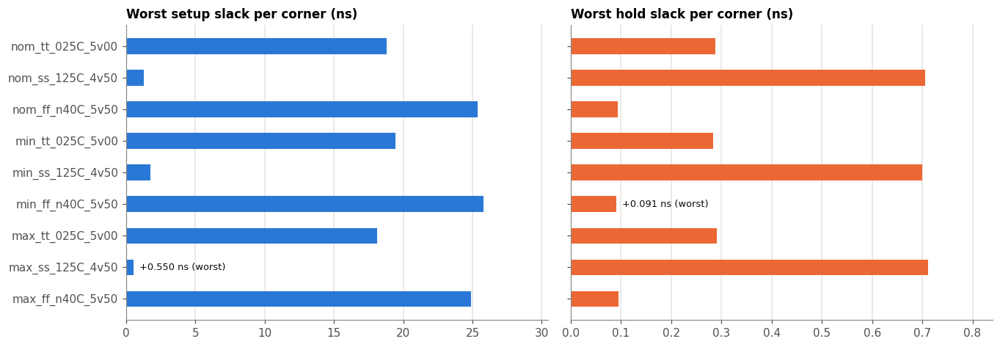

In [ ]:
# @title 16.7b · Nine-corner timing, electrical and physical checks
RUN_DIR = ECO_DIR / "run_reports"
M = RUN_METRICS
CORNERS = [
    f"{rc}_{pvt}"
    for rc in ("nom", "min", "max")
    for pvt in ("tt_025C_5v00", "ss_125C_4v50", "ff_n40C_5v50")
]
rows = []
for c in CORNERS:

    def g(k):
        return M[f"{k}__corner:{c}"]

    rows.append(
        dict(
            corner=c,
            setup_slack_ns=g("timing__setup__ws"),
            hold_slack_ns=g("timing__hold__ws"),
            setup_violations=g("timing__setup_vio__count"),
            hold_violations=g("timing__hold_vio__count"),
            slew_violations=g("design__max_slew_violation__count"),
            cap_violations=g("design__max_cap_violation__count"),
            fanout_violations=g("design__max_fanout_violation__count"),
        )
    )
T = pd.DataFrame(rows)

# Cross-check against the STA summary table printed by the same run
summary = (RUN_DIR / "19-openroad-stapostpnr/summary.rpt").read_text()
for c in CORNERS:
    cols = [
        x.strip() for x in re.search(rf"│ {c}\s*│(.*)│", summary)[1].split("│")
    ]
    hold_ws, setup_ws = float(cols[0]), float(cols[5])
    r = T.set_index("corner").loc[c]
    assert abs(hold_ws - r.hold_slack_ns) < 1e-4 and abs(
        setup_ws - r.setup_slack_ns
    ) < 1e-4, c
display(
    T.style.hide(axis="index").format(
        {"setup_slack_ns": "{:+.3f}", "hold_slack_ns": "{:+.3f}"}
    )
)
viol = [
    "setup_violations",
    "hold_violations",
    "slew_violations",
    "cap_violations",
    "fanout_violations",
]
assert (T[viol] == 0).all().all() and (T.setup_slack_ns > 0).all() and (
    T.hold_slack_ns > 0
).all()
ws, wh = T.loc[T.setup_slack_ns.idxmin()], T.loc[T.hold_slack_ns.idxmin()]
print(
    f"Worst setup slack {ws.setup_slack_ns:+.3f} ns at {ws.corner}; worst "
    f"hold slack {wh.hold_slack_ns:+.3f} ns at {wh.corner}. "
    "Values match the STA summary report."
)

CHECKS = [
    ("route__drc_errors", "Detailed-router DRC errors"),
    ("magic__drc_error__count", "Magic DRC errors"),
    ("klayout__drc_error__count", "KLayout DRC errors"),
    ("magic__illegal_overlap__count", "Illegal cell overlaps"),
    (
        "design__xor_difference__count",
        "Magic vs KLayout GDS differences (XOR)",
    ),
    ("antenna__violating__nets", "Antenna-violating nets"),
    ("antenna__violating__pins", "Antenna-violating pins"),
    ("design__lvs_error__count", "LVS errors"),
    ("design__critical_disconnected_pin__count", "Critical disconnected pins"),
    (
        "design__disconnected_pin__count",
        "Disconnected pins (the four unused pad input returns, 16.4c)",
    ),
    (
        "timing__unannotated_net__count",
        "Unannotated drivers (classified in 16.7c)",
    ),
]
display(
    pd.DataFrame(
        [(d, M[k], k) for k, d in CHECKS],
        columns=["check", "value", "metrics key"],
    ).style.hide(axis="index")
)
assert all(M[k] == 0 for k, _ in CHECKS[:9]) and M[
    "design__disconnected_pin__count"
] == 4
print(
    f"Standard-cell utilization of the core: "
    f"{100 * M['design__instance__utilization__stdcell']:.1f} %. "
    f"Recorded vectorless power estimate: {M['power__total']:.3f} W, default "
    f"activity only; not a supply-current budget."
)

fig, (a0, a1) = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True)
y = range(len(T))
for ax, col, color, title in [
    (a0, "setup_slack_ns", BLUE, "Worst setup slack per corner (ns)"),
    (a1, "hold_slack_ns", ORANGE, "Worst hold slack per corner (ns)"),
]:
    ax.barh(y, T[col], height=0.5, color=color)
    i = T[col].idxmin()
    ax.text(
        T[col][i] + T[col].max() * 0.015,
        i,
        f"{T[col][i]:+.3f} ns (worst)",
        va="center",
        fontsize=8.5,
        color=INK,
    )
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_title(title)
    ax.set_xlim(0, T[col].max() * 1.18)
    ax.grid(axis="x", color=GRID, lw=1)
    ax.set_axisbelow(True)
a0.set_yticks(list(y), T.corner)
a0.invert_yaxis()
fig.tight_layout()
fig.savefig(FIG / "16_7_slack_per_corner.png", bbox_inches="tight")
plt.show()

**Parasitic-annotation check.** STA lists drivers whose nets have no extracted parasitics. Such a list is harmless only if every entry is understood. The next cell reads the list from each corner's committed report and classifies every entry by what the final netlist connects to it.

In [ ]:
# @title 16.7c · Every unannotated driver, classified from the netlist
lists = {}
for c in CORNERS:
    sec = (
        (RUN_DIR / "19-openroad-stapostpnr" / c / "checks.rpt")
        .read_text()
        .split("report_parasitic_annotation -report_unannotated", 1)[1]
    )
    n_found = int(re.search(r"Found (\d+) unannotated drivers\.", sec)[1])
    body = sec.split("unannotated drivers.", 1)[1].split("Found ", 1)[0]
    assert "Found 0 partially unannotated drivers." in sec
    lists[c] = [ln.strip() for ln in body.splitlines() if ln.strip()]
    assert len(lists[c]) == n_found
assert all(
    v == lists[CORNERS[0]] for v in lists.values()
), "lists differ between corners"
entries = lists[CORNERS[0]]

cell_pins = {n: pins(b) for m, n, b in CELLS}
cell_master = {n: m for m, n, _ in CELLS}


def classify(e):
    if re.fullmatch(r"output_out_\d_IN", e):
        return (
            "unused bidirectional-pad input return"
            if e not in connected
            else "UNEXPECTED: port has loads"
        )
    inst_, pin = e.split("/")
    if inst_.startswith("clkload") and pin not in cell_pins[inst_]:
        return "clock-tree dummy load: output pin has no connection by design"
    return "UNEXPECTED"


cls = (
    pd.Series([classify(e) for e in entries])
    .value_counts()
    .rename_axis("driver class")
    .rename("entries")
)
display(cls.to_frame())
dummy_masters = pd.Series(
    [cell_master[e.split("/")[0]] for e in entries if e.startswith("clkload")]
).value_counts()
print(
    "Dummy-load cell types:",
    ", ".join(f"{m} ×{n}" for m, n in dummy_masters.items()),
)
assert not cls.index.str.startswith("UNEXPECTED").any()
print(
    f"{len(entries)} unannotated drivers, the same list at all {len(CORNERS)} "
    f"corners; every entry is a clock-tree "
    "dummy-load output or an unused pad input return, so none sits on a timed "
    "path."
)

,entries
driver class,
clock-tree dummy load: output pin has no connection by design,491
unused bidirectional-pad input return,4


Dummy-load cell types: clkbuf_2 ×380, inv_2 ×27, clkbuf_8 ×26, clkinv_2 ×19, inv_4 ×15, inv_3 ×13, clkinv_4 ×8, clkinv_1 ×2, clkbuf_4 ×1
495 unannotated drivers, the same list at all 9 corners; every entry is a clock-tree dummy-load output or an unused pad input return, so none sits on a timed path.


**Gate-level regression of the committed netlist.** DRC, LVS and STA compare the layout with its own netlist; they do not show that the netlist computes matrix products. `signoff/q16_eco_full4/gl_regression/` drives 33 matrix products through the `chip_core` wrapper, one matrix per reset, on both the RTL and the committed powered netlist with the GF180MCU standard-cell Verilog models. The simulation is zero-delay with no SDF; timing is covered by 16.7b. Packet timing is assisted by internal handshake nets, so this is not a pin-only board/software protocol validation. Each matrix starts with reset. This is a finite sampled comparison, not formal equivalence or an exhaustive functional proof. The implementation retains finite Q16.16 range, possible accumulator overflow, and approximate arithmetic; the reported cases do not establish a universal accuracy bound. Twenty-three cases use identity, all-ones, a permutation and random signed powers of two up to ±32, for which the approximate multiplier is exact, so every RTL output word must equal A·B in Q16.16 bit for bit. Ten cases use random FP16 values; for those, every gate-level word must equal the RTL word. Before simulating, the runner checks the hashes of the final GDS, the netlist and the RTL files; it also runs the counter unit test. The checker exits with an error on any mismatch, missing or unknown (X/Z) output, or timeout, and the results are saved only after a pass. The next cell re-verifies the committed results; 16.7e can rerun the simulation.

In [ ]:
# @title 16.7d · 33 matrix products: committed netlist versus RTL versus A·B
from fractions import Fraction
import struct

GLR = ECO_DIR / "gl_regression"
RES = GLR / "results"
prov = json.loads((RES / "provenance.json").read_text())
summary_gl = json.loads((RES / "check_summary.json").read_text())
for f, want in prov["implementation_sha256"].items():
    assert (
        hashlib.sha256((A34 / f).read_bytes()).hexdigest() == want
    ), f"regression input changed: {f}"
for f, want in prov["test_sha256"].items():
    assert (
        hashlib.sha256((GLR / f).read_bytes()).hexdigest() == want
    ), f"regression test file changed: {f}"
for f in ("verilog/gl/chip_core.pnl.v", "gds/chip_core.gds"):
    assert (
        prov["implementation_sha256"][f] == RECORDED_SHA256[f]
    ), f"regression ran on a different {f}"
assert summary_gl["passed"] and summary_gl["exact_rtl_pass"] == 23 and (
    summary_gl["gl_rtl_pass"] == 33
)
assert "COUNTER PASS" in (RES / "counter.log").read_text()
cases = json.loads((RES / "cases.json").read_text())
assert len(cases) == 33 and sum(c["kind"] == "exact" for c in cases) == 23


def f16(x):
    return struct.unpack("<H", struct.pack("<e", x))[0]


packets = [
    "".join(
        f"{w:04x}"
        for w in [f16(cs["A"][p][k]) for k in range(4)] + [
            f16(cs["B"][k][p]) for k in range(4)
        ]
    )
    for cs in cases
    for p in range(4)
]
assert (
    packets == (RES / "cases.hex").read_text().split()
), "simulated packets do not encode cases.json"

# Reuse the pinned strict parser on complete simulation logs. It rejects
# missing/duplicate/out-of-range/unknown words, missing DONE records and
# timeouts.
import runpy

strict_parse = runpy.run_path(str(GLR / "check.py"))["parse"]
rtl, gl = strict_parse(RES / "rtl.log", len(cases)), strict_parse(
    RES / "gl.log", len(cases)
)


def signed(w):
    return w - 2**32 if w >= 2**31 else w


rows = []
for i, cs in enumerate(cases):
    ref = [
        sum(
            Fraction(cs["A"][r][k]) * Fraction(cs["B"][k][c]) for k in range(4)
        )
        for r in range(4)
        for c in range(4)
    ]
    exact = cs["kind"] == "exact"
    words_ok = None
    if exact:  # exact rational reference, compared word for word
        scaled = [v * 65536 for v in ref]
        assert all(
            v.denominator == 1 and -(2**31) <= v < 2**31 for v in scaled
        )
        words_ok = all(
            rtl[i][e] == (int(scaled[e]) & 0xFFFFFFFF) for e in range(16)
        )
    got = [Fraction(signed(gl[i][e]), 65536) for e in range(16)]
    rows.append(
        dict(
            case=cs["name"],
            kind="exact arithmetic" if exact else "general FP16",
            gate_level_equals_rtl=gl[i] == rtl[i],
            equals_A_times_B=words_ok,
            rel_error_vs_exact=float(
                max(abs(g - r) for g, r in zip(got, ref)) / max(
                    abs(r) for r in ref
                )
            ),
        )
    )
R = pd.DataFrame(rows)
tab = R.groupby("kind", sort=False).agg(
    cases=("case", "size"),
    gate_level_equals_rtl=("gate_level_equals_rtl", "sum"),
    equals_A_times_B=(
        "equals_A_times_B",
        lambda s: int(s.sum()) if s.notna().all() else "—",
    ),
    max_rel_error=("rel_error_vs_exact", "max"),
)
display(tab.style.format({"max_rel_error": "{:.4f}"}))
gen = R[R.kind == "general FP16"].rel_error_vs_exact
n_exact = int(
    R.loc[R.kind == "exact arithmetic", "equals_A_times_B"].astype(bool).sum()
)
assert R.gate_level_equals_rtl.all() and n_exact == 23
print(
    f"Gate level equals RTL in {R.gate_level_equals_rtl.sum()} of {len(R)} "
    f"cases (all 16 Q16.16 words). "
    f"Exact-arithmetic cases equal A·B bit for bit in {n_exact} of "
    f"{(R.kind == 'exact arithmetic').sum()}."
)
print(
    f"General FP16 cases: largest error {100 * gen.min():.1f} "
    f"%–{100 * gen.max():.1f} % of max |A·B| per case, "
    "observed arithmetic error, identical in RTL and gate level; not a "
    "universal bound."
)
print(
    f"Recorded run: Icarus Verilog "
    f"{(RES / 'iverilog_version.txt').read_text().split()[3]}, repository "
    f"commit {prov['git_head'][:7]} "
    "plus the test files of this commit; the counter unit test passed."
)
I_out = [
    [signed(gl[0][4 * r + c]) / 65536 for c in range(4)] for r in range(4)
]
print("Gate-level output for identity × identity:", I_out)

,cases,gate_level_equals_rtl,equals_A_times_B,max_rel_error
kind,,,,
exact arithmetic,23,23,23,0.0000
general FP16,10,10,—,0.0995


Gate level equals RTL in 33 of 33 cases (all 16 Q16.16 words). Exact-arithmetic cases equal A·B bit for bit in 23 of 23.
General FP16 cases: largest error 3.0 %–10.0 % of max |A·B| per case, observed arithmetic error, identical in RTL and gate level; not a universal bound.
Recorded run: Icarus Verilog 13.0, repository commit c98ec31 plus the test files of this commit; the counter unit test passed.
Gate-level output for identity × identity: [[1.0, 0.0, 0.0, 0.0], [0.0, 1.0, 0.0, 0.0], [0.0, 0.0, 1.0, 0.0], [0.0, 0.0, 0.0, 1.0]]


In [ ]:
# @title 16.7e · Optional: rerun the gate-level regression (about 1 min)
# True: fetch the two standard-cell model files (pinned) and run Icarus Verilog
RUN_GL_REGRESSION = False
CELL_MODELS = {
    "gf180mcu_fd_sc_mcu7t5v0."
    "v": "9a21c5f98200acfe77d8ba52067164e0802284dc1c1e117f0e64fb6ac42eb64b",
    "primitives."
    "v": "ccc0f447f71ce35c635e08d49eb0ed77aa2ec91cf31d8e3e45a246114d3cae92",
}
if RUN_GL_REGRESSION:
    import urllib.request

    if shutil.which("iverilog") is None:
        if "google.colab" in sys.modules:
            run(["apt-get", "-qq", "update"])
            run(["apt-get", "-qq", "install", "-y", "iverilog"])
        else:
            raise SystemExit(
                "Install Icarus Verilog (the committed run records version "
                "13.0), then rerun this cell."
            )
    vdir = PDK_ROOT / PDK / "libs.ref/gf180mcu_fd_sc_mcu7t5v0/verilog"
    vdir.mkdir(parents=True, exist_ok=True)
    for f, sha in CELL_MODELS.items():
        p = vdir / f
        if not p.exists():
            url = (
                "https://raw.githubusercontent.com/wafer-space/gf180mcu/"
                f"{PDK_REF}/{PDK}/libs.ref/gf180mcu_fd_sc_mcu7t5v0/verilog/{f}"
            )
            p.write_bytes(urllib.request.urlopen(url, timeout=120).read())
        assert (
            hashlib.sha256(p.read_bytes()).hexdigest() == sha
        ), f"Unexpected cell-model file {f}"
    # Run in a copy so the committed results and the pinned checkout
    # stay untouched.
    RERUN = WORK / "a34_gl_rerun"
    if RERUN.exists():
        shutil.rmtree(RERUN)
    shutil.copytree(A34, RERUN, symlinks=True)
    out = run(
        [
            "bash",
            RERUN / "signoff/q16_eco_full4/gl_regression/run_gl_regression.sh",
            PDK_ROOT,
        ]
    )
    print("\n".join(out.splitlines()[-4:]))
    assert out.rstrip().endswith(
        "REGRESSION PASS: RTL exact cases 23/23; GL vs RTL 33/33"
    )
else:
    print(
        "Skipped (RUN_GL_REGRESSION = False). 16.7d re-verified the committed "
        "results of the recorded run."
    )

Skipped (RUN_GL_REGRESSION = False). 16.7d re-verified the committed results of the recorded run.


### 16.8 Timing closure: run history and the seven-cell ECO

Timing closure of the final design took four runs, all at the 45 ns clock target. The settings below are read from each run's saved configuration (`collect_run_history.py`):

| Run | What changed | Outcome |
|---|---|---|
| `A34_Q16_FIX_FULL1` | Starting settings: clock-buffer distance 225 µm, post-global-route setup margin 0.025 ns (LibreLane default), slew-repair margin 30 % | DRC, LVS and antenna clean; one setup violation of −0.017 ns on a register-to-register path at `max_ss_125C_4v50`; worst hold slack +0.092 ns; 17 slew violations (slow corners) and 2 capacitance violations (maximum-parasitic corners); 1 h 23 min |
| `A34_Q16_FIX_FULL2` | Clock-buffer distance 180 µm; post-global-route setup margin 0.2 ns; post-global-route slew-repair margin 40 % | Stopped before the end of the flow, so it has no final results; FULL3 reused its global-routing database |
| `A34_Q16_FIX_FULL3` | Resumed from FULL2's global-routing database; slew-repair margin back to 30 %, setup margin 0.2 ns kept (the committed configuration) | 0 setup and 0 hold violations; worst setup slack +0.431 ns, worst hold slack +0.091 ns; DRC, LVS and antenna clean; 11 slew and 2 capacitance violations remained |
| `A34_Q16_ECO_FULL4_20261015_160735` | Seven cell changes applied to the FULL3 database saved before detailed routing; then placement legalization, global and detailed routing, extraction and the full set of checks | 0 violations at all 9 corners; worst setup slack +0.550 ns, worst hold slack +0.091 ns; DRC, LVS and antenna clean; 1 h 02 min |

**The ECO.** FULL3 met setup and hold at every corner but still had 11 slew and 2 capacitance violations. The final ECO changed seven cell masters in the FULL3 database saved just before detailed routing. Subsequent legalization and routing could also change other instance positions and wire geometry: seven master substitutions do not mean that only seven physical objects changed.

- Three logic gates were replaced by stronger versions of the same gate (drive 1 → 2 or 4). The stronger alternatives were selected to improve output slew and load-driving capability; the final extracted STA checked their effects on both upstream and downstream timing. The excluded `oai33_2` cell was skipped in favor of the allowed `oai33_4`.
- Four leaf clock buffers were replaced by smaller ones (`clkbuf_8` → `clkbuf_4`). These smaller buffers have less input capacitance, reducing load on the upstream clock nets. Their weaker drive also changes leaf delay and slew. The net change in clock arrival and skew depends on both effects; its direction cannot be assumed from drive strength alone. Setup and hold were therefore rechecked with the final extracted parasitics at all nine corners.

The candidates were first evaluated with STA on FULL3's routed parasitics (`probe_provenance.json`). Before each swap, the ECO script (`apply_seven_cells.tcl`) checked that the old and new cells have identical pins, equal height and equivalent Liberty ports. After the swaps, it checked that each changed cell kept all of its connections and that the instance count and all 72 boundary terminals were unchanged. The flow then legalized placement, re-routed globally and in detail, re-extracted parasitics and re-ran the physical and timing checks reported in 16.7. The 33-case gate-level regression was run separately afterward. Clock-tree synthesis, the resizer and the diode-insertion steps had already run in FULL2 and FULL3 and were skipped, because running them again could have undone the changes.

Because the final layout comes from a resumed run (FULL3 from FULL2) plus an ECO on a saved database, rerunning the configuration file alone does not reproduce it exactly. The scripts, the exact ECO command and the records are in `signoff/q16_eco_full4/`; the team keeps the run checkpoints.

instance,change,kind,flip_flops_clocked,x_um,y_um
_29775_,oai32_1 → oai32_2,"logic gate, stronger",,1124,382
_34089_,oai33_1 → oai33_4,"logic gate, stronger",,262,1205
_29733_,nor3_1 → nor3_2,"logic gate, stronger",,1140,343
clkbuf_leaf_259_clk,clkbuf_8 → clkbuf_4,"clock leaf buffer, smaller",4,816,958
clkbuf_leaf_257_clk,clkbuf_8 → clkbuf_4,"clock leaf buffer, smaller",6,745,864
clkbuf_leaf_541_clk,clkbuf_8 → clkbuf_4,"clock leaf buffer, smaller",3,665,441
clkbuf_leaf_519_clk,clkbuf_8 → clkbuf_4,"clock leaf buffer, smaller",5,605,512


Steps skipped in the ECO run so the changes stay: OpenROAD.CTS, OpenROAD.ResizerTimingPostCTS, OpenROAD.RepairDesignPostGRT, OpenROAD.ResizerTimingPostGRT, Odb.DiodesOnPorts, Odb.HeuristicDiodeInsertion


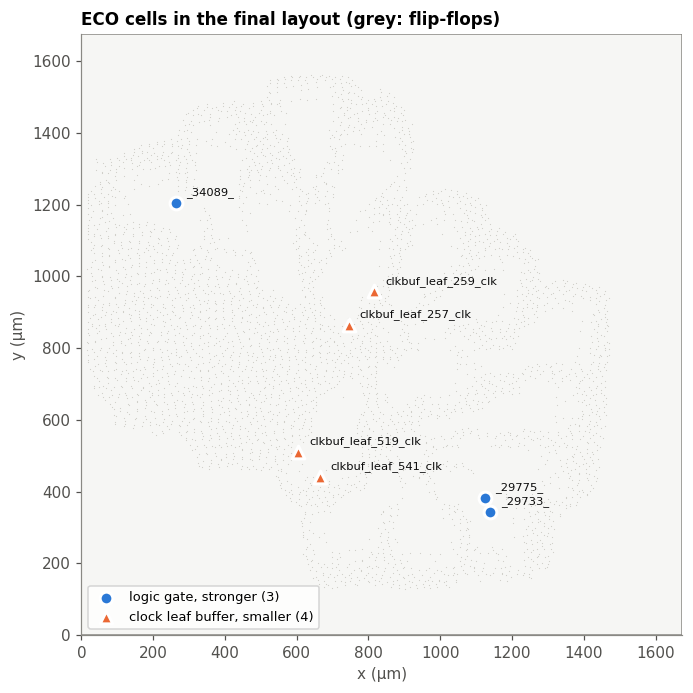

In [ ]:
# @title 16.8 · The seven ECO cell changes and where they are
prov = json.loads((ECO_DIR / "probe_provenance.json").read_text())
applied = re.findall(
    r"A34_APPLIED (\S+) (\S+) (\S+)", (ECO_DIR / "apply.log").read_text()
)
changes = [tuple(x) for x in manifest["cell_changes"]]
assert changes == [tuple(x) for x in applied] == [
    tuple(x) for x in prov["candidate_changes"]
]
assert "A34_LIBERTY_PRECHECK_PASS 7" in (ECO_DIR / "apply.log").read_text()
leaf_sinks = {leaf: int(n) for _, leaf, n in prov["clock_leaf_selection"]}
pos = inst.set_index("name")[["x", "y"]]
rows = []
for name, before, after in changes:
    b, a = before.split("__")[-1], after.split("__")[-1]
    clock = name.startswith("clkbuf_leaf")
    z = cbuf[name]["Z"] if clock else None
    rows.append(
        dict(
            instance=name,
            change=f"{b} → {a}",
            kind=(
                "clock leaf buffer, smaller"
                if clock
                else "logic gate, stronger"
            ),
            flip_flops_clocked=sinks[z] if clock else None,
            x_um=pos.loc[name, "x"],
            y_um=pos.loc[name, "y"],
        )
    )
    if (
        clock
    ):  # the probe's sink count = flip-flops + one dummy load on that leaf net
        assert leaf_sinks[name] == sinks[z] + sum(
            1 for _, i in loads if i == z
        )
eco = pd.DataFrame(rows)
display(
    eco.style.hide(axis="index").format(
        {
            "x_um": "{:.0f}",
            "y_um": "{:.0f}",
            "flip_flops_clocked": lambda v: "" if pd.isna(v) else f"{v:.0f}",
        }
    )
)
print(
    "Steps skipped in the ECO run so the changes stay:",
    ", ".join(manifest["skipped_already_completed_optimization"]),
)

fig, ax = plt.subplots(figsize=(6.4, 6.4))
ax.add_patch(
    Rectangle((0, 0), die_um[2], die_um[3], fc="#f6f6f4", ec=MUTED, lw=1)
)
ax.scatter(ff.x, ff.y, s=0.6, c="#cfcec8", lw=0, rasterized=True)
for kind, color, mk in [
    ("logic gate, stronger", BLUE, "o"),
    ("clock leaf buffer, smaller", ORANGE, "^"),
]:
    d = eco[eco.kind == kind]
    ax.scatter(
        d.x_um,
        d.y_um,
        s=70,
        c=color,
        marker=mk,
        edgecolors="white",
        linewidths=2,
        zorder=4,
        label=f"{kind} ({len(d)})",
    )
for _, r in eco.iterrows():
    ax.annotate(
        r.instance,
        (r.x_um, r.y_um),
        xytext=(7, 5),
        textcoords="offset points",
        fontsize=7.5,
        color=INK,
    )
ax.set_xlim(0, die_um[2])
ax.set_ylim(0, die_um[3])
ax.set_aspect("equal")
ax.set_xlabel("x (µm)")
ax.set_ylabel("y (µm)")
ax.legend(loc="lower left", fontsize=8.5, frameon=True)
ax.set_title("ECO cells in the final layout (grey: flip-flops)")
fig.tight_layout()
fig.savefig(FIG / "16_8_eco_cells.png", bbox_inches="tight")
plt.show()

### 16.9 Recorded implementation commands

The next cell displays two commands: the explicit-PDK invocation of the full flow (with a new run tag for any future reproduction), and the ECO run as recorded in `eco_run_manifest.json`, which starts at detailed placement from the edited database. Displaying them does not launch a flow. A full rerun requires the Nix/LibreLane environment, the full local PDK and about an hour per run on the team's workstation; the ECO step also needs the archived FULL3 checkpoint. The layer-color file used above is not a complete PDK.

In [ ]:
# @title 16.9 · Display the recorded commands; do not execute a flow
print(r"""cd ~/openlane_project/a34-rtl-fix-pd
librelane \
  --manual-pdk \
  --pdk gf180mcuD \
  --pdk-root ~/openlane_project/"""
      r"""chipathon-2026-systolic-ip-core-main-git/gf180mcu \
  --run-tag A34_CAC_REPRO \
  librelane/chip_core_macro.yaml""")
cmd = [
    a.replace("/home/rumali/openlane_project/", "~/openlane_project/")
    for a in manifest["command"]
]
lines, k = [cmd[0]], 1
while k < len(cmd):
    if cmd[k].startswith("--") and k + 1 < len(cmd) and not cmd[
        k + 1
    ].startswith("--"):
        lines.append(f"{cmd[k]} {cmd[k + 1]}")
        k += 2
    else:
        lines.append(cmd[k])
        k += 1
# Quote values with spaces.
lines = [
    (
        f'{ln.split(" ", 1)[0]} "{ln.split(" ", 1)[1]}"'
        if ln.count(" ") > 1
        else ln
    )
    for ln in lines
]
print("\n# ECO run (FULL4), as recorded:\n" + " \\\n  ".join(lines))
print(
    "\nReference commands only. No RTL-to-GDS flow was launched by this cell."
)

cd ~/openlane_project/a34-rtl-fix-pd
librelane \
  --manual-pdk \
  --pdk gf180mcuD \
  --pdk-root ~/openlane_project/chipathon-2026-systolic-ip-core-main-git/gf180mcu \
  --run-tag A34_CAC_REPRO \
  librelane/chip_core_macro.yaml

# ECO run (FULL4), as recorded:
librelane \
  --manual-pdk \
  --pdk gf180mcuD \
  --pdk-root ~/openlane_project/chipathon-2026-systolic-ip-core-main-git/gf180mcu \
  --run-tag A34_Q16_ECO_FULL4_20261015_160735 \
  --from OpenROAD.DetailedPlacement \
  --with-initial-state ~/openlane_project/a34-rtl-fix-pd/verification_results/physical-eco-yoy1al0x/eco_state_in.json \
  --skip OpenROAD.CTS \
  --skip OpenROAD.ResizerTimingPostCTS \
  --skip OpenROAD.RepairDesignPostGRT \
  --skip OpenROAD.ResizerTimingPostGRT \
  --skip Odb.DiodesOnPorts \
  --skip Odb.HeuristicDiodeInsertion \
  --override-config RUN_DRT=true \
  --override-config RUN_FILL_INSERTION=true \
  --override-config RUN_ANTENNA_REPAIR=true \
  --override-config RUN_SPEF_EXTRACTION=true \
  --overr

### 16.10 Lessons learned

**1. A block can be clean and still unconnected.** DRC and LVS of the block alone were clean, yet the slot's power terminals were not joined to the grid. The gap only showed during padframe integration. *Practice:* inspect bridge and via geometry at every power terminal in the final GDS (16.5b) and run `check_power_grid` on the final database.

**2. Flow order decides what a script can see.** The DEF template is applied after power-grid generation in this flow, so the terminals had no Metal2 geometry when PDNGen ran (`PDN-0112`). The fix recreates the terminal rectangles inside the PDN script. The trade-off: those coordinates are copied from this slot's DEF in 2000 units/µm, so the script is specific to A34 and must be updated if the slot changes.

**3. A power-only change produced a large timing regression.** An earlier development run, `A34_PDN_FIX_FULL2`, showed −6.80 ns setup slack. The worst path started at `rst_n`, which the SDC constrains as a timed input with an 8 ns input delay, but register-to-register paths also failed (−3.39 ns), so it was not only a reset issue. Both synthesized netlists had the same 22,518 cell references but different file hashes, and buffer insertion differed (2,886 and 528 buffers versus 2,310 and 36). Re-running the same design with the local PDK selected explicitly gave a fully clean result. The log does not isolate which PDK or parasitic-model difference caused the regression. *Practice:* pass `--manual-pdk --pdk --pdk-root` on every command, compare resolved configurations between runs, and do not treat equal cell counts as proof of identical netlists.

**4. Counts alone do not explain parasitic-annotation warnings.** STA on an earlier run reported 636 unannotated nets, and that list was not preserved, so it could not be re-checked later. For the final run the reports are committed: 16.7c reads all 495 entries and confirms that each is either the output of a clock-tree dummy load (491), which has no load by design, or one of the four unused pad input returns. *Practice:* keep the list with the run and check each driver before declaring the warning benign.

**5. Know exactly what a number measures.** An early check counted 635/641 vias in a left-side region; that is not the number of vias in the bridges, and neither says anything about current capacity. The IR-drop analysis ran without voltage-source locations, and the power figure is a static estimate. This section therefore counts vias inside each bridge shape only (16.5b), does not report IR drop, and labels the power estimate. Electromigration and current-capacity closure were not part of this work.

**6. Physical consistency and functional correctness require different tests.** Clean block-level DRC, LVS and timing show that the layout matches its netlist and meets timing; they say nothing about whether the netlist computes the intended results. *Practice:* pair physical verification with end-to-end regressions that compare every output against a reference model, and run them on the final gate-level netlist too (16.7d). Describe each result only within its tested scope.

**7. Flow settings closed timing; a small, recorded ECO closed the electrical rules.** The first run of the final design missed setup by 17 ps and had 17 slew and 2 capacitance violations. A larger post-global-route setup margin and shorter clock-buffer spacing gave +0.431 ns of setup slack, but 11 slew and 2 capacitance violations remained. Seven cell changes on a saved database, followed by full re-routing, extraction and signoff, cleared them and left +0.550 ns of worst setup slack. The cost is reproducibility: the configuration file alone no longer rebuilds the layout. *Practice:* commit the exact cell changes, scripts, command and logs, check the changed cells in the final GDS and netlist (16.7a), and keep the checkpoints the ECO started from.

### 16.11 Tools, versions and references

| Item | Version / source |
|---|---|
| LibreLane | 3.0.0, pinned by `flake.nix` in the team repository: https://github.com/librelane/librelane |
| OpenROAD | `dcf36133a369abc8f3c5e5738cd4d82e4903c0e0`, as recorded by the run; packaged by LibreLane 3.0.0 (Nix) |
| Yosys, Magic, KLayout, Netgen | As packaged by LibreLane 3.0.0 (Nix) |
| GF180MCU PDK | Historical run used the team's explicit local `gf180mcuD` installation. Its exact tree hash was not preserved in the supplied evidence. Analysis colors are pinned to wafer-space tag 1.8.0 / commit `7636804aa430fed842535e3d660f94de8ac4754c`: https://github.com/wafer-space/gf180mcu |
| Standard cells | `gf180mcu_fd_sc_mcu7t5v0` (7-track, 5 V) |
| GF180MCU I/O cells | https://gf180mcu-pdk.readthedocs.io/en/latest/IPs/IO/gf180mcu_fd_io/digital.html |
| Project template | wafer-space `gf180mcu-project-template` (Leo Moser), Apache-2.0 |
| Slot DEF template (`A34_ACE.def`) | Provided by the IEEE SSCS PICO Chipathon 2026 organizers |
| Gate-level regression | Icarus Verilog 13.0 (devel) from the project Nix environment for the recorded run; Python 3.14.6 and NumPy 2.5.1 are recorded for its checker. Analysis-package versions are listed separately below. GF180MCU standard-cell Verilog models (wafer-space tag 1.8.0); Python/NumPy checker; `signoff/q16_eco_full4/gl_regression/` |
| Analysis in this section | KLayout Python API, pandas, matplotlib, NumPy (versions printed in 16.1) |

## 17. References and attribution

1. [SiliconForge project repository](https://github.com/Waleed99i/chipathon-2026-systolic-ip-core): implementation, README, design figures, waveform screenshots and module testbenches.
2. **A34-Schematic Review.pdf**, supplied by the team: system, MAC, PE, counter, register, feeders, interfaces, datapaths and control design. Figures reproduced from corresponding assets in [docs/](https://github.com/Waleed99i/chipathon-2026-systolic-ip-core/tree/main/docs).
3. The two supplied images: logical packet interface and chip-core RTL hierarchy, included in this notebook.
4. [IEEE SSCS Code-a-Chip repository](https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io) and [award information](https://sscs.ieee.org/membership/awards/ieee-sscs-code-a-chip-travel-grant-awards/): submission format and program rules.
5. [ISSCC25 accepted notebooks](https://github.com/sscs-ose/sscs-ose-code-a-chip.github.io/tree/main/ISSCC25/accepted_notebooks): examples reviewed for notebook organization. Their code is not reused here.
6. [Icarus Verilog](https://github.com/steveicarus/iverilog), [GTKWave](https://gtkwave.github.io/), [Jupyter](https://jupyter.org/) and [Matplotlib](https://matplotlib.org/): simulation, waveform viewing, notebook presentation and plotted results.

The team's RTL and schematic figures retain their original attribution. The template and padframe contributions are recorded in UPSTREAM_CREDITS.md, UPSTREAM_AUTHORS.md and UPSTREAM_NOTICE. The notebook and supporting additions use Apache-2.0. The complete LICENSE, NOTICE and upstream attribution files are retained in the embedded reproduction archive.